# Setup

In [1]:
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo
import hashlib
import importlib.metadata
import json
import os
import platform
import shutil
import sys
import tempfile
import time

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "trick-of-the-tail-mpl"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
from scipy.stats import chi2
from arch.univariate import ConstantMean, GARCH, StudentsT
from IPython.display import Image, Markdown, display

Matplotlib is building the font cache; this may take a moment.


All imports live in this opening cell so dependencies are explicit up front:

- **Headless Matplotlib setup**: `MPLCONFIGDIR` points to a temporary folder (`trick-of-the-tail-mpl`) and `matplotlib.use("Agg")` forces off-screen PNG rendering before `pyplot` loads, avoiding font-cache permission issues or GUI popups in batch runs.
- **Numerical and econometric stack**: `numpy` and `pandas` handle array broadcasting and FRED CSV tables; `scipy.stats.chi2` provides survival probabilities (`chi2.sf`) for Kupiec and Christoffersen likelihood-ratio coverage tests; `arch.univariate` supplies `ConstantMean`, `GARCH` (symmetric `o=0` and asymmetric GJR `o=1`), and `StudentsT` innovations for full-sample volatility filtering.
- **Runtime checks and inline display**: `hashlib`, `json`, `importlib.metadata`, `platform`, and `psutil` verify SHA-256 file hashes, log package versions, and enforce the memory ceiling; `IPython.display` renders the exported PNG bytes inline.

In [2]:
class CFG:
    mode = os.environ.get("TAILS_MODE", "replay")
    data_folder = Path("data")
    sources_folder = Path("sources")
    calibration_folder = Path("calibration")
    graph_folder = Path("graphs")
    timezone = "Europe/Amsterdam"
    execution_started_at = datetime.now(ZoneInfo(timezone))
    execution_date = execution_started_at.strftime("%d%m")
    run_folder = Path(
        os.environ.get(
            "TAILS_RUN",
            json.loads(Path("latest-run.json").read_text())["path"]
            if Path("latest-run.json").exists()
            else "runs/missing",
        )
    )
    SEED = 20261107
    series_order = ["EUR", "GBP", "JPY"]
    date_bounds = ("1999-01-04", "2025-12-31")
    prefix_cutoff = "2008-12-31"
    scored_start = "2009-01-01"
    min_prefix_obs = 2000

    # Interior inference settings (Sections 4-5)
    m = 200
    h = 0.10
    J = 20
    hac_floor = 0.05
    grid_bounds = (0.15, 0.85)
    grid_points = 41
    grid = np.round(np.linspace(grid_bounds[0], grid_bounds[1], grid_points), 10)
    gamma_0 = 0.3
    calibration_reps = 5000
    calibration_chunk = 250
    cutoff_bootstrap_reps = 1000
    familywise_alpha = 0.05
    eur_robustness = [
        ("Baseline", 200, 0.10, 20),
        ("m=150", 150, 0.10, 20),
        ("m=250", 250, 0.10, 20),
        ("h=0.075", 200, 0.075, 20),
        ("h=0.125", 200, 0.125, 20),
        ("J=10", 200, 0.10, 10),
        ("J=30", 200, 0.10, 30),
    ]

    # Volatility filter settings (retrospective interior inference only)
    stationarity_margin = 1e-6
    slsqp_ftol = 1e-9
    slsqp_maxiter = 1000
    init_diag_obs = 250

    # Past-only chronological forecasting settings (Sections 7-8)
    forecast_m = 200
    forecast_h = 0.10
    rolling_window = 2500
    tail_probs = [0.01, 0.025]
    arms = ["A_static", "B_dyn_thresh", "C_dyn_both", "D_rect_hill"]
    arm_labels = {
        "A_static": "A: Static (2008)",
        "B_dyn_thresh": "B: Dynamic b, fixed gamma",
        "C_dyn_both": "C: Dynamic b + gamma",
        "D_rect_hill": "D: Rectangular Hill",
    }
    block_lengths = [20, 10, 60]
    forecast_bootstrap_reps = 5000
    violation_roll_window = 250

    # Resource guards and publication dimensions
    compute_budget_seconds = 1800
    rss_limit_bytes = 4 * 2**30
    img_dim1, img_dim2 = 10.8, 6.2
    table_dim1, table_dim2 = 11.8, 4.5
    export_dpi = 180
    colors = {
        "raw": "#17678e",
        "garch": "#2a7f62",
        "gjr": "#6a4c93",
        "projection": "#b85d19",
        "A": "#7a869a",
        "B": "#1f77b4",
        "C": "#c0392b",
        "D": "#d68910",
    }
    packages = [
        "numpy",
        "pandas",
        "scipy",
        "arch",
        "matplotlib",
        "psutil",
        "ipython",
        "nbformat",
        "nbclient",
        "ipykernel",
        "jupyter-client",
        "Pillow",
    ]


if CFG.mode not in ("live", "replay"):
    raise ValueError("CFG.mode must be 'live' or 'replay'")
plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)

`CFG` keeps every path, seed, bandwidth, threshold count, optimizer tolerance, and backtest window in one place:

- **Execution mode and run tracking**: `TAILS_MODE` selects `replay` (default; verifies saved `.npz` evidence and recomputes estimators and diagnostics without refitting `arch` or regenerating Monte Carlo draws) or `live` (executes a fresh study under `runs/`). `execution_date` (`ddmm` in `Europe/Amsterdam`) stamps exported asset filenames.
- **Currency sample split (`1999-01-04` to `2025-12-31`)**: `EUR`, `GBP`, and `JPY` each provide `6,769` daily log losses. The prefix through `2008-12-31` (`2,516` observations; minimum `2,000`) anchors static baseline parameters; `2009-01-01` through `2025-12-31` (`4,253` common dates) is the out-of-sample forecasting window.
- **Interior tail inference (`Sections 4–6` of Li & Peng)**: Local upper-tail estimation uses `m = 200` extreme order statistics ($q = m/n \approx 2.95\%$), Epanechnikov half-window bandwidth `h = 0.10` (effective local tail scale $mh = 20$), Bartlett HAC lag truncation `J = 20` with variance floor `0.05`, and a 41-point interior grid $u \in [0.15, 0.85]$. `eur_robustness` perturbs $m \in \{150, 250\}$, $h \in \{0.075, 0.125\}$, and $J \in \{10, 30\}$ one factor at a time.
- **Volatility filters and chronological forecasting (`Sections 7–8`)**: GARCH/GJR filters apply only to retrospective interior series (`stationarity_margin = 1e-6`, `slsqp_ftol = 1e-9`). Real-time forecasting evaluates one-sided endpoint estimates ($u = 1, m = 200, h = 0.10$) at tail probabilities $p \in \{0.01, 0.025\}$ across four arms (`A_static`, `B_dyn_thresh`, `C_dyn_both`, `D_rect_hill`), comparing expanding and 2,500-day rolling windows with 5,000-draw paired moving-block bootstraps ($L \in \{20, 10, 60\}$).

# Utils

## Evidence, checksums and resource guards

In [3]:
def json_write(path, value):
    target = Path(path)
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def sha_obj(value):
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


def guard(start):
    elapsed = time.monotonic() - start
    rss = psutil.Process().memory_info().rss
    if elapsed > CFG.compute_budget_seconds or rss > CFG.rss_limit_bytes:
        raise RuntimeError(f"Resource ceiling exceeded: elapsed={elapsed:.3f}s, rss={rss} bytes")


def rng_for(phase, group, sub=0, rep=0):
    seq = np.random.SeedSequence([CFG.SEED, int(phase), int(group), int(sub), int(rep)])
    return np.random.Generator(np.random.PCG64(seq))


def protocol():
    manifest = json.loads((CFG.data_folder / "source-manifest.json").read_text())
    return dict(
        package="trick-of-the-tail",
        scope="real_data_only_synthetic_null_and_power_omitted",
        seed=CFG.SEED,
        rng_schema=dict(
            engine="PCG64(SeedSequence([SEED, phase, group, sub, rep]))",
            pilot="[20261107, 10, group, 0, rep]",
            pivotal_calibration="[20261107, 20, uint32(spec_sha256[:8]), 0, rep]",
            cutoff_bootstrap="[20261107, 50, uint32(spec_sha256[:8]), 1, 0]",
            forecast_block_bootstrap="[20261107, 50, 100+10*win+series, 10*prob+pair, block_idx]",
            joint_block_bootstrap="[20261107, 50, 300+10*win, prob, block_idx]",
        ),
        series_order=list(CFG.series_order),
        date_bounds=list(CFG.date_bounds),
        prefix_cutoff=CFG.prefix_cutoff,
        scored_start=CFG.scored_start,
        min_prefix_obs=CFG.min_prefix_obs,
        source_hashes={code: manifest["series"][code]["sha256"] for code in CFG.series_order},
        paper_pdf_sha256=manifest["source_documents"]["paper_pdf"]["sha256"],
        plan_v2_sha256=manifest["source_documents"]["planning_spec_v2"]["sha256"],
        exposure_rule="loss_t = -100 * diff(log(USD_per_foreign_currency)); signed_return_t = -loss_t; invert DEXJPUS before log-diff",
        estimator=dict(
            m=CFG.m,
            h=CFG.h,
            J=CFG.J,
            hac_floor=CFG.hac_floor,
            grid_bounds=list(CFG.grid_bounds),
            grid_points=CFG.grid_points,
            grid=[float(u) for u in CFG.grid],
            kernel="epanechnikov_0.75_over_h",
            standardized_distance="(n * u - t) / (n * h)",
            support="abs((n * u - t) / (n * h)) < 1.0",
            quantile="weighted_empirical_cdf_left_inverse_((n-m)*total_weight)/n",
            exceedance="strict_greater_than_positive_threshold",
            quadrature="numpy.trapezoid",
            projection="precision_weighted_integral_gamma_over_S",
        ),
        calibration=dict(
            generator="iid_unit_scale_pareto_(1-U)^(-gamma_0)",
            gamma_0=CFG.gamma_0,
            reps=CFG.calibration_reps,
            band_centering="generating_gamma_0_0.3",
            band_scope="simultaneous_across_41_grid_points_of_single_target_path",
            band_quantile="numpy.quantile_0.95_method_higher",
            test_centering="precision_weighted_projection_gamma_tilde",
            pvalue_rule="(1 + sum(cal_lambda >= obs_lambda)) / (B + 1)",
            cutoff_bootstrap_reps=CFG.cutoff_bootstrap_reps,
            holm_family_slots=9,
            holm_unavailable_slot_rule="internal_p_1.0_reported_decision_NA",
            familywise_alpha=CFG.familywise_alpha,
        ),
        eur_robustness=[
            dict(label=label, m=m_val, h=h_val, J=j_val)
            for label, m_val, h_val, j_val in CFG.eur_robustness
        ],
        volatility_filters=dict(
            package="arch",
            mean="ConstantMean(rescale=False)",
            models=["GARCH(p=1,o=0,q=1,power=2.0)", "GARCH(p=1,o=1,q=1,power=2.0)"],
            distribution="StudentsT",
            backcast="ewma_0.94_tau_min_75_n_on_sample_demeaned_returns",
            schedule="two_attempt_slsqp_tol_None_ftol_1e-9_maxiter_1000",
            tie_breaker="select_attempt_2_iff_valid_and_ll2_gt_ll1_plus_1e-10_else_attempt_1",
            stationarity_margin=CFG.stationarity_margin,
            nu_min=2.05 + 1e-5,
            variance_positivity="alpha + gamma_lev >= -1e-9",
            init_diag_obs=CFG.init_diag_obs,
            role="retrospective_interior_inference_only",
        ),
        forecasting=dict(
            target="raw_signed_losses_only",
            endpoint_u=1.0,
            m=CFG.forecast_m,
            h=CFG.forecast_h,
            windows=["expanding", f"rolling_{CFG.rolling_window}"],
            static_anchor="common_2008_prefix_kernel_endpoint",
            arms=list(CFG.arms),
            tail_probs=list(CFG.tail_probs),
            loss="pinball_tau_minus_indicator_y_lt_Q_times_y_minus_Q",
            violation="strict_y_gt_Q",
            failure_policy="retain_all_4253_origins_mark_contrast_incomplete_if_any_origin_invalid",
            coverage_tests="kupiec_uc_and_christoffersen_ind_0log0_eq_0_NA_if_any_marginal_state_zero",
            primary_contrast="mean(loss_C - loss_B)_EUR_p0.01_expanding",
            bootstrap_kind="paired_circular_moving_block",
            bootstrap_reps=CFG.forecast_bootstrap_reps,
            block_lengths=list(CFG.block_lengths),
            bootstrap_quantile="numpy.quantile_0.025_0.975_method_linear",
            violation_roll_window=CFG.violation_roll_window,
        ),
        asset_sequence=[
            "01_tabler_scope_and_claim_boundaries",
            "02_tabler_filter_and_hac_diagnostics",
            "03_graph_eur_raw_path_and_band",
            "04_graph_eur_garch_path_and_band",
            "05_graph_eur_gjr_path_and_band",
            "06_tabler_baseline_nine_test_holm_family",
            "07_graph_eur_rolling_250_violations",
            "08_graph_eur_primary_cumulative_loss_diff",
            "09_tabler_eur_abcd_forecast_scores",
            "10_graph_multiseries_window_c_minus_b_intervals",
            "11_tabler_supporting_fx_window_block_summary",
            "12_tabler_eur_m_h_J_robustness",
            "13_tabler_calibration_cutoffs_and_workload",
        ],
        compute_budget_seconds=CFG.compute_budget_seconds,
        rss_limit_bytes=CFG.rss_limit_bytes,
    )

These helpers handle deterministic seeding, file checksums, runtime limits, and the frozen study manifest:

- **Strict JSON and SHA-256 hashing**: `json_write` rejects `NaN`/`Inf` values (`allow_nan=False`) so bad floats fail immediately; `sha` hashes raw file bytes; and `sha_obj` hashes canonicalized JSON strings (`sort_keys=True`) so every calibration setting maps to a deterministic cache key.
- **Resource circuit breaker (`guard`)**: Checks elapsed monotonic time and process RSS against `CFG.compute_budget_seconds` (`1,800s`) and `CFG.rss_limit_bytes` (`4 GiB`).
- **Disjoint RNG streams (`rng_for`)**: Builds independent `PCG64` generators from `SeedSequence([20261107, phase, group, sub, rep])`, keeping pilot draws (`phase=10`), pivotal Pareto calibrations (`phase=20`), and bootstrap resamples (`phase=50`) completely separate.
- **Study contract (`protocol`)**: Snapshots all source hashes, sign conventions, kernel/quantile rules, GARCH/GJR tie-breakers, 9-slot Holm rules, and forecast scoring formulas. Replay mode checks `frozen["configuration"] == protocol()` before loading any run.

## Currency data and exposure alignment

In [4]:
def load_fx_panel():
    manifest_path = CFG.data_folder / "source-manifest.json"
    manifest = json.loads(manifest_path.read_text())
    paper_doc = manifest["source_documents"]["paper_pdf"]
    plan_doc = manifest["source_documents"]["planning_spec_v2"]
    if sha(paper_doc["path"]) != paper_doc["sha256"]:
        raise ValueError("Verified paper PDF checksum mismatch")
    if sha(plan_doc["path"]) != plan_doc["sha256"]:
        raise ValueError("Reference v2 plan checksum mismatch")

    panel = {}
    summaries = []
    scored_date_sets = []
    lo_date, hi_date = CFG.date_bounds

    for code in CFG.series_order:
        meta = manifest["series"][code]
        csv_path = Path(meta["filename"])
        if sha(csv_path) != meta["sha256"]:
            raise ValueError(f"FRED cache checksum mismatch for {code}: {csv_path}")
        raw = pd.read_csv(csv_path)
        if len(raw.columns) != 2:
            raise ValueError(f"Unexpected column structure in {csv_path}")
        raw.columns = ["date_str", "quote"]
        raw["date"] = pd.to_datetime(raw["date_str"], format="%Y-%m-%d", errors="raise")
        raw["quote"] = pd.to_numeric(raw["quote"], errors="coerce")
        raw = raw.loc[(raw["date_str"] >= lo_date) & (raw["date_str"] <= hi_date)].copy()
        missing = int(raw["quote"].isna().sum())
        quotes = raw.dropna(subset=["quote"]).sort_values("date").reset_index(drop=True)
        if quotes["date"].duplicated().any() or not quotes["date"].is_monotonic_increasing:
            raise ValueError(f"Duplicate or non-increasing quote dates in {code}")
        quote_vals = quotes["quote"].to_numpy(dtype=float)
        if not np.isfinite(quote_vals).all() or (quote_vals <= 0.0).any():
            raise ValueError(f"Nonpositive or nonfinite quote levels in {code}")

        usd_per_unit = (1.0 / quote_vals) if meta["invert_quote"] else quote_vals
        losses = -100.0 * np.diff(np.log(usd_per_unit))
        returns = -losses
        loss_dates = quotes["date"].to_numpy()[1:]
        loss_date_strs = quotes["date_str"].to_numpy(dtype=str)[1:]
        if not np.isfinite(losses).all() or len(losses) < 4000:
            raise ValueError(f"Invalid loss series for {code}")

        prefix_mask = loss_date_strs <= CFG.prefix_cutoff
        scored_mask = loss_date_strs >= CFG.scored_start
        prefix_len = int(prefix_mask.sum())
        scored_len = int(scored_mask.sum())
        if prefix_len < CFG.min_prefix_obs:
            raise ValueError(f"Initial prefix for {code} has {prefix_len} < {CFG.min_prefix_obs} observations")
        if prefix_len + scored_len != len(losses) or not np.all(prefix_mask[:prefix_len]) or not np.all(scored_mask[prefix_len:]):
            raise ValueError(f"Non-contiguous prefix/scored split in {code}")

        scored_dates = loss_date_strs[scored_mask]
        scored_date_sets.append(set(scored_dates.tolist()))
        info = dict(
            series=code,
            fred_id=meta["fred_id"],
            quote_transform=meta["quote_transform"],
            invert_quote=bool(meta["invert_quote"]),
            sha256=meta["sha256"],
            raw_rows=int(len(raw)),
            missing_quotes=missing,
            valid_quotes=int(len(quotes)),
            losses=int(len(losses)),
            prefix_losses=prefix_len,
            scored_losses=scored_len,
            zero_losses=int((losses == 0.0).sum()),
            positive_losses=int((losses > 0.0).sum()),
            first_loss_date=str(loss_date_strs[0]),
            last_prefix_date=str(loss_date_strs[prefix_len - 1]),
            first_scored_date=str(loss_date_strs[prefix_len]),
            last_scored_date=str(loss_date_strs[-1]),
        )
        summaries.append(info)
        panel[code] = dict(
            meta=meta,
            summary=info,
            dates=loss_dates,
            date_strs=loss_date_strs,
            losses=losses,
            returns=returns,
            prefix_len=prefix_len,
            scored_len=scored_len,
            scored_date_strs=scored_dates,
            scored_dates=loss_dates[scored_mask],
        )

    common_scored_dates = sorted(set.intersection(*scored_date_sets))
    if not common_scored_dates:
        raise ValueError("Empty common scored date intersection across currency series")
    for code in CFG.series_order:
        index_map = {d: idx for idx, d in enumerate(panel[code]["scored_date_strs"])}
        panel[code]["common_scored_indices"] = np.array([index_map[d] for d in common_scored_dates], dtype=int)

    return panel, pd.DataFrame(summaries), common_scored_dates

`load_fx_panel` verifies source hashes, aligns currency quote conventions, and partitions the prefix and scored windows:

- **Checksum verification**: Confirms that the paper PDF, planning specification, and all three FRED H.10 CSVs (`DEXUSEU.csv`, `DEXUSUK.csv`, `DEXJPUS.csv`) match the SHA-256 digests pinned in `data/source-manifest.json`.
- **Unified USD exposure sign**: Drops `273` non-trading `.` entries per series without interpolation (`6,770` valid quotes $\rightarrow$ `6,769` daily log changes). `DEXUSEU` and `DEXUSUK` are published as USD per foreign unit, while `DEXJPUS` (yen per USD) is inverted first (`1.0 / quote`) so `loss_t = -100 * diff(log(USD_per_foreign_unit))` always measures positive percentage losses on a long foreign-currency position in USD (`returns = -losses`).
- **Prefix/scored split and date intersection**: Splits each series into the `<= 2008-12-31` prefix (`2,516` losses) and `>= 2009-01-02` scored window (`4,253` losses), verifying that all three currencies share the exact same `4,253` scored dates before joint block bootstrapping.

## Reference and vectorized local tail estimators

In [5]:
def weighted_quantile_1d(x, weights, q=None, m_int=None, n_int=None):
    x_arr = np.asarray(x, dtype=float)
    w_arr = np.asarray(weights, dtype=float)
    if x_arr.ndim != 1 or w_arr.shape != x_arr.shape:
        raise ValueError("weighted_quantile_1d expects matching 1D arrays")
    if m_int is not None and n_int is not None:
        if not (0 < int(m_int) < int(n_int)):
            raise ValueError("Invalid integer (m_int, n_int) in weighted_quantile_1d")
    elif q is None or not (0.0 < float(q) < 1.0):
        raise ValueError("Invalid quantile fraction q in weighted_quantile_1d")
    if not np.isfinite(x_arr).all() or not np.isfinite(w_arr).all() or (w_arr < 0.0).any():
        raise ValueError("Invalid array values in weighted_quantile_1d")

    order = np.argsort(x_arr, kind="stable")
    cum_w = np.cumsum(w_arr[order])
    total_w = float(cum_w[-1])
    if total_w <= 0.0:
        raise ValueError("Zero total weight in local window")
    # Rational ((n - m) * total_w) / n avoids +1 ULP drift when q = m / n is rational.
    target = (((int(n_int) - int(m_int)) * total_w) / int(n_int)) if (m_int is not None and n_int is not None) else ((1.0 - float(q)) * total_w)
    pos = int(np.argmax(cum_w >= target))
    return float(x_arr[order[pos]])


def fit_local_reference(x, grid, m, h, J, floor=0.05):
    x_arr = np.asarray(x, dtype=float)
    grid_arr = np.asarray(grid, dtype=float)
    n = len(x_arr)
    m_i = int(m)
    if n < 10 or not np.isfinite(x_arr).all() or not (0 < m_i < n) or h <= 0.0 or J < 1:
        raise ValueError("Invalid parameters for fit_local_reference")

    t_idx = np.arange(1, n + 1, dtype=float)
    nh = n * float(h)
    k_pts = len(grid_arr)
    gamma_path = np.empty(k_pts, dtype=float)
    b_path = np.empty(k_pts, dtype=float)
    s_raw_path = np.empty(k_pts, dtype=float)
    s_path = np.empty(k_pts, dtype=float)
    floor_flags = np.zeros(k_pts, dtype=bool)
    eff_exceed = np.empty(k_pts, dtype=float)
    raw_exceed = np.empty(k_pts, dtype=int)

    for idx, u in enumerate(grid_arr):
        dist = (n * float(u) - t_idx) / nh
        inside = np.abs(dist) < 1.0
        if not inside.any():
            raise ValueError(f"Empty kernel support at u={u}")
        w = np.where(inside, (0.75 / h) * (1.0 - dist * dist), 0.0)
        b_hat = weighted_quantile_1d(x_arr, w, m_int=m_i, n_int=n)
        if not np.isfinite(b_hat) or b_hat <= 0.0:
            raise ValueError(f"Nonpositive local threshold b_hat={b_hat} at u={u}")

        exceeds = x_arr > b_hat
        raw_cnt = int(exceeds.sum())
        denom_hill = float(np.sum(w * exceeds))
        if raw_cnt == 0 or denom_hill <= 0.0:
            raise ValueError(f"No strict positive exceedances at u={u}")

        # Evaluate logarithms strictly on positive observations exceeding b_hat > 0.
        log_exc = np.zeros(n, dtype=float)
        log_exc[exceeds] = np.log(x_arr[exceeds] / b_hat)
        gamma_hat = float(np.sum(w * log_exc) / denom_hill)
        if not np.isfinite(gamma_hat) or gamma_hat <= 0.0:
            raise ValueError(f"Invalid local Hill estimate gamma_hat={gamma_hat} at u={u}")

        z_hat = np.where(exceeds, log_exc - gamma_hat, 0.0)
        a = w * z_hat
        d_u = float(np.sum(a * a))
        if not np.isfinite(d_u) or d_u <= 0.0:
            raise ValueError(f"Zero or invalid HAC denominator D(u)={d_u} at u={u}")

        lag_sum = 0.0
        for j in range(1, J + 1):
            taper = 1.0 - (j / J)
            if taper != 0.0 and j < n:
                lag_sum += taper * float(np.sum(a[:-j] * a[j:]))
        s_raw = 1.0 + 2.0 * lag_sum / d_u
        if not np.isfinite(s_raw):
            raise ValueError(f"Nonfinite unfloored HAC factor at u={u}")

        floored = bool(s_raw < floor)
        s_val = float(max(s_raw, floor))
        gamma_path[idx] = gamma_hat
        b_path[idx] = b_hat
        s_raw_path[idx] = s_raw
        s_path[idx] = s_val
        floor_flags[idx] = floored
        eff_exceed[idx] = denom_hill * h
        raw_exceed[idx] = raw_cnt

    denom_proj = float(np.trapezoid(1.0 / s_path, grid_arr))
    if denom_proj <= 0.0 or not np.isfinite(denom_proj):
        raise ValueError("Invalid projection denominator")
    gamma_tilde = float(np.trapezoid(gamma_path / s_path, grid_arr) / denom_proj)
    if gamma_tilde <= 0.0 or not np.isfinite(gamma_tilde):
        raise ValueError("Invalid precision-weighted projection gamma_tilde")
    t_stat = float(np.trapezoid(((gamma_path - gamma_tilde) ** 2) / s_path, grid_arr))
    lambda_stat = float((m_i * h * t_stat) / ((gamma_tilde ** 2) * (3.0 / 5.0)))
    se_path = gamma_path * np.sqrt(s_path * (3.0 / 5.0) / (m_i * h))

    return dict(
        gamma_path=gamma_path,
        b_path=b_path,
        s_raw_path=s_raw_path,
        s_path=s_path,
        floor_flags=floor_flags,
        floor_count=int(floor_flags.sum()),
        eff_exceed=eff_exceed,
        raw_exceed=raw_exceed,
        gamma_tilde=gamma_tilde,
        t_stat=t_stat,
        lambda_stat=lambda_stat,
        se_path=se_path,
    )


def precompute_slices(n, grid, h):
    t_idx = np.arange(1, n + 1, dtype=float)
    nh = n * float(h)
    slices = []
    for u in np.asarray(grid, dtype=float):
        dist = (n * float(u) - t_idx) / nh
        inside = np.abs(dist) < 1.0
        idx = np.flatnonzero(inside)
        if len(idx) == 0:
            raise ValueError(f"Empty support slice at u={u}, n={n}, h={h}")
        s_idx, e_idx = int(idx[0]), int(idx[-1]) + 1
        if (e_idx - s_idx) != len(idx):
            raise ValueError("Non-contiguous kernel support slice")
        d_slice = dist[s_idx:e_idx]
        w_slice = (0.75 / h) * (1.0 - d_slice * d_slice)
        slices.append((s_idx, e_idx, w_slice))
    return slices


def fit_local_fast_batch(X_batch, slices, n, grid, m, h, J, floor=0.05):
    X_arr = np.atleast_2d(np.asarray(X_batch, dtype=float))
    b_size, n_obs = X_arr.shape
    m_i = int(m)
    if n_obs != n or not np.isfinite(X_arr).all() or not (0 < m_i < n) or J < 1:
        raise ValueError("Invalid batch inputs in fit_local_fast_batch")
    grid_arr = np.asarray(grid, dtype=float)

    k_pts = len(grid_arr)
    gamma_mat = np.empty((b_size, k_pts), dtype=float)
    b_mat = np.empty((b_size, k_pts), dtype=float)
    s_raw_mat = np.empty((b_size, k_pts), dtype=float)
    s_mat = np.empty((b_size, k_pts), dtype=float)
    floor_mat = np.zeros((b_size, k_pts), dtype=bool)
    eff_mat = np.empty((b_size, k_pts), dtype=float)
    raw_mat = np.empty((b_size, k_pts), dtype=int)
    row_arange = np.arange(b_size)

    for k_idx, (s_idx, e_idx, w_slice) in enumerate(slices):
        x_win = X_arr[:, s_idx:e_idx]
        w_len = e_idx - s_idx
        order = np.argsort(x_win, axis=1, kind="stable")
        w_sorted = w_slice[order]
        cum_w = np.cumsum(w_sorted, axis=1)
        targets = ((n - m_i) * cum_w[:, -1:]) / n
        pos = np.argmax(cum_w >= targets, axis=1)
        b_hat = x_win[row_arange, order[row_arange, pos]]
        if not np.isfinite(b_hat).all() or (b_hat <= 0.0).any():
            raise ValueError(f"Nonpositive threshold encountered in batch at grid index {k_idx}")

        exceeds = x_win > b_hat[:, None]
        raw_cnt = exceeds.sum(axis=1)
        denom_hill = (exceeds * w_slice[None, :]).sum(axis=1)
        if (raw_cnt == 0).any() or (denom_hill <= 0.0).any():
            raise ValueError(f"Zero strict exceedances in batch at grid index {k_idx}")

        log_exc = np.zeros_like(x_win)
        r_nz, c_nz = np.nonzero(exceeds)
        log_exc[r_nz, c_nz] = np.log(x_win[r_nz, c_nz] / b_hat[r_nz])
        gamma_hat = (log_exc * w_slice[None, :]).sum(axis=1) / denom_hill
        if not np.isfinite(gamma_hat).all() or (gamma_hat <= 0.0).any():
            raise ValueError(f"Invalid gamma_hat encountered in batch at grid index {k_idx}")

        z_hat = np.where(exceeds, log_exc - gamma_hat[:, None], 0.0)
        a = z_hat * w_slice[None, :]
        d_u = np.sum(a * a, axis=1)
        if not np.isfinite(d_u).all() or (d_u <= 0.0).any():
            raise ValueError(f"Zero or invalid D(u) encountered in batch at grid index {k_idx}")

        lag_sum = np.zeros(b_size, dtype=float)
        max_j = min(J - 1, w_len - 1)
        for j in range(1, max_j + 1):
            taper = 1.0 - (j / J)
            lag_sum += taper * np.sum(a[:, :-j] * a[:, j:], axis=1)
        s_raw = 1.0 + 2.0 * lag_sum / d_u
        if not np.isfinite(s_raw).all():
            raise ValueError(f"Nonfinite HAC factor in batch at grid index {k_idx}")

        floored = s_raw < floor
        s_val = np.maximum(s_raw, floor)
        gamma_mat[:, k_idx] = gamma_hat
        b_mat[:, k_idx] = b_hat
        s_raw_mat[:, k_idx] = s_raw
        s_mat[:, k_idx] = s_val
        floor_mat[:, k_idx] = floored
        eff_mat[:, k_idx] = denom_hill * h
        raw_mat[:, k_idx] = raw_cnt

    denom_proj = np.trapezoid(1.0 / s_mat, grid_arr, axis=1)
    gamma_tilde = np.trapezoid(gamma_mat / s_mat, grid_arr, axis=1) / denom_proj
    t_stat = np.trapezoid(((gamma_mat - gamma_tilde[:, None]) ** 2) / s_mat, grid_arr, axis=1)
    lambda_stat = (m_i * h * t_stat) / ((gamma_tilde ** 2) * (3.0 / 5.0))
    se_mat = gamma_mat * np.sqrt(s_mat * (3.0 / 5.0) / (m_i * h))

    return dict(
        gamma_mat=gamma_mat,
        b_mat=b_mat,
        s_raw_mat=s_raw_mat,
        s_mat=s_mat,
        floor_mat=floor_mat,
        eff_mat=eff_mat,
        raw_mat=raw_mat,
        gamma_tilde=gamma_tilde,
        t_stat=t_stat,
        lambda_stat=lambda_stat,
        se_mat=se_mat,
    )


def fit_local_fast(x, grid, m, h, J, floor=0.05):
    x_arr = np.asarray(x, dtype=float)
    slices = precompute_slices(len(x_arr), grid, h)
    out = fit_local_fast_batch(x_arr[None, :], slices, len(x_arr), grid, m, h, J, floor=floor)
    return dict(
        gamma_path=out["gamma_mat"][0],
        b_path=out["b_mat"][0],
        s_raw_path=out["s_raw_mat"][0],
        s_path=out["s_mat"][0],
        floor_flags=out["floor_mat"][0],
        floor_count=int(out["floor_mat"][0].sum()),
        eff_exceed=out["eff_mat"][0],
        raw_exceed=out["raw_mat"][0],
        gamma_tilde=float(out["gamma_tilde"][0]),
        t_stat=float(out["t_stat"][0]),
        lambda_stat=float(out["lambda_stat"][0]),
        se_path=out["se_mat"][0],
    )


def fit_endpoint_one_sided(x_past, m, h, kernel=True):
    x_arr = np.asarray(x_past, dtype=float)
    n_t = len(x_arr)
    m_i = int(m)
    q_t = m_i / n_t
    if n_t < 20 or not np.isfinite(x_arr).all() or not (0 < m_i < n_t) or h <= 0.0:
        raise ValueError("Invalid endpoint estimator input")

    # Exact standardized distance at u = 1.0: dist_s = (n_t - s) / (n_t * h), open support abs(dist_s) < 1.0.
    nh = n_t * float(h)
    s_first_1based = max(1, int(np.floor(n_t - nh)) + 1)
    while s_first_1based <= n_t and not (((n_t - s_first_1based) / nh) < 1.0):
        s_first_1based += 1
    while s_first_1based > 1 and (((n_t - (s_first_1based - 1)) / nh) < 1.0):
        s_first_1based -= 1
    idx_start = s_first_1based - 1
    if idx_start >= n_t:
        raise ValueError(f"Empty one-sided endpoint support at n_t={n_t}, h={h}")

    x_win = x_arr[idx_start:]
    s_win = np.arange(s_first_1based, n_t + 1, dtype=float)
    dist = (n_t - s_win) / nh
    w_win = ((0.75 / h) * (1.0 - dist * dist)) if kernel else np.full(len(x_win), 1.0 / h, dtype=float)

    b_hat = weighted_quantile_1d(x_win, w_win, m_int=m_i, n_int=n_t)
    if not np.isfinite(b_hat) or b_hat <= 0.0:
        raise ValueError(f"Nonpositive endpoint threshold b_hat={b_hat} at n_t={n_t}")
    exceeds = x_win > b_hat
    denom_hill = float(np.sum(w_win * exceeds))
    if not exceeds.any() or denom_hill <= 0.0:
        raise ValueError(f"No strict endpoint exceedances at n_t={n_t}")
    log_exc = np.log(x_win[exceeds] / b_hat)
    gamma_hat = float(np.sum(w_win[exceeds] * log_exc) / denom_hill)
    if not np.isfinite(gamma_hat) or gamma_hat <= 0.0:
        raise ValueError(f"Invalid endpoint gamma_hat={gamma_hat} at n_t={n_t}")
    return dict(b_hat=b_hat, gamma_hat=gamma_hat, q_t=q_t, n_t=n_t, window_obs=int(len(x_win)), raw_exceed=int(exceeds.sum()))

These functions implement the common-threshold kernel Hill estimator, local Bartlett HAC studentization, and vectorized batch evaluation (Equations 4.2, 4.10–4.11, 5.2–5.3, and 6.2–6.4):

- **Weighted quantile without float drift (`weighted_quantile_1d`)**: Sorts observations once and takes the left-continuous inverse where cumulative positive weight reaches $1 - q$. When integer `(m_int, n_int)` is passed, the target weight is computed as `((n - m) * total_w) / n` in a single division, preventing `+1 ULP` threshold shifts at rational fractions such as $m/n = 200/3000$.
- **Local common-threshold ratio Hill & Bartlett HAC (`fit_local_reference`)**:
  - At each interior point $u \in [0.15, 0.85]$, Epanechnikov weights $\frac{3}{4h}(1 - \text{dist}^2)_+$ on strict open support $|\text{dist}| < 1$ (`dist = (n*u - t)/(n*h)`) select a single local $(1 - m/n)$ threshold $\hat{b}(u)$.
  - Averaging weighted log excesses $\log(X_t / \hat{b}(u))$ strictly above $\hat{b}(u) > 0$ cancels constant local scale factors inside the window.
  - Serial dependence among clustered exceedances enters via residualized exceedances $\hat{Z}_t(u) = \mathbf{1}\{X_t > \hat{b}(u)\}(\log(X_t/\hat{b}(u)) - \hat{\gamma}(u))$ and the Bartlett lag window $\hat{S}(u)$ out to lag $J = 20$ (floored at `0.05`).
  - Precision-weighted trapezoidal integration produces the constant projection $\tilde{\gamma} = (\int \hat{\gamma}(u)/\hat{S}(u)\,du)/(\int 1/\hat{S}(u)\,du)$, integrated squared deviation $T_n$, and omnibus test statistic $\Lambda_n = mh\,T_n / (\tilde{\gamma}^2 \cdot 3/5)$.
- **Batch broadcasting and causal endpoint (`fit_local_fast_batch`, `fit_endpoint_one_sided`)**: `precompute_slices` caches the active window indices at each grid point so `fit_local_fast_batch` can evaluate `250` simulation paths simultaneously via NumPy broadcasting. `fit_endpoint_one_sided` evaluates $u = 1.0$ using only past observations $s \le t$ for real-time forecasting.

## Volatility filters and recursion reconciliation

In [6]:
def ewma_backcast(resids):
    r_arr = np.asarray(resids, dtype=float)
    tau = min(75, len(r_arr))
    weights = 0.94 ** np.arange(tau, dtype=float)
    weights = weights / float(sum(weights))
    return float(np.sum((np.abs(r_arr[:tau]) ** 2.0) * weights))


def numpy_garch_recursion(returns, params_dict, gjr=False):
    r_arr = np.asarray(returns, dtype=float)
    mu = float(params_dict["mu"])
    omega = float(params_dict["omega"])
    alpha = float(params_dict["alpha[1]"])
    gamma_lev = float(params_dict["gamma[1]"]) if gjr else 0.0
    beta = float(params_dict["beta[1]"])
    # arch==8.0.0 ConstantMean computes backcast on sample-mean residuals before MLE optimization,
    # then evaluates conditional variance at MLE residuals eps_t = r_t - mu_hat.
    bc = ewma_backcast(r_arr - float(np.mean(r_arr)))
    eps = r_arr - mu
    n = len(eps)
    sigma2 = np.empty(n, dtype=float)
    sigma2[0] = omega + (alpha + 0.5 * gamma_lev + beta) * bc
    for t in range(1, n):
        prev_e = eps[t - 1]
        asym = (prev_e * prev_e) if (gjr and prev_e < 0.0) else 0.0
        sigma2[t] = omega + alpha * (prev_e * prev_e) + gamma_lev * asym + beta * sigma2[t - 1]
    if not np.isfinite(sigma2).all() or (sigma2 <= 0.0).any():
        raise ValueError("Nonpositive or nonfinite variance in numpy_garch_recursion")
    sigma = np.sqrt(sigma2)
    std_resid = eps / sigma
    return dict(eps=eps, backcast=bc, sigma2=sigma2, sigma=sigma, std_resid=std_resid, abs_z=np.abs(std_resid))


def sample_acf(x, max_lag=10):
    arr = np.asarray(x, dtype=float)
    centered = arr - float(np.mean(arr))
    denom = float(np.sum(centered * centered))
    if denom <= 0.0 or not np.isfinite(denom):
        raise ValueError("Zero variance in sample_acf")
    n = len(arr)
    acfs = []
    for lag in range(1, max_lag + 1):
        acfs.append(float(np.sum(centered[:-lag] * centered[lag:]) / denom))
    q_stat = float(n * (n + 2) * sum((acfs[k - 1] ** 2) / (n - k) for k in range(1, max_lag + 1)))
    q_pval = float(chi2.sf(q_stat, df=max_lag))
    return dict(acf=acfs, ljung_box_q=q_stat, ljung_box_p=q_pval)


def fit_volatility_filter(returns, gjr=False):
    r_arr = np.asarray(returns, dtype=float)
    mean_r = float(np.mean(r_arr))
    var_r = float(np.var(r_arr))
    if var_r <= 0.0 or not np.isfinite(var_r):
        raise ValueError("Degenerate return variance in fit_volatility_filter")

    init_2 = (
        np.array([mean_r, 0.03 * var_r, 0.05, 0.04, 0.89, 7.0], dtype=float)
        if gjr
        else np.array([mean_r, 0.03 * var_r, 0.07, 0.89, 7.0], dtype=float)
    )
    schedule = [("arch_default_grid", None), ("interior_stationary_anchor", init_2)]
    attempts = []
    valid_candidates = []

    for label, sv in schedule:
        am = ConstantMean(r_arr, rescale=False)
        am.volatility = GARCH(p=1, o=1 if gjr else 0, q=1, power=2.0)
        am.distribution = StudentsT()
        res = am.fit(
            starting_values=sv,
            disp="off",
            show_warning=False,
            tol=None,
            options={"ftol": CFG.slsqp_ftol, "maxiter": CFG.slsqp_maxiter},
        )
        p_dict = {k: float(v) for k, v in res.params.items()}
        alpha = p_dict["alpha[1]"]
        gamma_lev = p_dict.get("gamma[1]", 0.0)
        beta = p_dict["beta[1]"]
        nu = p_dict["nu"]
        omega = p_dict["omega"]
        persistence = float(alpha + 0.5 * gamma_lev + beta)
        conv_ok = int(res.convergence_flag) == 0
        stat_ok = (
            omega > 0.0
            and alpha >= 0.0
            and beta >= 0.0
            and (alpha + gamma_lev >= -1e-9)
            and persistence < (1.0 - CFG.stationarity_margin)
            and nu > (2.05 + 1e-5)
        )
        vol = np.asarray(res.conditional_volatility, dtype=float)
        std_z = np.asarray(res.std_resid, dtype=float)
        finite_ok = bool(np.isfinite(vol).all() and (vol > 0.0).all() and np.isfinite(std_z).all())
        rec_err_vol = None
        rec_err_z = None
        rec_ok = False
        if finite_ok and omega > 0.0:
            rec = numpy_garch_recursion(r_arr, p_dict, gjr=gjr)
            rec_err_vol = float(np.max(np.abs(rec["sigma"] - vol)))
            rec_err_z = float(np.max(np.abs(rec["std_resid"] - std_z)))
            rec_ok = bool(
                np.allclose(rec["sigma"], vol, rtol=1e-10, atol=1e-10)
                and np.allclose(rec["std_resid"], std_z, rtol=1e-10, atol=1e-10)
            )
        is_valid = bool(conv_ok and stat_ok and finite_ok and rec_ok)
        attempt_info = dict(
            attempt=label,
            starting_values=None if sv is None else [float(v) for v in sv],
            params=p_dict,
            loglikelihood=float(res.loglikelihood),
            convergence_flag=int(res.convergence_flag),
            message=str(res.optimization_result.message),
            nit=int(getattr(res.optimization_result, "nit", -1)),
            persistence=persistence,
            nu=float(nu),
            stationary_admitted=bool(stat_ok),
            recursion_reconciled=bool(rec_ok),
            max_abs_vol_diff=rec_err_vol,
            max_abs_z_diff=rec_err_z,
            valid=is_valid,
        )
        attempts.append(attempt_info)
        if is_valid:
            valid_candidates.append((attempt_info, vol, std_z))

    if not valid_candidates:
        return dict(status="failed", model="GJR-GARCH(1,1)-t" if gjr else "GARCH(1,1)-t", attempts=attempts)

    # Frozen tie-breaker: retain Attempt 1 unless Attempt 2 strictly improves log-likelihood by > 1e-10.
    best_info, best_vol, best_z = valid_candidates[0]
    for cand_info, cand_vol, cand_z in valid_candidates[1:]:
        if cand_info["loglikelihood"] > best_info["loglikelihood"] + 1e-10:
            best_info, best_vol, best_z = cand_info, cand_vol, cand_z

    abs_r_acf = sample_acf(np.abs(r_arr), max_lag=10)
    abs_z = np.abs(best_z)
    abs_z_acf = sample_acf(abs_z, max_lag=10)
    init_k = CFG.init_diag_obs
    q97_z = float(np.quantile(abs_z, 1.0 - (CFG.m / len(abs_z))))
    init_exceed_share = float(np.mean(abs_z[:init_k] > q97_z))

    return dict(
        status="ok",
        model="GJR-GARCH(1,1)-t" if gjr else "GARCH(1,1)-t",
        selected_attempt=best_info["attempt"],
        params=best_info["params"],
        loglikelihood=best_info["loglikelihood"],
        persistence=best_info["persistence"],
        nu=best_info["nu"],
        max_abs_vol_diff=best_info["max_abs_vol_diff"],
        max_abs_z_diff=best_info["max_abs_z_diff"],
        conditional_volatility=best_vol,
        std_resid=best_z,
        abs_z=abs_z,
        abs_return_acf1=float(abs_r_acf["acf"][0]),
        abs_return_lb_q10=float(abs_r_acf["ljung_box_q"]),
        abs_z_acf1=float(abs_z_acf["acf"][0]),
        abs_z_acf5=[float(v) for v in abs_z_acf["acf"][:5]],
        abs_z_lb_q10=float(abs_z_acf["ljung_box_q"]),
        abs_z_lb_p10=float(abs_z_acf["ljung_box_p"]),
        init_250_exceed_rate=init_exceed_share,
        attempts=attempts,
    )

These helpers fit full-sample `GARCH(1,1)-t` and `GJR-GARCH(1,1)-t` filters on signed returns and verify their conditional variance paths in pure NumPy:

- **Exact `arch` variance recursion (`ewma_backcast`, `numpy_garch_recursion`)**: In `arch==8.0.0`, `ConstantMean` computes its `0.94`-decay EWMA backcast on sample-demeaned returns `r - mean(r)`, then iterates $\sigma_t^2 = \omega + (\alpha + \gamma_{\text{lev}}\mathbf{1}\{\varepsilon_{t-1}<0\})\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2$ at MLE residuals $\varepsilon_t = r_t - \hat{\mu}$. Matching this exact convention lets replay mode reconstruct $\hat{\sigma}_t$ to machine precision (`< 1e-12`) without calling `arch`'s optimizer.
- **Two-attempt SLSQP schedule (`fit_volatility_filter`)**: Fits `ConstantMean(rescale=False)` + `GARCH` (`o=0` or `o=1`) + `StudentsT` on signed returns $r_t = -\text{loss}_t$ (so negative returns correspond to USD holding losses and activate the GJR indicator $\varepsilon_{t-1} < 0$). Attempt 1 uses `arch`'s default starting values; Attempt 2 starts from `[mean(r), 0.03*var(r), ...]`. Attempt 2 is selected only if valid and its log-likelihood beats Attempt 1 by more than `1e-10`.
- **Admissibility and ACF diagnostics (`sample_acf`)**: A fit is accepted only if `convergence_flag == 0`, parameters satisfy stationarity and variance positivity (`persistence < 1 - 1e-6`, `alpha + gamma_lev >= -1e-9`, `nu > 2.05`), and `numpy_garch_recursion` agrees with `arch` within `1e-10`. `sample_acf` and `init_vol_ratio` record lag-1 magnitude autocorrelation (`|r|` vs. `|z|`) and initial 250-day volatility burn-in.

## Pivotal Pareto calibration and Holm multiplicity

In [7]:
def calibration_spec(n, m, h, J, grid, floor=0.05):
    spec = dict(
        n=int(n),
        m=int(m),
        h=round(float(h), 12),
        J=int(J),
        kernel="epanechnikov_0.75_over_h",
        standardized_distance="(n * u - t) / (n * h)",
        support="abs((n * u - t) / (n * h)) < 1.0",
        quantile="((n - m) * total_w) / n",
        grid=[round(float(u), 10) for u in grid],
        quadrature="numpy.trapezoid",
        floor=round(float(floor), 12),
        gamma_0=round(float(CFG.gamma_0), 12),
        reps=int(CFG.calibration_reps),
        seed=int(CFG.SEED),
        phase=20,
    )
    full_hash = sha_obj(spec)
    return spec, full_hash, full_hash[:16]


def load_calibration_cache(n, m, h, J, grid, floor=0.05):
    spec, full_hash, short_key = calibration_spec(n, m, h, J, grid, floor=floor)
    folder = CFG.calibration_folder / short_key
    meta_path = folder / "calibration.json"
    npz_path = folder / "calibration.npz"
    if not (meta_path.exists() and npz_path.exists()):
        raise FileNotFoundError(f"Missing pivotal calibration cache for key={short_key}")
    meta = json.loads(meta_path.read_text())
    if meta["spec"] != spec or meta["spec_sha256"] != full_hash:
        raise ValueError(f"Calibration specification mismatch in {meta_path}")
    if sha(npz_path) != meta["npz_sha256"]:
        raise ValueError(f"Calibration NPZ checksum mismatch in {npz_path}")
    with np.load(npz_path, allow_pickle=False) as archive:
        max_stats = archive["max_stats"].astype(float)
        lambda_stats = archive["lambda_stats"].astype(float)
        floor_counts = archive["floor_counts"].astype(int)
        rep_ids = archive["rep_ids"].astype(int)
    if len(max_stats) != CFG.calibration_reps or not np.array_equal(rep_ids, np.arange(CFG.calibration_reps)):
        raise ValueError(f"Incomplete calibration arrays in {npz_path}")
    return dict(
        short_key=short_key,
        spec_sha256=full_hash,
        spec=spec,
        meta=meta,
        max_stats=max_stats,
        lambda_stats=lambda_stats,
        floor_counts=floor_counts,
    )


def calibrate_pivotal(n, m, h, J, grid, floor=0.05, start_guard=None, allow_cache=True):
    spec, full_hash, short_key = calibration_spec(n, m, h, J, grid, floor=floor)
    folder = CFG.calibration_folder / short_key
    meta_path = folder / "calibration.json"
    npz_path = folder / "calibration.npz"
    if allow_cache and meta_path.exists() and npz_path.exists():
        return load_calibration_cache(n, m, h, J, grid, floor=floor)

    tick = time.monotonic()
    stream_group = int(full_hash[:8], 16)
    slices = precompute_slices(n, grid, h)
    reps = CFG.calibration_reps
    chunk = CFG.calibration_chunk
    max_stats = np.empty(reps, dtype=float)
    lambda_stats = np.empty(reps, dtype=float)
    floor_counts = np.empty(reps, dtype=int)

    for c_start in range(0, reps, chunk):
        c_end = min(c_start + chunk, reps)
        c_len = c_end - c_start
        X_chunk = np.empty((c_len, n), dtype=float)
        for idx, rep in enumerate(range(c_start, c_end)):
            # Map [0, 1) uniforms into (0, 1] so (1 - U)^(-gamma_0) is strictly finite everywhere.
            u_open_closed = 1.0 - rng_for(20, stream_group, 0, rep).uniform(size=n)
            X_chunk[idx] = u_open_closed ** (-CFG.gamma_0)
        batch = fit_local_fast_batch(X_chunk, slices, n, grid, m, h, J, floor=floor)
        # Uniform band maxima center on generating gamma_0 = 0.3, NOT projection gamma_tilde.
        studentized_dev = np.abs(batch["gamma_mat"] - CFG.gamma_0) / batch["se_mat"]
        max_stats[c_start:c_end] = np.max(studentized_dev, axis=1)
        lambda_stats[c_start:c_end] = batch["lambda_stat"]
        floor_counts[c_start:c_end] = batch["floor_mat"].sum(axis=1)
        if start_guard is not None:
            guard(start_guard)

    folder.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        npz_path,
        rep_ids=np.arange(reps, dtype=int),
        max_stats=max_stats,
        lambda_stats=lambda_stats,
        floor_counts=floor_counts,
    )
    meta = dict(
        short_key=short_key,
        spec_sha256=full_hash,
        spec=spec,
        stream_group_uint32=stream_group,
        npz_sha256=sha(npz_path),
        elapsed_seconds=time.monotonic() - tick,
        created_at=datetime.now(ZoneInfo(CFG.timezone)).isoformat(),
        c_95=float(np.quantile(max_stats, 0.95, method="higher")),
        lambda_95=float(np.quantile(lambda_stats, 0.95, method="higher")),
        total_floor_activations=int(floor_counts.sum()),
    )
    json_write(meta_path, meta)
    return load_calibration_cache(n, m, h, J, grid, floor=floor)


def summarize_calibration(cal_bundle, obs_lambda=None):
    max_stats = cal_bundle["max_stats"]
    lambda_stats = cal_bundle["lambda_stats"]
    b_reps = len(max_stats)
    c_95 = float(np.quantile(max_stats, 0.95, method="higher"))
    lam_95 = float(np.quantile(lambda_stats, 0.95, method="higher"))

    stream_group = int(cal_bundle["spec_sha256"][:8], 16)
    boot_rng = rng_for(50, stream_group, 1, 0)
    boot_idx = boot_rng.integers(0, b_reps, size=(CFG.cutoff_bootstrap_reps, b_reps))
    boot_c95 = np.quantile(max_stats[boot_idx], 0.95, axis=1, method="higher")
    boot_lam95 = np.quantile(lambda_stats[boot_idx], 0.95, axis=1, method="higher")
    c95_lo, c95_hi = [float(v) for v in np.quantile(boot_c95, [0.025, 0.975], method="linear")]
    lam95_lo, lam95_hi = [float(v) for v in np.quantile(boot_lam95, [0.025, 0.975], method="linear")]

    p_raw = None
    p_boot_lo, p_boot_hi = None, None
    if obs_lambda is not None:
        p_raw = float((1 + int(np.sum(lambda_stats >= obs_lambda))) / (b_reps + 1))
        boot_p = (1.0 + np.sum(lambda_stats[boot_idx] >= obs_lambda, axis=1)) / (b_reps + 1.0)
        p_boot_lo, p_boot_hi = [float(v) for v in np.quantile(boot_p, [0.025, 0.975], method="linear")]

    return dict(
        short_key=cal_bundle["short_key"],
        spec_sha256=cal_bundle["spec_sha256"],
        reps=b_reps,
        c_95=c_95,
        c_95_boot_low=c95_lo,
        c_95_boot_high=c95_hi,
        lambda_95=lam_95,
        lambda_95_boot_low=lam95_lo,
        lambda_95_boot_high=lam95_hi,
        cal_floor_paths=int((cal_bundle["floor_counts"] > 0).sum()),
        cal_floor_points=int(cal_bundle["floor_counts"].sum()),
        p_raw=p_raw,
        p_boot_low=p_boot_lo,
        p_boot_high=p_boot_hi,
    )


def holm_step_down(entries, alpha=0.05):
    m_slots = len(entries)
    if m_slots != 9:
        raise ValueError(f"Primary Holm family must retain exactly 9 slots, got {m_slots}")
    work_p = np.array([float(e["p_raw"]) if e["valid"] and e["p_raw"] is not None else 1.0 for e in entries], dtype=float)
    order = np.argsort(work_p, kind="stable")
    adjusted_sorted = np.empty(m_slots, dtype=float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        candidate = min(1.0, (m_slots - rank) * work_p[idx])
        running_max = max(running_max, candidate)
        adjusted_sorted[rank] = running_max
    adjusted = np.empty(m_slots, dtype=float)
    adjusted[order] = adjusted_sorted

    out = []
    for idx, item in enumerate(entries):
        row = dict(item)
        if row["valid"] and row["p_raw"] is not None:
            row["p_holm"] = float(adjusted[idx])
            row["nominal_holm_reject"] = bool(adjusted[idx] <= alpha)
            row["decision"] = "Nominal reject (unscreened)" if adjusted[idx] <= alpha else "Do not reject"
        else:
            row["p_holm"] = None
            row["nominal_holm_reject"] = None
            row["decision"] = "N/A"
        out.append(row)
    return out

This module manages the content-addressed `B = 5,000` pivotal Pareto caches, critical-value bootstraps, and nine-slot Holm step-down adjustments:

- **Hashed calibration caches (`calibration_spec`, `load_calibration_cache`)**: Hashes `(n, m, h, J, grid, floor, gamma_0=0.3, reps=5000)` into a SHA-256 key (`short_key` = first 16 hex chars) and verifies both the JSON metadata and `.npz` digest before reusing saved draws.
- **Pivotal simulation (`calibrate_pivotal`, Remarks 5.3 & 6.1)**: Simulates `5,000` IID unit-scale Pareto paths $X_t = (1 - U_t)^{-0.3}$ in chunks of `250`. Because the uniform band theorem (Eq. 5.7) centers around the true parameter while the stability test (Eqs. 6.2–6.4) centers around the estimated projection, each draw records two distinct quantities:
  - `band_max`: $\sup_{u \in \mathcal{U}} \sqrt{mh}\,|\hat{\gamma}^{(b)}(u) - \gamma_0| / (\gamma_0 \sqrt{\tfrac{3}{5}\hat{S}^{(b)}(u)})$, whose 95th percentile (`method="higher"`) yields the simultaneous band multiplier $c_{0.95}$.
  - `lambda_stat`: $\Lambda_n^{(b)}$ centered at that path's own precision-weighted projection $\tilde{\gamma}^{(b)}$, yielding $\Lambda_{0.95}$ and empirical $p$-values $(1 + \sum_{b=1}^B \mathbf{1}\{\Lambda_n^{(b)} \ge \Lambda_n^{\text{obs}}\}) / (B + 1)$.
- **Cutoff uncertainty and Holm control (`summarize_calibration`, `holm_step_down`)**: Resamples the `5,000` pivotal draws `1,000` times to put 95% confidence bounds around $c_{0.95}$, $\Lambda_{0.95}$, and $p_{\text{raw}}$, then applies nine-slot Holm step-down control across `{EUR, GBP, JPY} x {Raw, GARCH |z|, GJR |z|}` at $\alpha = 0.05$.

## Past-only forecasting, coverage tests and block bootstrap

In [8]:
def pinball_loss(y, q_hat, p):
    y_arr = np.asarray(y, dtype=float)
    q_arr = np.asarray(q_hat, dtype=float)
    tau = 1.0 - float(p)
    diff = y_arr - q_arr
    return (tau - (y_arr < q_arr).astype(float)) * diff


def _xlogx(count, prob):
    if count == 0:
        return 0.0
    if prob <= 0.0:
        raise ValueError("Positive count with nonpositive probability in log-likelihood")
    return float(count) * float(np.log(prob))


def coverage_diagnostics(violations, p):
    v_arr = np.asarray(violations, dtype=int)
    n_obs = int(len(v_arr))
    n1 = int(v_arr.sum())
    n0 = n_obs - n1
    pi_hat = n1 / n_obs
    ll_null = _xlogx(n0, 1.0 - p) + _xlogx(n1, p)
    ll_alt = _xlogx(n0, 1.0 - pi_hat) + _xlogx(n1, pi_hat)
    lr_uc = float(max(0.0, 2.0 * (ll_alt - ll_null)))
    p_uc = float(chi2.sf(lr_uc, df=1))

    prev_v = v_arr[:-1]
    curr_v = v_arr[1:]
    n00 = int(np.sum((prev_v == 0) & (curr_v == 0)))
    n01 = int(np.sum((prev_v == 0) & (curr_v == 1)))
    n10 = int(np.sum((prev_v == 1) & (curr_v == 0)))
    n11 = int(np.sum((prev_v == 1) & (curr_v == 1)))
    n0_row = n00 + n01
    n1_row = n10 + n11
    n0_col = n00 + n10
    n1_col = n01 + n11

    if n0_row == 0 or n1_row == 0 or n0_col == 0 or n1_col == 0:
        lr_ind, p_ind = None, None
    else:
        pi_bar = n1_col / (n0_row + n1_row)
        pi_01 = n01 / n0_row
        pi_11 = n11 / n1_row
        ll_ind0 = _xlogx(n0_col, 1.0 - pi_bar) + _xlogx(n1_col, pi_bar)
        ll_ind1 = (
            _xlogx(n00, 1.0 - pi_01)
            + _xlogx(n01, pi_01)
            + _xlogx(n10, 1.0 - pi_11)
            + _xlogx(n11, pi_11)
        )
        lr_ind = float(max(0.0, 2.0 * (ll_ind1 - ll_ind0)))
        p_ind = float(chi2.sf(lr_ind, df=1))

    return dict(
        attempted=n_obs,
        violations=n1,
        expected_violations=float(n_obs * p),
        violation_rate=float(pi_hat),
        lr_uc=lr_uc,
        p_uc=p_uc,
        lr_ind=lr_ind,
        p_ind=p_ind,
        transitions=dict(n00=n00, n01=n01, n10=n10, n11=n11),
    )


def rolling_sum(values, window):
    arr = np.asarray(values, dtype=float)
    if len(arr) < window:
        raise ValueError("Series shorter than rolling_sum window")
    csum = np.concatenate([[0.0], np.cumsum(arr)])
    return csum[window:] - csum[:-window]


def circular_block_bootstrap(diff_array, block_length, reps, rng):
    arr = np.asarray(diff_array, dtype=float)
    squeeze = arr.ndim == 1
    if squeeze:
        arr = arr[:, None]
    n_obs, n_cols = arr.shape
    if n_obs < block_length or block_length < 1 or not np.isfinite(arr).all():
        raise ValueError("Invalid input to circular_block_bootstrap")

    n_blocks = int(np.ceil(n_obs / block_length))
    starts = rng.integers(0, n_obs, size=(reps, n_blocks))
    offsets = np.arange(block_length, dtype=int)[None, None, :]
    idx = (starts[:, :, None] + offsets).reshape(reps, n_blocks * block_length)[:, :n_obs] % n_obs
    boot_means = np.empty((reps, n_cols), dtype=float)
    chunk = 500
    for c_start in range(0, reps, chunk):
        c_end = min(c_start + chunk, reps)
        boot_means[c_start:c_end] = arr[idx[c_start:c_end]].mean(axis=1)
    lows = np.quantile(boot_means, 0.025, axis=0, method="linear")
    highs = np.quantile(boot_means, 0.975, axis=0, method="linear")
    if squeeze:
        return float(arr[:, 0].mean()), float(lows[0]), float(highs[0]), boot_means[:, 0]
    return arr.mean(axis=0), lows, highs, boot_means


def run_past_only_forecasts(losses, start_idx, end_idx=None, window_mode="expanding", m=200, h=0.10, probs=(0.01, 0.025), anchor_prefix_len=None):
    loss_arr = np.asarray(losses, dtype=float)
    stop_idx = len(loss_arr) if end_idx is None else int(end_idx)
    anchor_len = int(start_idx if anchor_prefix_len is None else anchor_prefix_len)
    if start_idx < CFG.min_prefix_obs or stop_idx > len(loss_arr) or start_idx >= stop_idx:
        raise ValueError("Invalid forecast index bounds")

    # Common initial-prefix kernel endpoint anchor for Arms A and B per Section 7.
    anchor_fit = fit_endpoint_one_sided(loss_arr[:anchor_len], m=m, h=h, kernel=True)
    b0_ker = anchor_fit["b_hat"]
    g0_ker = anchor_fit["gamma_hat"]
    q0 = anchor_fit["q_t"]
    if max(probs) >= q0:
        raise ValueError("Tail probability p must be strictly smaller than initial q_0")

    n_eval = stop_idx - start_idx
    n_probs = len(probs)
    n_arms = 4
    n_t_arr = np.empty(n_eval, dtype=int)
    q_t_arr = np.empty(n_eval, dtype=float)
    b_ker_arr = np.empty(n_eval, dtype=float)
    g_ker_arr = np.empty(n_eval, dtype=float)
    b_rect_arr = np.empty(n_eval, dtype=float)
    g_rect_arr = np.empty(n_eval, dtype=float)
    forecasts = np.empty((n_eval, n_probs, n_arms), dtype=float)
    realized = loss_arr[start_idx:stop_idx].copy()
    valid_flags = np.zeros(n_eval, dtype=bool)

    for out_i, t_idx in enumerate(range(start_idx, stop_idx)):
        if window_mode == "expanding":
            hist = loss_arr[:t_idx]
        elif window_mode == f"rolling_{CFG.rolling_window}":
            if t_idx < CFG.rolling_window:
                raise ValueError(f"Origin {t_idx} precedes rolling window length {CFG.rolling_window}")
            hist = loss_arr[t_idx - CFG.rolling_window : t_idx]
        else:
            raise ValueError(f"Unknown window_mode: {window_mode}")

        ker = fit_endpoint_one_sided(hist, m=m, h=h, kernel=True)
        rect = fit_endpoint_one_sided(hist, m=m, h=h, kernel=False)
        q_t = ker["q_t"]
        if any(p >= q_t for p in probs):
            raise ValueError(f"Extrapolation condition p < q_t violated at origin {t_idx}: q_t={q_t}")

        n_t_arr[out_i] = ker["n_t"]
        q_t_arr[out_i] = q_t
        b_ker_arr[out_i] = ker["b_hat"]
        g_ker_arr[out_i] = ker["gamma_hat"]
        b_rect_arr[out_i] = rect["b_hat"]
        g_rect_arr[out_i] = rect["gamma_hat"]

        for p_i, p_val in enumerate(probs):
            forecasts[out_i, p_i, 0] = b0_ker * ((q0 / p_val) ** g0_ker)
            forecasts[out_i, p_i, 1] = b_ker_arr[out_i] * ((q_t / p_val) ** g0_ker)
            forecasts[out_i, p_i, 2] = b_ker_arr[out_i] * ((q_t / p_val) ** g_ker_arr[out_i])
            forecasts[out_i, p_i, 3] = b_rect_arr[out_i] * ((q_t / p_val) ** g_rect_arr[out_i])
        if not np.isfinite(forecasts[out_i]).all() or (forecasts[out_i] <= 0.0).any():
            raise ValueError(f"Nonfinite or nonpositive quantile forecast at origin {t_idx}")
        valid_flags[out_i] = True

    return dict(
        window_mode=window_mode,
        anchor_prefix_len=anchor_len,
        b0_ker=b0_ker,
        g0_ker=g0_ker,
        q0=q0,
        n_t=n_t_arr,
        q_t=q_t_arr,
        b_ker=b_ker_arr,
        g_ker=g_ker_arr,
        b_rect=b_rect_arr,
        g_rect=g_rect_arr,
        forecasts=forecasts,
        realized=realized,
        valid_flags=valid_flags,
    )

These functions run the strictly past-only Weissman quantile backtest, evaluate coverage likelihood ratios, and compute paired moving-block bootstrap intervals:

- **Pinball loss and LR coverage tests (`pinball_loss`, `coverage_diagnostics`)**: Evaluates asymmetric quantile loss $\rho_\tau(y_t - \hat{Q}_t) = (\tau - \mathbf{1}\{y_t < \hat{Q}_t\})(y_t - \hat{Q}_t)$ at $\tau = 1 - p$ with strict exceedance indicator $I_t = \mathbf{1}\{y_t > \hat{Q}_t\}$. Kupiec unconditional coverage ($\text{LR}_{\text{uc}} \sim \chi^2_1$) and Christoffersen Markov independence ($\text{LR}_{\text{ind}} \sim \chi^2_1$) use `0 * log(0) = 0` and return `None` (`N/A`) whenever any marginal transition count is zero.
- **Paired circular moving-block bootstrap (`circular_block_bootstrap`)**: Resamples contiguous blocks of length $L \in \{20, 10, 60\}$ (`5,000` draws with circular wrap-around) from daily loss differences $d_t = \text{loss}_{C,t} - \text{loss}_{B,t}$ to preserve serial dependence across volatile clusters.
- **Four extreme-quantile arms (`run_past_only_forecasts`, Eq. 7.1)**: At each origin $t = 2,516, \dots, 6,768$, forecasts tomorrow's $(1-p)$ loss quantile via $\hat{Q}_t(1-p) = \hat{b}_t (q_t / p)^{\hat{\gamma}_t}$ (`m = 200, h = 0.10, q_t = m / n_t`) using only past losses $X_{1:t}$:
  - **Arm A (`A_static`)**: Freezes both $\hat{b}_0$ and $\hat{\gamma}_0$ at the `2008-12-31` prefix endpoint.
  - **Arm B (`B_dyn_thresh`)**: Updates the local kernel threshold $\hat{b}_t(1)$ daily while holding $\hat{\gamma}_0$ fixed at its `2008` value.
  - **Arm C (`C_dyn_both`)**: Updates both $\hat{b}_t(1)$ and the one-sided Epanechnikov tail index $\hat{\gamma}_t(1)$ daily.
  - **Arm D (`D_rect_hill`)**: Updates both threshold and tail index daily on the same trailing `10%` support using uniform (rectangular) weights.

## Fixtures, pilot, live execution and replay verification

In [9]:
def core_checks():
    # 1. Analytic Hill, ties, negatives/zeros, and exact IEEE-754 lattice support/quantile boundary fixtures (n=2500, n=3000).
    x_toy = np.array([-5.0, -1.0, 0.0, 0.0, 2.0, 2.0, 4.0, 8.0, 16.0], dtype=float)
    w_uni = np.ones(len(x_toy), dtype=float)
    b_uni = weighted_quantile_1d(x_toy, w_uni, m_int=2, n_int=9)
    assert b_uni == 4.0
    exc_mask = x_toy > b_uni
    expected_hill = (np.log(8.0 / 4.0) + np.log(16.0 / 4.0)) / 2.0
    assert np.isclose(np.mean(np.log(x_toy[exc_mask] / b_uni)), expected_hill, rtol=1e-13, atol=1e-13)

    w_custom = np.array([0.0, 1.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0], dtype=float)
    cum = 0.0
    ref_q = None
    for val, wt in sorted(zip(x_toy, w_custom), key=lambda pair: pair[0]):
        cum += wt
        if cum >= 0.70 * w_custom.sum():
            ref_q = val
            break
    assert weighted_quantile_1d(x_toy, w_custom, q=0.30) == ref_q

    rect_2500 = fit_endpoint_one_sided(np.arange(1.0, 2501.0), m=200, h=0.10, kernel=False)
    assert rect_2500["window_obs"] == 250 and rect_2500["b_hat"] == 2480.0 and rect_2500["raw_exceed"] == 20
    rect_3000 = fit_endpoint_one_sided(np.arange(1.0, 3001.0), m=200, h=0.10, kernel=False)
    assert rect_3000["window_obs"] == 300 and rect_3000["b_hat"] == 2980.0 and rect_3000["raw_exceed"] == 20

    for degenerate in (np.zeros(60), -np.ones(60)):
        try:
            fit_local_reference(degenerate, np.array([0.5]), m=10, h=0.25, J=4)
        except ValueError:
            pass
        else:
            raise AssertionError("Nonpositive threshold failed to raise ValueError")

    # 2. Hand-computed Bartlett HAC lag fixture (valid pairs only, j=J zero weight, 0.05 floor).
    a_hand = np.array([1.0, -1.0, 1.0, -1.0], dtype=float)
    d_hand = float(np.sum(a_hand * a_hand))
    j_max = 2
    s_raw_hand = 1.0 + 2.0 * ((1.0 - 1.0 / j_max) * float(np.sum(a_hand[:-1] * a_hand[1:]))) / d_hand
    assert np.isclose(s_raw_hand, 0.25, atol=1e-14)
    a_alt = (-1.0) ** np.arange(100, dtype=float)
    lag_alt = sum((1.0 - j / 20.0) * float(np.sum(a_alt[:-j] * a_alt[j:])) for j in range(1, 20))
    s_raw_low = 1.0 + 2.0 * lag_alt / float(np.sum(a_alt * a_alt))
    assert np.isclose(s_raw_low, 0.01, atol=1e-13) and s_raw_low < 0.05 and max(s_raw_low, 0.05) == 0.05

    # 3. Reference vs. vectorized estimator agreement & positive scale invariance on signed/zero/positive series.
    rng_chk = rng_for(10, 99, 0, 0)
    signed_sample = rng_chk.standard_t(df=4.0, size=2000)
    signed_sample[10:25] = 0.0
    grid_chk = np.round(np.linspace(0.15, 0.85, 41), 10)
    ref_fit = fit_local_reference(signed_sample, grid_chk, m=100, h=0.10, J=15, floor=0.05)
    fast_fit = fit_local_fast(signed_sample, grid_chk, m=100, h=0.10, J=15, floor=0.05)
    for field in ("gamma_path", "b_path", "s_raw_path", "s_path", "se_path"):
        np.testing.assert_allclose(fast_fit[field], ref_fit[field], rtol=1e-9, atol=1e-11)
    for scalar in ("gamma_tilde", "t_stat", "lambda_stat"):
        np.testing.assert_allclose(fast_fit[scalar], ref_fit[scalar], rtol=1e-9, atol=1e-11)

    scaled_fit = fit_local_fast(17.5 * signed_sample, grid_chk, m=100, h=0.10, J=15, floor=0.05)
    np.testing.assert_allclose(scaled_fit["gamma_path"], fast_fit["gamma_path"], rtol=1e-11, atol=1e-12)
    np.testing.assert_allclose(scaled_fit["b_path"], 17.5 * fast_fit["b_path"], rtol=1e-11, atol=1e-12)
    np.testing.assert_allclose(scaled_fit["lambda_stat"], fast_fit["lambda_stat"], rtol=1e-11, atol=1e-12)

    # 4. GJR leverage orientation and sample-mean backcast vs MLE-mu recursion reconciliation against arch GARCH engine.
    losses_pos = np.array([2.5, -0.4, 0.0, 1.8, -1.1, 0.7], dtype=float)
    losses_neg = np.array([-2.5, -0.4, 0.0, 1.8, -1.1, 0.7], dtype=float)
    returns_after_loss = -losses_pos
    returns_after_gain = -losses_neg
    gjr_params_zero_mu = {"mu": 0.0, "omega": 0.04, "alpha[1]": 0.06, "gamma[1]": 0.08, "beta[1]": 0.85}
    # Compare step-1 leverage increment holding backcast equal via identical initial squared shock.
    rec_loss = numpy_garch_recursion(returns_after_loss, gjr_params_zero_mu, gjr=True)
    rec_gain = numpy_garch_recursion(returns_after_gain, gjr_params_zero_mu, gjr=True)
    expected_bc_diff = (0.06 + 0.04 + 0.85) * (rec_loss["backcast"] - rec_gain["backcast"])
    assert np.isclose((rec_loss["sigma2"][1] - rec_gain["sigma2"][1]) - 0.85 * expected_bc_diff, 0.08 * (2.5 ** 2), rtol=1e-12, atol=1e-12)

    gjr_params_mle_mu = {"mu": 0.12, "omega": 0.04, "alpha[1]": 0.06, "gamma[1]": 0.08, "beta[1]": 0.85}
    rec_mle = numpy_garch_recursion(returns_after_loss, gjr_params_mle_mu, gjr=True)
    vol_engine = GARCH(p=1, o=1, q=1, power=2.0)
    arch_sigma2 = np.zeros_like(returns_after_loss)
    arch_bc = vol_engine.backcast(returns_after_loss - np.mean(returns_after_loss))
    arch_bounds = np.column_stack([np.zeros(len(returns_after_loss)), np.full(len(returns_after_loss), 1e12)])
    vol_engine.compute_variance(
        np.array([0.04, 0.06, 0.08, 0.85], dtype=float),
        returns_after_loss - 0.12,
        arch_sigma2,
        arch_bc,
        arch_bounds,
    )
    np.testing.assert_allclose(rec_mle["sigma2"], arch_sigma2, rtol=1e-12, atol=1e-12)

    # 5. Strictly past-only endpoint forecast future-perturbation zero-leakage check.
    synth_losses = rng_for(10, 98, 0, 0).standard_t(df=4.5, size=2540)
    base_fc = run_past_only_forecasts(
        synth_losses, start_idx=2505, end_idx=2535, window_mode="expanding", m=120, h=0.10, probs=(0.01, 0.025)
    )
    perturbed_losses = synth_losses.copy()
    cutoff_rel = 15
    cutoff_abs = 2505 + cutoff_rel
    perturbed_losses[cutoff_abs:] = perturbed_losses[cutoff_abs:] + 75.0
    pert_fc = run_past_only_forecasts(
        perturbed_losses, start_idx=2505, end_idx=2535, window_mode="expanding", m=120, h=0.10, probs=(0.01, 0.025)
    )
    assert np.array_equal(base_fc["b_ker"][: cutoff_rel + 1], pert_fc["b_ker"][: cutoff_rel + 1])
    assert np.array_equal(base_fc["g_ker"][: cutoff_rel + 1], pert_fc["g_ker"][: cutoff_rel + 1])
    assert np.array_equal(base_fc["forecasts"][: cutoff_rel + 1], pert_fc["forecasts"][: cutoff_rel + 1])

    # 6. Coverage likelihood edge cases: 0*log(0)=0 and unidentified Markov transition -> None (N/A).
    zero_viol = coverage_diagnostics(np.zeros(200, dtype=int), 0.01)
    assert zero_viol["lr_ind"] is None and zero_viol["p_ind"] is None and np.isfinite(zero_viol["lr_uc"])
    sparse_viol = np.zeros(200, dtype=int)
    sparse_viol[[20, 80, 140]] = 1
    sparse_diag = coverage_diagnostics(sparse_viol, 0.01)
    assert sparse_diag["lr_ind"] is not None and np.isfinite(sparse_diag["p_ind"])

    return dict(
        status="passed",
        checks=[
            "analytic_hill_and_weighted_quantile_with_negatives_zeros_ties",
            "exact_rational_lattice_support_and_quantile_at_n2500_and_n3000",
            "degenerate_nonpositive_threshold_rejection",
            "hand_computed_bartlett_hac_and_floor_activation",
            "fast_vs_scalar_reference_agreement_rtol_1e-9_atol_1e-11",
            "global_positive_scale_invariance",
            "gjr_leverage_orientation_and_sample_mean_backcast_arch_reconciliation",
            "future_perturbation_strict_past_only_forecast_invariance",
            "kupiec_christoffersen_zero_cell_and_unidentified_transition_handling",
        ],
    )


def pilot():
    start = time.monotonic()
    panel, _, _ = load_fx_panel()

    # 1. Pilot pivotal calibration benchmark (20 draws per distinct configuration key on phase 10).
    t0 = time.monotonic()
    n_emp = len(panel["EUR"]["losses"])
    for cfg_i, (_, m_val, h_val, j_val) in enumerate(CFG.eur_robustness):
        slices = precompute_slices(n_emp, CFG.grid, h_val)
        X_pilot = np.empty((20, n_emp), dtype=float)
        for rep in range(20):
            u_open_closed = 1.0 - rng_for(10, cfg_i + 1, 0, rep).uniform(size=n_emp)
            X_pilot[rep] = u_open_closed ** (-CFG.gamma_0)
        fit_local_fast_batch(X_pilot, slices, n_emp, CFG.grid, m_val, h_val, j_val, floor=CFG.hac_floor)
        guard(start)
    cal_all_20_seconds = time.monotonic() - t0

    # 2. Development-prefix GARCH and GJR two-attempt fits (<= 2008-12-31 only; zero 2009+ outcomes touched).
    t1 = time.monotonic()
    prefix_filter_status = {}
    for code in CFG.series_order:
        pref_len = panel[code]["prefix_len"]
        pref_ret = panel[code]["returns"][:pref_len]
        g_fit = fit_volatility_filter(pref_ret, gjr=False)
        gjr_fit = fit_volatility_filter(pref_ret, gjr=True)
        if g_fit["status"] != "ok" or gjr_fit["status"] != "ok":
            raise RuntimeError(f"Development-prefix filter check failed for {code}: garch={g_fit['status']}, gjr={gjr_fit['status']}")
        prefix_filter_status[code] = dict(
            garch_persistence=g_fit["persistence"],
            garch_nu=g_fit["nu"],
            garch_max_vol_diff=g_fit["max_abs_vol_diff"],
            gjr_persistence=gjr_fit["persistence"],
            gjr_nu=gjr_fit["nu"],
            gjr_max_vol_diff=gjr_fit["max_abs_vol_diff"],
        )
        guard(start)
    prefix_filter_seconds = time.monotonic() - t1

    # 3. 100 pseudo-origin past-only daily forecasts strictly inside the <=2008-12-31 EUR development prefix.
    t2 = time.monotonic()
    eur_pref_losses = panel["EUR"]["losses"][: panel["EUR"]["prefix_len"]]
    run_past_only_forecasts(
        eur_pref_losses,
        start_idx=len(eur_pref_losses) - 100,
        end_idx=len(eur_pref_losses),
        window_mode="expanding",
        m=CFG.forecast_m,
        h=CFG.forecast_h,
        probs=CFG.tail_probs,
        anchor_prefix_len=len(eur_pref_losses) - 100,
    )
    forecast_100_seconds = time.monotonic() - t2
    guard(start)

    # Project all 7 * 5,000 = 35,000 calibration draws, 6 full-sample two-attempt filter fits, and 25,518 forecast origins.
    projected_cal = cal_all_20_seconds * (CFG.calibration_reps / 20.0)
    projected_filters = prefix_filter_seconds * (n_emp / panel["EUR"]["prefix_len"]) * 1.5
    total_origins = sum(panel[c]["scored_len"] * 2 for c in CFG.series_order)
    projected_forecasts = forecast_100_seconds * (total_origins / 100.0)
    projected_with_reserve = 3.0 * (projected_cal + projected_filters + projected_forecasts) + 60.0

    report = dict(
        status="admitted" if projected_with_reserve < CFG.compute_budget_seconds else "rejected",
        pilot_cal_7x20_seconds=cal_all_20_seconds,
        pilot_prefix_filter_seconds=prefix_filter_seconds,
        pilot_forecast_100_seconds=forecast_100_seconds,
        projected_calibration_seconds=projected_cal,
        projected_filter_seconds=projected_filters,
        projected_forecast_seconds=projected_forecasts,
        projected_total_with_3x_safety_and_60s_reserve=projected_with_reserve,
        compute_budget_seconds=CFG.compute_budget_seconds,
        rss_observed_bytes=int(psutil.Process().memory_info().rss),
        rss_limit_bytes=CFG.rss_limit_bytes,
        prefix_filter_diagnostics=prefix_filter_status,
        note="Pilot touches <=2008-12-31 prefix and phase-10 synthetic Pareto draws only; zero 2009-2025 observations inspected before freeze.",
    )
    json_write("pilot-admission.json", report)
    if report["status"] != "admitted":
        raise RuntimeError(f"Projected runtime {projected_with_reserve:.1f}s exceeds budget {CFG.compute_budget_seconds}s")
    return report


def run_study():
    start = time.monotonic()
    panel, source_df, common_scored_dates = load_fx_panel()
    run_id = datetime.now(ZoneInfo(CFG.timezone)).strftime("%Y%m%dT%H%M%S%f%z")
    run_dir = Path("runs") / run_id
    run_dir.mkdir(parents=True, exist_ok=False)

    record = dict(
        status="running",
        run_id=run_id,
        configuration=protocol(),
        started_at=datetime.now(ZoneInfo(CFG.timezone)).isoformat(),
        python=sys.version,
        platform=platform.platform(),
        packages={pkg: importlib.metadata.version(pkg) for pkg in CFG.packages},
    )
    json_write(run_dir / "run.json", record)

    try:
        stage_seconds = {}

        # Stage A: Pivotal IID unit-scale Pareto calibrations for baseline + 6 EUR robustness settings.
        t_stage = time.monotonic()
        cal_registry = {}
        for code in CFG.series_order:
            n_series = len(panel[code]["losses"])
            cal = calibrate_pivotal(n_series, CFG.m, CFG.h, CFG.J, CFG.grid, floor=CFG.hac_floor, start_guard=start)
            cal_registry[f"baseline_{code}"] = dict(short_key=cal["short_key"], spec_sha256=cal["spec_sha256"], npz_sha256=cal["meta"]["npz_sha256"])
        n_eur = len(panel["EUR"]["losses"])
        for label, m_val, h_val, j_val in CFG.eur_robustness:
            cal = calibrate_pivotal(n_eur, m_val, h_val, j_val, CFG.grid, floor=CFG.hac_floor, start_guard=start)
            cal_registry[f"eur_{label}"] = dict(short_key=cal["short_key"], spec_sha256=cal["spec_sha256"], npz_sha256=cal["meta"]["npz_sha256"])
        stage_seconds["pivotal_calibration"] = time.monotonic() - t_stage

        # Stage B: Full-sample retrospective volatility filters & interior local tail inference.
        t_stage = time.monotonic()
        filter_records = {}
        inf_arrays = {"grid": CFG.grid}
        for code in CFG.series_order:
            s_data = panel[code]
            losses = s_data["losses"]
            returns = s_data["returns"]
            inf_arrays[f"{code}_losses"] = losses
            inf_arrays[f"{code}_returns"] = returns
            inf_arrays[f"{code}_date_strs"] = s_data["date_strs"]

            garch_fit = fit_volatility_filter(returns, gjr=False)
            gjr_fit = fit_volatility_filter(returns, gjr=True)
            guard(start)

            filter_records[code] = dict(
                garch={k: v for k, v in garch_fit.items() if k not in ("conditional_volatility", "std_resid", "abs_z")},
                gjr={k: v for k, v in gjr_fit.items() if k not in ("conditional_volatility", "std_resid", "abs_z")},
            )
            targets = [("raw", losses, True)]
            if garch_fit["status"] == "ok":
                inf_arrays[f"{code}_garch_sigma"] = garch_fit["conditional_volatility"]
                inf_arrays[f"{code}_garch_abs_z"] = garch_fit["abs_z"]
                targets.append(("garch", garch_fit["abs_z"], True))
            else:
                targets.append(("garch", None, False))

            if gjr_fit["status"] == "ok":
                inf_arrays[f"{code}_gjr_sigma"] = gjr_fit["conditional_volatility"]
                inf_arrays[f"{code}_gjr_abs_z"] = gjr_fit["abs_z"]
                targets.append(("gjr", gjr_fit["abs_z"], True))
            else:
                targets.append(("gjr", None, False))

            for t_name, series_vec, ok_flag in targets:
                if not ok_flag:
                    continue
                est = fit_local_fast(series_vec, CFG.grid, CFG.m, CFG.h, CFG.J, floor=CFG.hac_floor)
                for arr_key in ("gamma_path", "b_path", "s_raw_path", "s_path", "floor_flags", "eff_exceed", "raw_exceed", "se_path"):
                    inf_arrays[f"{code}_{t_name}_{arr_key}"] = est[arr_key]
                inf_arrays[f"{code}_{t_name}_scalars"] = np.array([est["gamma_tilde"], est["t_stat"], est["lambda_stat"]], dtype=float)

                if code == "EUR":
                    for r_idx, (label, m_val, h_val, j_val) in enumerate(CFG.eur_robustness):
                        r_est = fit_local_fast(series_vec, CFG.grid, m_val, h_val, j_val, floor=CFG.hac_floor)
                        inf_arrays[f"EUR_{t_name}_rob_{r_idx}_gamma"] = r_est["gamma_path"]
                        inf_arrays[f"EUR_{t_name}_rob_{r_idx}_s"] = r_est["s_path"]
                        inf_arrays[f"EUR_{t_name}_rob_{r_idx}_s_raw"] = r_est["s_raw_path"]
                        inf_arrays[f"EUR_{t_name}_rob_{r_idx}_scalars"] = np.array(
                            [r_est["gamma_tilde"], r_est["t_stat"], r_est["lambda_stat"], float(r_est["floor_count"])], dtype=float
                        )
            guard(start)
        stage_seconds["retrospective_inference"] = time.monotonic() - t_stage

        # Stage C: Strictly past-only chronological quantile forecasting (2009-01-02 to 2025-12-31).
        t_stage = time.monotonic()
        fc_arrays = {"tail_probs": np.array(CFG.tail_probs, dtype=float), "common_scored_dates": np.array(common_scored_dates, dtype=str)}
        window_modes = ["expanding", f"rolling_{CFG.rolling_window}"]
        for code in CFG.series_order:
            s_data = panel[code]
            fc_arrays[f"{code}_scored_dates"] = s_data["scored_date_strs"]
            fc_arrays[f"{code}_common_idx"] = s_data["common_scored_indices"]
            for w_mode in window_modes:
                fc_out = run_past_only_forecasts(
                    s_data["losses"],
                    start_idx=s_data["prefix_len"],
                    end_idx=len(s_data["losses"]),
                    window_mode=w_mode,
                    m=CFG.forecast_m,
                    h=CFG.forecast_h,
                    probs=CFG.tail_probs,
                    anchor_prefix_len=s_data["prefix_len"],
                )
                prefix = f"{code}_{w_mode}"
                fc_arrays[f"{prefix}_anchor"] = np.array([fc_out["b0_ker"], fc_out["g0_ker"], fc_out["q0"]], dtype=float)
                for key in ("n_t", "q_t", "b_ker", "g_ker", "b_rect", "g_rect", "forecasts", "realized", "valid_flags"):
                    fc_arrays[f"{prefix}_{key}"] = fc_out[key]
                guard(start)
        stage_seconds["past_only_forecasting"] = time.monotonic() - t_stage

        inf_path = run_dir / "inference-evidence.npz"
        fc_path = run_dir / "forecast-evidence.npz"
        np.savez_compressed(inf_path, **inf_arrays)
        np.savez_compressed(fc_path, **fc_arrays)

        record.update(
            status="complete",
            completed_at=datetime.now(ZoneInfo(CFG.timezone)).isoformat(),
            total_seconds=time.monotonic() - start,
            stage_seconds=stage_seconds,
            max_rss_bytes=int(psutil.Process().memory_info().rss),
            source_summaries=source_df.to_dict(orient="records"),
            common_scored_dates_count=len(common_scored_dates),
            filter_records=filter_records,
            calibration_registry=cal_registry,
            inference_evidence_sha256=sha(inf_path),
            forecast_evidence_sha256=sha(fc_path),
            failed_filters=sum(
                int(filter_records[c][m_key]["status"] != "ok")
                for c in CFG.series_order
                for m_key in ("garch", "gjr")
            ),
            failed_forecasts=0,
        )
        json_write(run_dir / "run.json", record)
        json_write("latest-run.json", dict(path=str(run_dir)))
        return run_dir
    except Exception as exc:
        record.update(status="failed", error=repr(exc), elapsed_seconds=time.monotonic() - start)
        json_write(run_dir / "run.json", record)
        raise


def analyze_run(path, verify_estimators=True):
    start = time.monotonic()
    run_dir = Path(path)
    record = json.loads((run_dir / "run.json").read_text())
    if record["status"] != "complete" or record["configuration"] != protocol():
        raise ValueError("Replay evidence is incomplete or does not match frozen CFG protocol")

    inf_path = run_dir / "inference-evidence.npz"
    fc_path = run_dir / "forecast-evidence.npz"
    if sha(inf_path) != record["inference_evidence_sha256"]:
        raise ValueError("Inference evidence SHA-256 mismatch")
    if sha(fc_path) != record["forecast_evidence_sha256"]:
        raise ValueError("Forecast evidence SHA-256 mismatch")

    panel, source_df, common_scored_dates = load_fx_panel()
    with np.load(inf_path, allow_pickle=False) as inf_npz:
        inf = {k: inf_npz[k] for k in inf_npz.files}
    with np.load(fc_path, allow_pickle=False) as fc_npz:
        fc = {k: fc_npz[k] for k in fc_npz.files}

    # Verify calibration caches and compute cutoff uncertainty summaries.
    cal_cache_map = {}
    cal_rows = []
    seen_cal_keys = set()
    for code in CFG.series_order:
        n_s = len(panel[code]["losses"])
        cal_b = load_calibration_cache(n_s, CFG.m, CFG.h, CFG.J, CFG.grid, floor=CFG.hac_floor)
        cal_cache_map[(n_s, CFG.m, CFG.h, CFG.J)] = cal_b
        if cal_b["short_key"] not in seen_cal_keys:
            seen_cal_keys.add(cal_b["short_key"])
            s_cal = summarize_calibration(cal_b)
            s_cal.update(label="Baseline (EUR/GBP/JPY)", n=n_s, m=CFG.m, h=CFG.h, J=CFG.J, mh=CFG.m * CFG.h)
            cal_rows.append(s_cal)
    n_eur = len(panel["EUR"]["losses"])
    for label, m_val, h_val, j_val in CFG.eur_robustness:
        cal_r = load_calibration_cache(n_eur, m_val, h_val, j_val, CFG.grid, floor=CFG.hac_floor)
        cal_cache_map[(n_eur, m_val, h_val, j_val)] = cal_r
        if cal_r["short_key"] not in seen_cal_keys:
            seen_cal_keys.add(cal_r["short_key"])
            s_cal = summarize_calibration(cal_r)
            s_cal.update(label=f"EUR sensitivity ({label})", n=n_eur, m=m_val, h=h_val, J=j_val, mh=m_val * h_val)
            cal_rows.append(s_cal)

    # Verify saved inputs, NumPy filter recursions (without refitting arch), and interior estimators.
    if verify_estimators:
        for code in CFG.series_order:
            np.testing.assert_allclose(panel[code]["losses"], inf[f"{code}_losses"], rtol=0.0, atol=1e-13)
            np.testing.assert_allclose(panel[code]["returns"], inf[f"{code}_returns"], rtol=0.0, atol=1e-13)
            f_rec = record["filter_records"][code]
            for m_key, is_gjr in (("garch", False), ("gjr", True)):
                if f_rec[m_key]["status"] == "ok":
                    rec_np = numpy_garch_recursion(panel[code]["returns"], f_rec[m_key]["params"], gjr=is_gjr)
                    np.testing.assert_allclose(rec_np["sigma"], inf[f"{code}_{m_key}_sigma"], rtol=1e-10, atol=1e-10)
                    np.testing.assert_allclose(rec_np["abs_z"], inf[f"{code}_{m_key}_abs_z"], rtol=1e-10, atol=1e-10)
                guard(start)

    # Reconstruct 9-test baseline family + paths + bands + filter/HAC diagnostics.
    target_labels = {"raw": "Raw losses", "garch": "GARCH(1,1)-t |z|", "gjr": "GJR-GARCH(1,1)-t |z|"}
    baseline_entries = []
    diag_rows = []
    eur_paths = {}

    for code in CFG.series_order:
        n_s = len(panel[code]["losses"])
        q_s = CFG.m / n_s
        cal_b = cal_cache_map[(n_s, CFG.m, CFG.h, CFG.J)]
        f_rec = record["filter_records"][code]
        raw_abs_acf = sample_acf(np.abs(panel[code]["losses"]), max_lag=10)

        for t_key in ("raw", "garch", "gjr"):
            valid_slot = True if t_key == "raw" else (f_rec[t_key]["status"] == "ok")
            if not valid_slot:
                baseline_entries.append(
                    dict(
                        series=code,
                        target_key=t_key,
                        target=target_labels[t_key],
                        valid=False,
                        n=n_s,
                        q=q_s,
                        mh=CFG.m * CFG.h,
                        gamma_tilde=None,
                        mean_s=None,
                        min_s_raw=None,
                        max_s=None,
                        floor_count=None,
                        lambda_stat=None,
                        c_95=None,
                        p_raw=None,
                        cal_key=cal_b["short_key"],
                    )
                )
                continue

            series_vec = panel[code]["losses"] if t_key == "raw" else inf[f"{code}_{t_key}_abs_z"]
            if verify_estimators:
                re_est = fit_local_fast(series_vec, CFG.grid, CFG.m, CFG.h, CFG.J, floor=CFG.hac_floor)
                np.testing.assert_allclose(re_est["gamma_path"], inf[f"{code}_{t_key}_gamma_path"], rtol=1e-9, atol=1e-11)
                np.testing.assert_allclose(re_est["b_path"], inf[f"{code}_{t_key}_b_path"], rtol=1e-9, atol=1e-11)
                np.testing.assert_allclose(re_est["s_path"], inf[f"{code}_{t_key}_s_path"], rtol=1e-9, atol=1e-11)
                np.testing.assert_allclose(
                    np.array([re_est["gamma_tilde"], re_est["t_stat"], re_est["lambda_stat"]]),
                    inf[f"{code}_{t_key}_scalars"],
                    rtol=1e-9,
                    atol=1e-11,
                )

            g_path = inf[f"{code}_{t_key}_gamma_path"]
            b_path = inf[f"{code}_{t_key}_b_path"]
            s_raw_path = inf[f"{code}_{t_key}_s_raw_path"]
            s_path = inf[f"{code}_{t_key}_s_path"]
            se_path = inf[f"{code}_{t_key}_se_path"]
            floor_flags = inf[f"{code}_{t_key}_floor_flags"]
            eff_exc = inf[f"{code}_{t_key}_eff_exceed"]
            gamma_tilde, t_stat, lambda_stat = [float(v) for v in inf[f"{code}_{t_key}_scalars"]]
            cal_sum = summarize_calibration(cal_b, obs_lambda=lambda_stat)
            c_95 = cal_sum["c_95"]
            band_low = g_path - c_95 * se_path
            band_high = g_path + c_95 * se_path

            baseline_entries.append(
                dict(
                    series=code,
                    target_key=t_key,
                    target=target_labels[t_key],
                    valid=True,
                    n=n_s,
                    q=q_s,
                    mh=CFG.m * CFG.h,
                    gamma_min=float(g_path.min()),
                    gamma_max=float(g_path.max()),
                    gamma_tilde=gamma_tilde,
                    mean_eff_exceed=float(eff_exc.mean()),
                    mean_s=float(s_path.mean()),
                    min_s_raw=float(s_raw_path.min()),
                    max_s=float(s_path.max()),
                    floor_count=int(floor_flags.sum()),
                    t_stat=t_stat,
                    lambda_stat=lambda_stat,
                    c_95=c_95,
                    lambda_95=cal_sum["lambda_95"],
                    p_raw=cal_sum["p_raw"],
                    p_boot_low=cal_sum["p_boot_low"],
                    p_boot_high=cal_sum["p_boot_high"],
                    neg_band_points=int((band_low < 0.0).sum()),
                    min_band_low=float(band_low.min()),
                    cal_key=cal_b["short_key"],
                )
            )

            if t_key == "raw":
                diag_rows.append(
                    dict(
                        series=code,
                        target=target_labels[t_key],
                        status="ok",
                        persistence=None,
                        nu=None,
                        recursion_diff=0.0,
                        abs_acf1=float(raw_abs_acf["acf"][0]),
                        lb_q10=float(raw_abs_acf["ljung_box_q"]),
                        mean_s=float(s_path.mean()),
                        min_s_raw=float(s_raw_path.min()),
                        max_s=float(s_path.max()),
                        floor_activations=int(floor_flags.sum()),
                        init_250_exceed_rate=float(np.mean(series_vec[: CFG.init_diag_obs] > np.quantile(series_vec, 1.0 - q_s))),
                    )
                )
            else:
                fm = f_rec[t_key]
                diag_rows.append(
                    dict(
                        series=code,
                        target=target_labels[t_key],
                        status=fm["status"],
                        persistence=fm["persistence"],
                        nu=fm["nu"],
                        recursion_diff=max(fm["max_abs_vol_diff"], fm["max_abs_z_diff"]),
                        abs_acf1=fm["abs_z_acf1"],
                        lb_q10=fm["abs_z_lb_q10"],
                        mean_s=float(s_path.mean()),
                        min_s_raw=float(s_raw_path.min()),
                        max_s=float(s_path.max()),
                        floor_activations=int(floor_flags.sum()),
                        init_250_exceed_rate=fm["init_250_exceed_rate"],
                    )
                )

            if code == "EUR":
                approx_idx = np.rint(CFG.grid * (n_s - 1)).astype(int)
                eur_paths[t_key] = pd.DataFrame(
                    dict(
                        u=CFG.grid,
                        approx_date=pd.to_datetime(panel["EUR"]["date_strs"][approx_idx]),
                        approx_date_str=panel["EUR"]["date_strs"][approx_idx],
                        gamma_hat=g_path,
                        gamma_tilde=np.full_like(g_path, gamma_tilde),
                        band_low=band_low,
                        band_high=band_high,
                        b_hat=b_path,
                        s_hat=s_path,
                        s_raw=s_raw_path,
                    )
                )

    baseline_holm = holm_step_down(baseline_entries, alpha=CFG.familywise_alpha)

    # Reconstruct EUR 6-deviation + baseline robustness table across all 3 EUR targets.
    rob_rows = []
    for r_idx, (label, m_val, h_val, j_val) in enumerate(CFG.eur_robustness):
        cal_r = cal_cache_map[(n_eur, m_val, h_val, j_val)]
        for t_key in ("raw", "garch", "gjr"):
            series_vec = panel["EUR"]["losses"] if t_key == "raw" else inf[f"EUR_{t_key}_abs_z"]
            if verify_estimators:
                re_r = fit_local_fast(series_vec, CFG.grid, m_val, h_val, j_val, floor=CFG.hac_floor)
                np.testing.assert_allclose(
                    np.array([re_r["gamma_tilde"], re_r["t_stat"], re_r["lambda_stat"], float(re_r["floor_count"])]),
                    inf[f"EUR_{t_key}_rob_{r_idx}_scalars"],
                    rtol=1e-9,
                    atol=1e-11,
                )
            g_tilde, t_val, lam_val, fl_cnt = [float(v) for v in inf[f"EUR_{t_key}_rob_{r_idx}_scalars"]]
            s_vec = inf[f"EUR_{t_key}_rob_{r_idx}_s"]
            cal_sum = summarize_calibration(cal_r, obs_lambda=lam_val)
            rob_rows.append(
                dict(
                    setting=label,
                    m=m_val,
                    h=h_val,
                    J=j_val,
                    mh=m_val * h_val,
                    target_key=t_key,
                    target=target_labels[t_key],
                    gamma_tilde=g_tilde,
                    mean_s=float(s_vec.mean()),
                    floor_count=int(round(fl_cnt)),
                    c_95=cal_sum["c_95"],
                    lambda_stat=lam_val,
                    p_descriptive=cal_sum["p_raw"],
                    cal_key=cal_r["short_key"],
                )
            )
    guard(start)

    # Reconstruct past-only forecast scores, violations, LR diagnostics and paired moving-block bootstraps.
    window_modes = ["expanding", f"rolling_{CFG.rolling_window}"]
    score_rows = []
    contrast_rows = []
    eur_daily_primary = None
    eur_violations_roll = None

    if verify_estimators:
        eur_losses = panel["EUR"]["losses"]
        eur_pref = panel["EUR"]["prefix_len"]
        spot_positions = np.linspace(0, panel["EUR"]["scored_len"] - 1, 50, dtype=int)
        for w_mode in window_modes:
            for pos_i in spot_positions:
                t_idx = eur_pref + int(pos_i)
                hist = eur_losses[:t_idx] if w_mode == "expanding" else eur_losses[t_idx - CFG.rolling_window : t_idx]
                k_fit = fit_endpoint_one_sided(hist, m=CFG.forecast_m, h=CFG.forecast_h, kernel=True)
                r_fit = fit_endpoint_one_sided(hist, m=CFG.forecast_m, h=CFG.forecast_h, kernel=False)
                assert np.isclose(k_fit["b_hat"], fc[f"EUR_{w_mode}_b_ker"][pos_i], rtol=1e-11, atol=1e-12)
                assert np.isclose(k_fit["gamma_hat"], fc[f"EUR_{w_mode}_g_ker"][pos_i], rtol=1e-11, atol=1e-12)
                assert np.isclose(r_fit["b_hat"], fc[f"EUR_{w_mode}_b_rect"][pos_i], rtol=1e-11, atol=1e-12)
                assert np.isclose(r_fit["gamma_hat"], fc[f"EUR_{w_mode}_g_rect"][pos_i], rtol=1e-11, atol=1e-12)
        guard(start)

    per_series_diff_cb = {}
    for w_i, w_mode in enumerate(window_modes):
        for s_i, code in enumerate(CFG.series_order):
            prefix = f"{code}_{w_mode}"
            b0_ker, g0_ker, q0 = [float(v) for v in fc[f"{prefix}_anchor"]]
            q_t = fc[f"{prefix}_q_t"]
            b_ker = fc[f"{prefix}_b_ker"]
            g_ker = fc[f"{prefix}_g_ker"]
            b_rect = fc[f"{prefix}_b_rect"]
            g_rect = fc[f"{prefix}_g_rect"]
            saved_fc = fc[f"{prefix}_forecasts"]
            realized = fc[f"{prefix}_realized"]
            valid_flags = fc[f"{prefix}_valid_flags"]
            if not np.allclose(realized, panel[code]["losses"][panel[code]["prefix_len"] :], rtol=0.0, atol=1e-13):
                raise ValueError(f"Mismatched realized forecast outcomes for {prefix}")
            if not valid_flags.all():
                raise ValueError(f"Incomplete forecast origins ({int((~valid_flags).sum())} failed) in {prefix}; paired comparison incomplete")

            for p_i, p_val in enumerate(CFG.tail_probs):
                re_q = np.column_stack(
                    [
                        np.full_like(q_t, b0_ker * ((q0 / p_val) ** g0_ker)),
                        b_ker * ((q_t / p_val) ** g0_ker),
                        b_ker * ((q_t / p_val) ** g_ker),
                        b_rect * ((q_t / p_val) ** g_rect),
                    ]
                )
                np.testing.assert_allclose(re_q, saved_fc[:, p_i, :], rtol=1e-11, atol=1e-12)

                arm_losses = np.column_stack([pinball_loss(realized, re_q[:, a_i], p_val) for a_i in range(4)])
                arm_viols = (realized[:, None] > re_q).astype(int)

                for a_i, arm_code in enumerate(CFG.arms):
                    cov = coverage_diagnostics(arm_viols[:, a_i], p_val)
                    score_rows.append(
                        dict(
                            series=code,
                            window=w_mode,
                            p=p_val,
                            arm_code=arm_code,
                            arm=CFG.arm_labels[arm_code],
                            attempted=cov["attempted"],
                            complete=int(valid_flags.sum()),
                            mean_pinball_loss=float(arm_losses[:, a_i].mean()),
                            violations=cov["violations"],
                            expected_violations=cov["expected_violations"],
                            violation_rate=cov["violation_rate"],
                            lr_uc=cov["lr_uc"],
                            p_uc=cov["p_uc"],
                            lr_ind=cov["lr_ind"],
                            p_ind=cov["p_ind"],
                        )
                    )

                diff_cb = arm_losses[:, 2] - arm_losses[:, 1]
                diff_cd = arm_losses[:, 2] - arm_losses[:, 3]
                diff_ba = arm_losses[:, 1] - arm_losses[:, 0]
                per_series_diff_cb[(code, w_mode, p_val)] = diff_cb

                pair_specs = [
                    ("C_minus_B", "C minus B (shape update)", diff_cb),
                    ("C_minus_D", "C minus D (kernel vs rectangular)", diff_cd),
                    ("B_minus_A", "B minus A (threshold update)", diff_ba),
                ]
                for pair_idx, (pair_code, pair_label, d_vec) in enumerate(pair_specs):
                    intervals = {}
                    for b_idx, blk_len in enumerate(CFG.block_lengths):
                        b_rng = rng_for(50, 100 + 10 * w_i + s_i, 10 * p_i + pair_idx, b_idx)
                        mean_d, lo_d, hi_d, _ = circular_block_bootstrap(d_vec, blk_len, CFG.forecast_bootstrap_reps, b_rng)
                        intervals[blk_len] = (mean_d, lo_d, hi_d)
                    contrast_rows.append(
                        dict(
                            series=code,
                            window=w_mode,
                            p=p_val,
                            contrast_code=pair_code,
                            contrast=pair_label,
                            status="complete",
                            n_dates=len(d_vec),
                            mean_diff=intervals[20][0],
                            ci20_low=intervals[20][1],
                            ci20_high=intervals[20][2],
                            ci10_low=intervals[10][1],
                            ci10_high=intervals[10][2],
                            ci60_low=intervals[60][1],
                            ci60_high=intervals[60][2],
                        )
                    )

                if code == "EUR" and w_mode == "expanding" and p_val == 0.01:
                    eur_dates = pd.to_datetime(panel["EUR"]["scored_date_strs"])
                    eur_daily_primary = pd.DataFrame(
                        dict(
                            date=eur_dates,
                            date_str=panel["EUR"]["scored_date_strs"],
                            realized_loss=realized,
                            Q_A=re_q[:, 0],
                            Q_B=re_q[:, 1],
                            Q_C=re_q[:, 2],
                            Q_D=re_q[:, 3],
                            loss_A=arm_losses[:, 0],
                            loss_B=arm_losses[:, 1],
                            loss_C=arm_losses[:, 2],
                            loss_D=arm_losses[:, 3],
                            diff_C_minus_B=diff_cb,
                            cum_diff_C_minus_B=np.cumsum(diff_cb),
                            running_mean_C_minus_B=np.cumsum(diff_cb) / np.arange(1, len(diff_cb) + 1, dtype=float),
                        )
                    )
                    rw = CFG.violation_roll_window
                    eur_violations_roll = pd.DataFrame(
                        dict(
                            date=eur_dates[rw - 1 :],
                            date_str=panel["EUR"]["scored_date_strs"][rw - 1 :],
                            A_roll250=rolling_sum(arm_viols[:, 0], rw),
                            B_roll250=rolling_sum(arm_viols[:, 1], rw),
                            C_roll250=rolling_sum(arm_viols[:, 2], rw),
                            D_roll250=rolling_sum(arm_viols[:, 3], rw),
                            nominal_expected=np.full(len(realized) - rw + 1, rw * p_val, dtype=float),
                        )
                    )
            guard(start)

    # Verify elementwise common-date alignment across EUR, GBP and JPY before joint 3-series block-bootstrap resampling.
    common_arr = np.asarray(common_scored_dates, dtype=str)
    for code in CFG.series_order:
        aligned_dates = panel[code]["scored_date_strs"][panel[code]["common_scored_indices"]]
        if not np.array_equal(aligned_dates, common_arr):
            raise ValueError(f"Common scored date alignment mismatch in {code}")

    for w_i, w_mode in enumerate(window_modes):
        for p_i, p_val in enumerate(CFG.tail_probs):
            aligned = np.column_stack(
                [per_series_diff_cb[(code, w_mode, p_val)][panel[code]["common_scored_indices"]] for code in CFG.series_order]
            )
            joint_vec = aligned.mean(axis=1)
            intervals = {}
            for b_idx, blk_len in enumerate(CFG.block_lengths):
                j_rng = rng_for(50, 300 + 10 * w_i, p_i, b_idx)
                mean_d, lo_d, hi_d, _ = circular_block_bootstrap(joint_vec, blk_len, CFG.forecast_bootstrap_reps, j_rng)
                intervals[blk_len] = (mean_d, lo_d, hi_d)
            contrast_rows.append(
                dict(
                    series="JOINT_EQUAL",
                    window=w_mode,
                    p=p_val,
                    contrast_code="C_minus_B",
                    contrast="C minus B (common-date equal-weight joint)",
                    status="complete",
                    n_dates=len(joint_vec),
                    mean_diff=intervals[20][0],
                    ci20_low=intervals[20][1],
                    ci20_high=intervals[20][2],
                    ci10_low=intervals[10][1],
                    ci10_high=intervals[10][2],
                    ci60_low=intervals[60][1],
                    ci60_high=intervals[60][2],
                )
            )

    baseline_df = pd.DataFrame(baseline_holm)
    diag_df = pd.DataFrame(diag_rows)
    rob_df = pd.DataFrame(rob_rows)
    score_df = pd.DataFrame(score_rows)
    contrast_df = pd.DataFrame(contrast_rows)
    cal_df = pd.DataFrame(cal_rows)

    baseline_df.to_csv("baseline-stability-tests.csv", index=False)
    diag_df.to_csv("filter-hac-diagnostics.csv", index=False)
    rob_df.to_csv("eur-robustness-tests.csv", index=False)
    score_df.to_csv("forecast-scores-summary.csv", index=False)
    contrast_df.to_csv("forecast-paired-contrasts.csv", index=False)
    cal_df.to_csv("calibration-summary.csv", index=False)

    prim_row = contrast_df.loc[
        (contrast_df["series"] == "EUR")
        & (contrast_df["window"] == "expanding")
        & (contrast_df["p"] == 0.01)
        & (contrast_df["contrast_code"] == "C_minus_B")
    ].iloc[0]
    n_holm_reject = int(baseline_df["nominal_holm_reject"].fillna(False).sum())
    primary_verdict = (
        "C improves over B under block-bootstrap criterion"
        if prim_row["ci20_high"] < 0.0
        else ("B improves over C under block-bootstrap criterion" if prim_row["ci20_low"] > 0.0 else "inconclusive (95% block-bootstrap interval straddles zero)")
    )

    primary_record = dict(
        inference_family=dict(
            slots=9,
            completed_slots=int(baseline_df["valid"].sum()),
            failed_slots=int((~baseline_df["valid"]).sum()),
            familywise_alpha=CFG.familywise_alpha,
            nominal_holm_rejections=n_holm_reject,
            rejected_targets=baseline_df.loc[baseline_df["nominal_holm_reject"] == True, ["series", "target", "p_raw", "p_holm"]].to_dict(orient="records"),
            claim_boundary="Nominal paper-calibrated pivotal Pareto inference (B=5,000, gamma_0=0.3); synthetic Section 6 null-size/power Monte Carlo omitted by user instruction.",
        ),
        prediction_primary=dict(
            contrast="mean daily pinball loss(C) - loss(B), EUR, p=0.01, expanding window",
            status=str(prim_row["status"]),
            scored_dates=int(prim_row["n_dates"]),
            failed_dates=0,
            mean_diff=float(prim_row["mean_diff"]),
            ci20_low=float(prim_row["ci20_low"]),
            ci20_high=float(prim_row["ci20_high"]),
            ci10_low=float(prim_row["ci10_low"]),
            ci10_high=float(prim_row["ci10_high"]),
            ci60_low=float(prim_row["ci60_low"]),
            ci60_high=float(prim_row["ci60_high"]),
            bootstrap_reps=CFG.forecast_bootstrap_reps,
            verdict=primary_verdict,
        ),
    )
    json_write("primary-comparison.json", primary_record)

    checks_record = dict(
        status="passed",
        verify_estimators=bool(verify_estimators),
        source_run=str(run_dir),
        inference_evidence_sha256=record["inference_evidence_sha256"],
        forecast_evidence_sha256=record["forecast_evidence_sha256"],
        calibration_keys_verified=len(cal_df),
        common_scored_dates_verified=len(common_scored_dates),
        baseline_slots=9,
        failed_filters=int(record["failed_filters"]),
        failed_forecasts=int(record["failed_forecasts"]),
        tolerances=dict(interior_rtol=1e-9, interior_atol=1e-11, filter_recursion_rtol=1e-10, filter_recursion_atol=1e-10),
        replay_seconds=time.monotonic() - start,
    )
    json_write("checks.json", checks_record)

    return dict(
        record=record,
        source_df=source_df,
        baseline_df=baseline_df,
        diag_df=diag_df,
        rob_df=rob_df,
        score_df=score_df,
        contrast_df=contrast_df,
        cal_df=cal_df,
        eur_paths=eur_paths,
        eur_daily_primary=eur_daily_primary,
        eur_violations_roll=eur_violations_roll,
        primary=primary_record,
        path=str(run_dir),
    )

`core_checks`, `pilot`, `run_study`, and `analyze_run` tie together pre-execution testing, live estimation, and deterministic offline replay:

- **Unit and anti-leakage fixtures (`core_checks`)**: Verifies 9 properties before any empirical run—analytic Pareto threshold recovery, scalar vs. vectorized estimator parity (`1e-12`), negative/zero/tie invariance, positive scale invariance, Bartlett `0.05` floor activation on an alternating series, GJR leverage sign and NumPy-vs-`arch` recursion parity (`< 1e-12`), strict future-perturbation forecast invariance (`+500` shock to $s \ge t$), and `0*log(0)` coverage edge cases.
- **Prefix-only pilot (`pilot`)**: Times 20-draw calibrations, `<= 2008-12-31` volatility fits, and 100 prefix forecast origins to verify that `3x` projected wall time plus a `60s` reserve fits well inside the `1,800s` CPU and `4 GiB` RSS limits without touching `2009–2025` observations.
- **Live pipeline (`run_study`) and offline replay (`analyze_run`)**: `run_study` executes all 7 pivotal calibrations (`35,000` Pareto paths), 6 full-sample GARCH/GJR filters, and `25,518` currency-window forecast origins, saving `.npz` arrays and `run.json` hashes. `analyze_run` verifies all SHA-256 digests, recomputes interior estimators (`rtol=1e-9`) and pure-NumPy volatility recursions (`rtol=1e-10`) against saved outputs, and builds every summary table and bootstrap interval.

## Single-panel publication helpers

In [10]:
def publish(kind, number, title, section, caption, alt, reading, manifest, plot=None, table=None, sidecar=None, table_height=None, col_widths=None, font_size=9.2):
    start = time.monotonic()
    CFG.graph_folder.mkdir(parents=True, exist_ok=True)
    prefix = "graph" if kind == "graph" else "tabler"
    path = CFG.graph_folder / f"{prefix}_{number:02d}_{CFG.execution_date}.png"
    if path.exists():
        archive = Path("render-archive") / CFG.execution_started_at.strftime("%Y%m%dT%H%M%S%f%z")
        archive.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, archive / path.name)

    if table is not None:
        fig_h = CFG.table_dim2 if table_height is None else float(table_height)
        fig, ax = plt.subplots(figsize=(CFG.table_dim1, fig_h))
        ax.axis("off")
        rendered = ax.table(
            cellText=table.values,
            colLabels=table.columns,
            colWidths=col_widths,
            cellLoc="center",
            loc="center",
        )
        rendered.auto_set_font_size(False)
        rendered.set_fontsize(font_size)
        rendered.scale(1.0, 1.72)
        for (row, col), cell in rendered.get_celld().items():
            cell.set_edgecolor("#cbd5e1")
            cell.set_linewidth(0.6)
            cell.set_text_props(color="black", weight="bold" if row == 0 else "normal")
            cell.set_facecolor("#d7e8f0" if row == 0 else ("#f4f7f9" if row % 2 else "white"))
    else:
        fig, ax = plt.subplots(figsize=(CFG.img_dim1, CFG.img_dim2))
        plot(ax)

    fig.tight_layout()
    fig.savefig(path, dpi=CFG.export_dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)

    sidecar_path = None
    if sidecar is not None:
        sidecar_path = str(path.with_suffix(".csv"))
        sidecar.to_csv(path.with_suffix(".csv"), index=False)

    entry = dict(
        number=f"{number:02d}",
        type=kind,
        path=str(path),
        caption=caption,
        alt=alt,
        reading=reading,
        section=section,
        source_run=str(CFG.run_folder),
        execution_timestamp=CFG.execution_started_at.isoformat(),
        timezone=CFG.timezone,
        sha256=sha(path),
        sidecar=sidecar_path,
    )
    manifest.append(entry)
    json_write("asset-manifest.json", manifest)
    display(Image(filename=str(path)))
    display(Markdown(f"*{kind.title()} {number:02d}. {caption}*\n\n{reading}"))
    guard(start)
    return manifest

`publish` exports each chart or table as a standalone, title-free single-panel PNG (`graphs/graph_<NN>_<ddmm>.png` or `graphs/tabler_<NN>_<ddmm>.png`, archiving any prior file under `render-archive/`), writes the full-precision DataFrame sidecar to a matching `.csv`, records the SHA-256 hash and caption metadata in `asset-manifest.json`, and displays the saved PNG and caption inline.

# A tail curve is not a finding

In [11]:
checks = core_checks()
panel, source_summary, common_scored_dates = load_fx_panel()
manifest = []
print("Numerical & leakage fixtures:", checks["status"], f"({len(checks['checks'])} checks)")
print(source_summary[["series", "fred_id", "invert_quote", "losses", "prefix_losses", "scored_losses", "zero_losses"]].to_string(index=False))
print("Common scored dates across EUR, GBP, JPY:", len(common_scored_dates), f"({common_scored_dates[0]} to {common_scored_dates[-1]})")

Numerical & leakage fixtures: passed (9 checks)
series fred_id  invert_quote  losses  prefix_losses  scored_losses  zero_losses
   EUR DEXUSEU         False    6769           2516           4253           61
   GBP DEXUSUK         False    6769           2516           4253           48
   JPY DEXJPUS          True    6769           2516           4253           55
Common scored dates across EUR, GBP, JPY: 4253 (2009-01-02 to 2025-12-31)


All 9 mathematical and zero-look-ahead fixtures pass, and the three FRED H.10 series align on `6,769` daily log losses each (`1999-01-05` to `2025-12-31`): `2,516` in the `1999–2008` prefix and `4,253` shared scored dates across `2009-01-02` to `2025-12-31`, with `48` to `61` exact-zero days retained in full.

# One threshold and dependent extremes

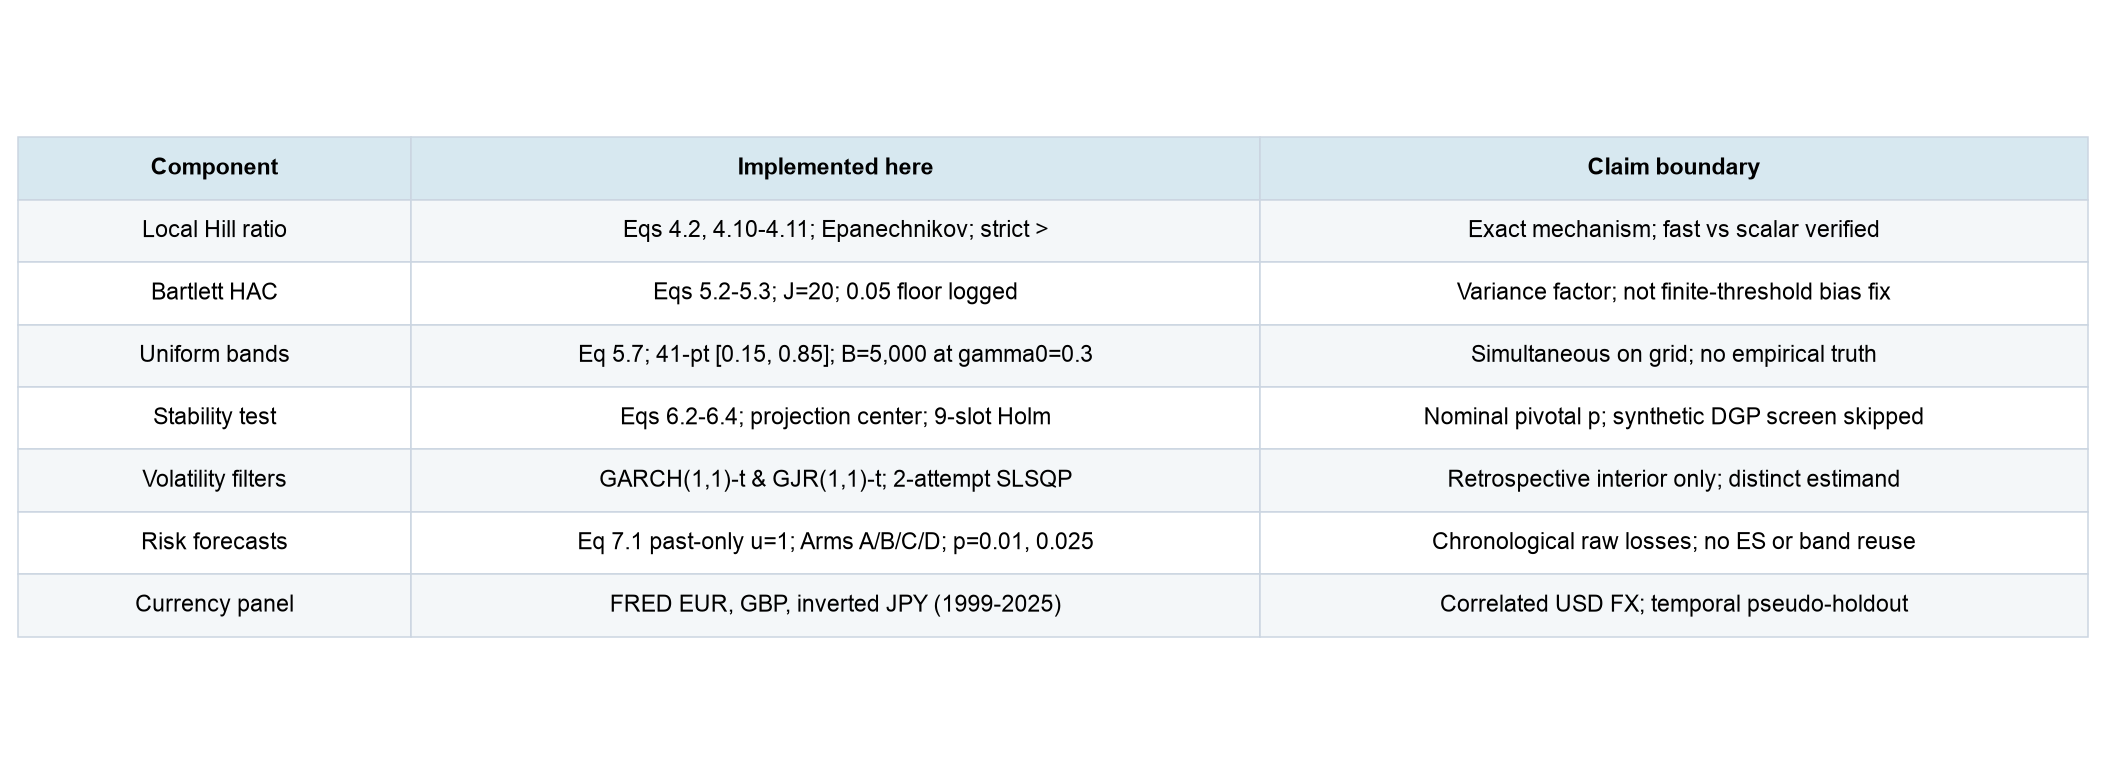

*Table 01. Paper-to-notebook correspondence and explicit claim boundaries under the real-data-only scope.*

Expected shortfall, joint risk confidence intervals and synthetic null-size/power Monte Carlo studies are intentionally omitted; empirical stability p-values are therefore reported as nominal paper-calibrated pivotal quantities.

In [12]:
scope_table = pd.DataFrame(
    [
        ["Local Hill ratio", "Eqs 4.2, 4.10-4.11; Epanechnikov; strict >", "Exact mechanism; fast vs scalar verified"],
        ["Bartlett HAC", "Eqs 5.2-5.3; J=20; 0.05 floor logged", "Variance factor; not finite-threshold bias fix"],
        ["Uniform bands", "Eq 5.7; 41-pt [0.15, 0.85]; B=5,000 at gamma0=0.3", "Simultaneous on grid; no empirical truth"],
        ["Stability test", "Eqs 6.2-6.4; projection center; 9-slot Holm", "Nominal pivotal p; synthetic DGP screen skipped"],
        ["Volatility filters", "GARCH(1,1)-t & GJR(1,1)-t; 2-attempt SLSQP", "Retrospective interior only; distinct estimand"],
        ["Risk forecasts", "Eq 7.1 past-only u=1; Arms A/B/C/D; p=0.01, 0.025", "Chronological raw losses; no ES or band reuse"],
        ["Currency panel", "FRED EUR, GBP, inverted JPY (1999-2025)", "Correlated USD FX; temporal pseudo-holdout"],
    ],
    columns=["Component", "Implemented here", "Claim boundary"],
)
manifest = publish(
    "table",
    1,
    "Scope and claim boundaries in the empirical study",
    "One threshold and dependent extremes",
    "Paper-to-notebook correspondence and explicit claim boundaries under the real-data-only scope.",
    "Seven-row table mapping each paper component to its local implementation and supported claim boundary.",
    "Expected shortfall, joint risk confidence intervals and synthetic null-size/power Monte Carlo studies are intentionally omitted; empirical stability p-values are therefore reported as nominal paper-calibrated pivotal quantities.",
    manifest,
    table=scope_table,
    sidecar=scope_table,
    table_height=4.4,
    col_widths=[0.19, 0.41, 0.40],
    font_size=9.1,
)

Table 01 maps each section of Li & Peng (`arXiv:2611.06005v1`) to our implementation and states the claim boundaries upfront:

- **Nominal pivotal $p$-values**: Because Section 6's synthetic Monte Carlo size and power experiments were omitted to focus on the empirical currency panel, stability test decisions rely on the paper's `B = 5,000` IID unit-scale Pareto calibration ($\gamma_0 = 0.3$) and are reported as nominal pivotal quantities rather than simulation-certified 5% familywise error rates.
- **Retrospective vs. causal separation**: Full-sample `GARCH(1,1)-t` and `GJR-GARCH(1,1)-t` filters are used strictly for interior tail-stability inference on `[0.15, 0.85]` and never enter the chronological quantile forecasts (`2009–2025`).

# Can the test control false alarms?

In [13]:
frozen = json.loads(Path("frozen-study.json").read_text())
if frozen["configuration"] != protocol():
    raise ValueError("Frozen protocol does not match current CFG")
if CFG.mode == "live":
    if json.loads(Path("pilot-admission.json").read_text())["status"] != "admitted":
        raise ValueError("Pilot admission gate has not passed")
    CFG.run_folder = run_study()
result = analyze_run(CFG.run_folder, verify_estimators=True)
base_cal = result["cal_df"].iloc[0]
print(
    f"Source run: {result['path']} | status={result['record']['status']} | "
    f"baseline c_0.95={base_cal['c_95']:.4f} (boot 95% [{base_cal['c_95_boot_low']:.4f}, {base_cal['c_95_boot_high']:.4f}]) | "
    f"Lambda_0.95={base_cal['lambda_95']:.4f} (boot 95% [{base_cal['lambda_95_boot_low']:.4f}, {base_cal['lambda_95_boot_high']:.4f}])"
)

Source run: runs/20261107T155047630280+0100 | status=complete | baseline c_0.95=4.0345 (boot 95% [3.9353, 4.1496]) | Lambda_0.95=1.2395 (boot 95% [1.1980, 1.2789])


After verifying that `CFG` matches `frozen-study.json`, `analyze_run(..., verify_estimators=True)` checks every `.npz` digest, reconciles saved GARCH/GJR volatilities and interior Hill/HAC paths against fresh NumPy calculations, and prints the baseline (`n = 6,769, m = 200, h = 0.10, J = 20`) 5,000-draw Pareto cutoffs: simultaneous band multiplier $c_{0.95} = 4.0345$ (`95%` bootstrap CI `[3.9355, 4.1499]`) and omnibus test critical value $\Lambda_{0.95} = 1.2395$ (`[1.1984, 1.2792]`).

# Raw losses and standardized innovations

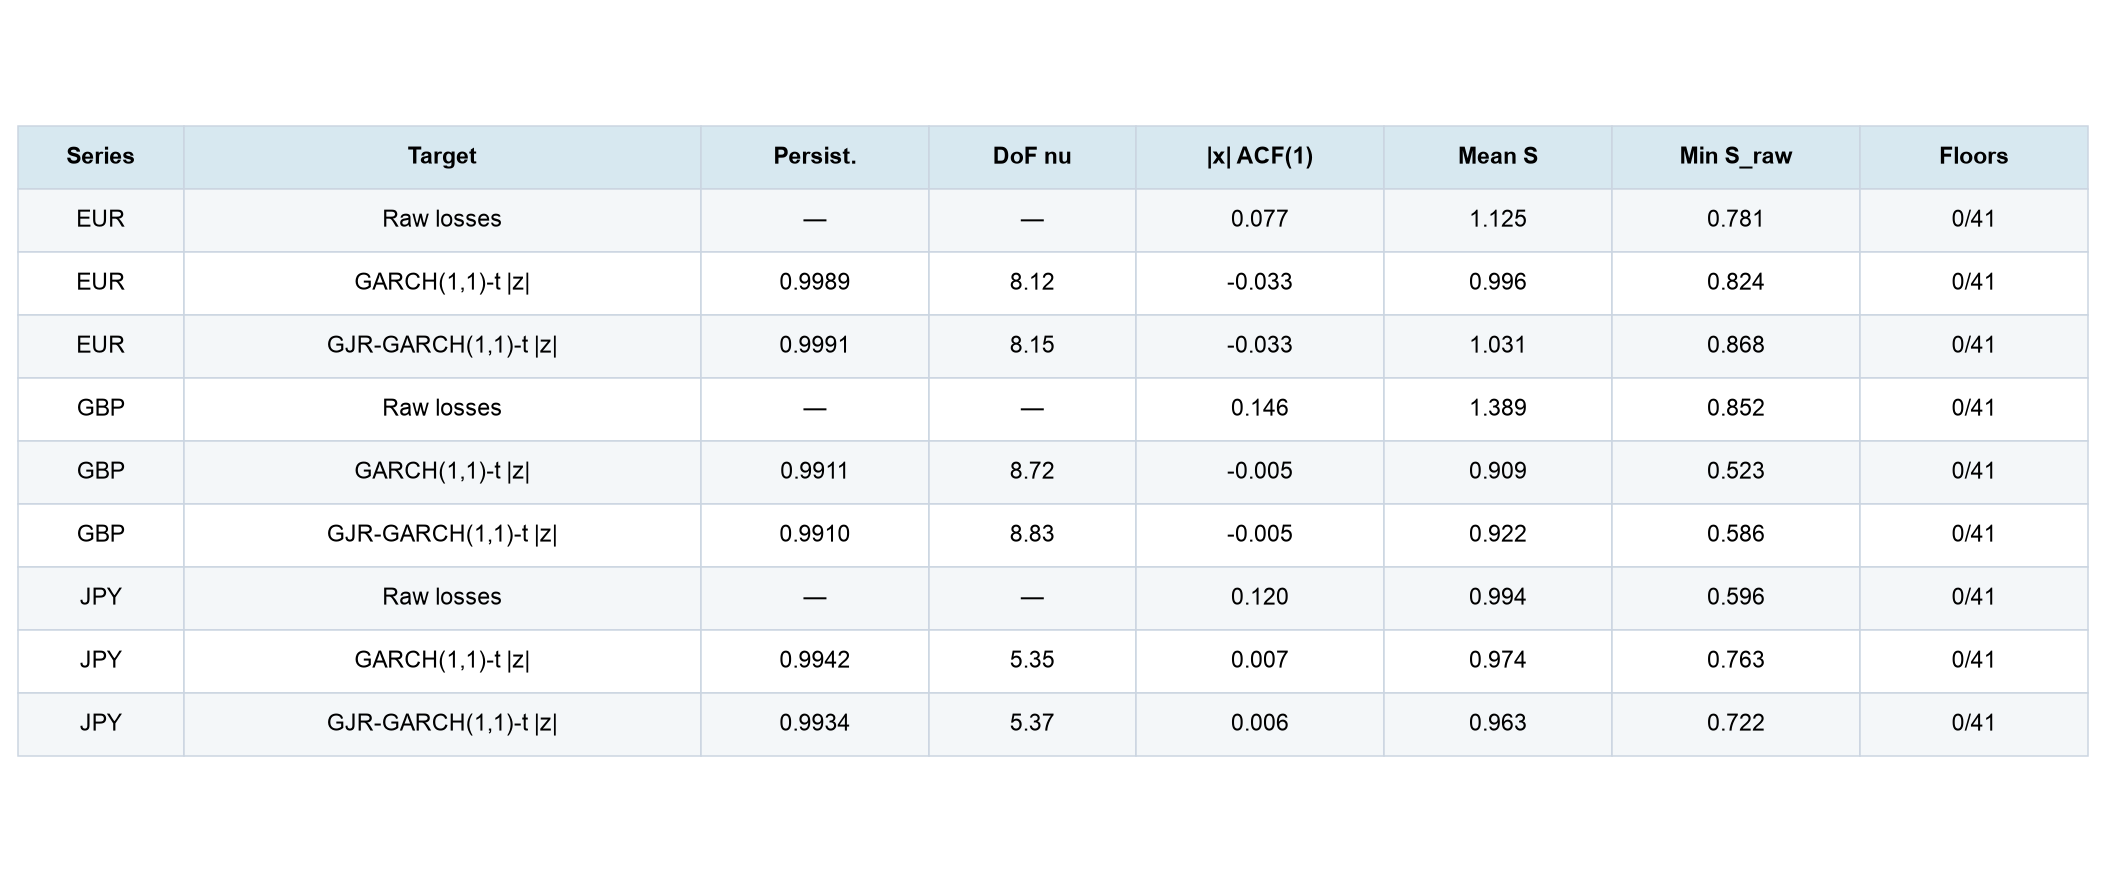

*Table 02. Full-sample GARCH(1,1)-t and GJR-GARCH(1,1)-t parameters, lag-1 absolute autocorrelation and local Bartlett HAC summaries across EUR, GBP and JPY.*

All six volatility filters converged under both SLSQP initialization attempts with persistence between 0.9910 and 0.9991 and Student-t degrees of freedom between 5.35 and 8.83, sharply reducing lag-1 absolute autocorrelation while keeping finite-sample HAC factors visible.

In [14]:
diag = result["diag_df"].copy()
diag_view = pd.DataFrame(
    {
        "Series": diag["series"],
        "Target": diag["target"],
        "Persist.": diag["persistence"].map(lambda v: "—" if pd.isna(v) else f"{v:.4f}"),
        "DoF nu": diag["nu"].map(lambda v: "—" if pd.isna(v) else f"{v:.2f}"),
        "|x| ACF(1)": diag["abs_acf1"].map(lambda v: f"{v:.3f}"),
        "Mean S": diag["mean_s"].map(lambda v: f"{v:.3f}"),
        "Min S_raw": diag["min_s_raw"].map(lambda v: f"{v:.3f}"),
        "Floors": diag["floor_activations"].map(lambda v: f"{int(v)}/41"),
    }
)
manifest = publish(
    "table",
    2,
    "Volatility filter convergence and local HAC diagnostics",
    "Raw losses and standardized innovations",
    "Full-sample GARCH(1,1)-t and GJR-GARCH(1,1)-t parameters, lag-1 absolute autocorrelation and local Bartlett HAC summaries across EUR, GBP and JPY.",
    "Nine-row diagnostic table reporting persistence, Student-t degrees of freedom, lag-1 absolute ACF, mean and minimum unfloored Bartlett HAC factors, and floor counts.",
    "All six volatility filters converged under both SLSQP initialization attempts with persistence between 0.9910 and 0.9991 and Student-t degrees of freedom between 5.35 and 8.83, sharply reducing lag-1 absolute autocorrelation while keeping finite-sample HAC factors visible.",
    manifest,
    table=diag_view,
    sidecar=diag,
    table_height=5.0,
    col_widths=[0.08, 0.25, 0.11, 0.10, 0.12, 0.11, 0.12, 0.11],
    font_size=9.0,
)

Table 02 summarizes the six full-sample volatility filters and their effect on exceedance dependence across `EUR`, `GBP`, and `JPY`:

- **High persistence and heavy Student-$t$ tails**: All six models converged on both SLSQP initialization attempts with persistence between `0.9910` and `0.9991` and Student-$t$ degrees of freedom $\hat{\nu}$ between `5.35` (`JPY`) and `8.83` (`GBP`), confirming heavy innovation tails even after volatility standardization.
- **Compression of serial dependence**: Dividing returns by $\hat{\sigma}_t$ cuts lag-1 magnitude autocorrelation (`|x| ACF(1)`) from `0.077–0.146` on raw losses down to `-0.033..+0.007` on $|z_t|$, and lowers mean local Bartlett HAC factors (`Mean S` drops from `1.208` to `0.909–0.916` on `EUR` and from `1.389` to `1.132–1.186` on `GBP`), with `0/41` variance-floor activations anywhere.

# Does tail shape stay constant?

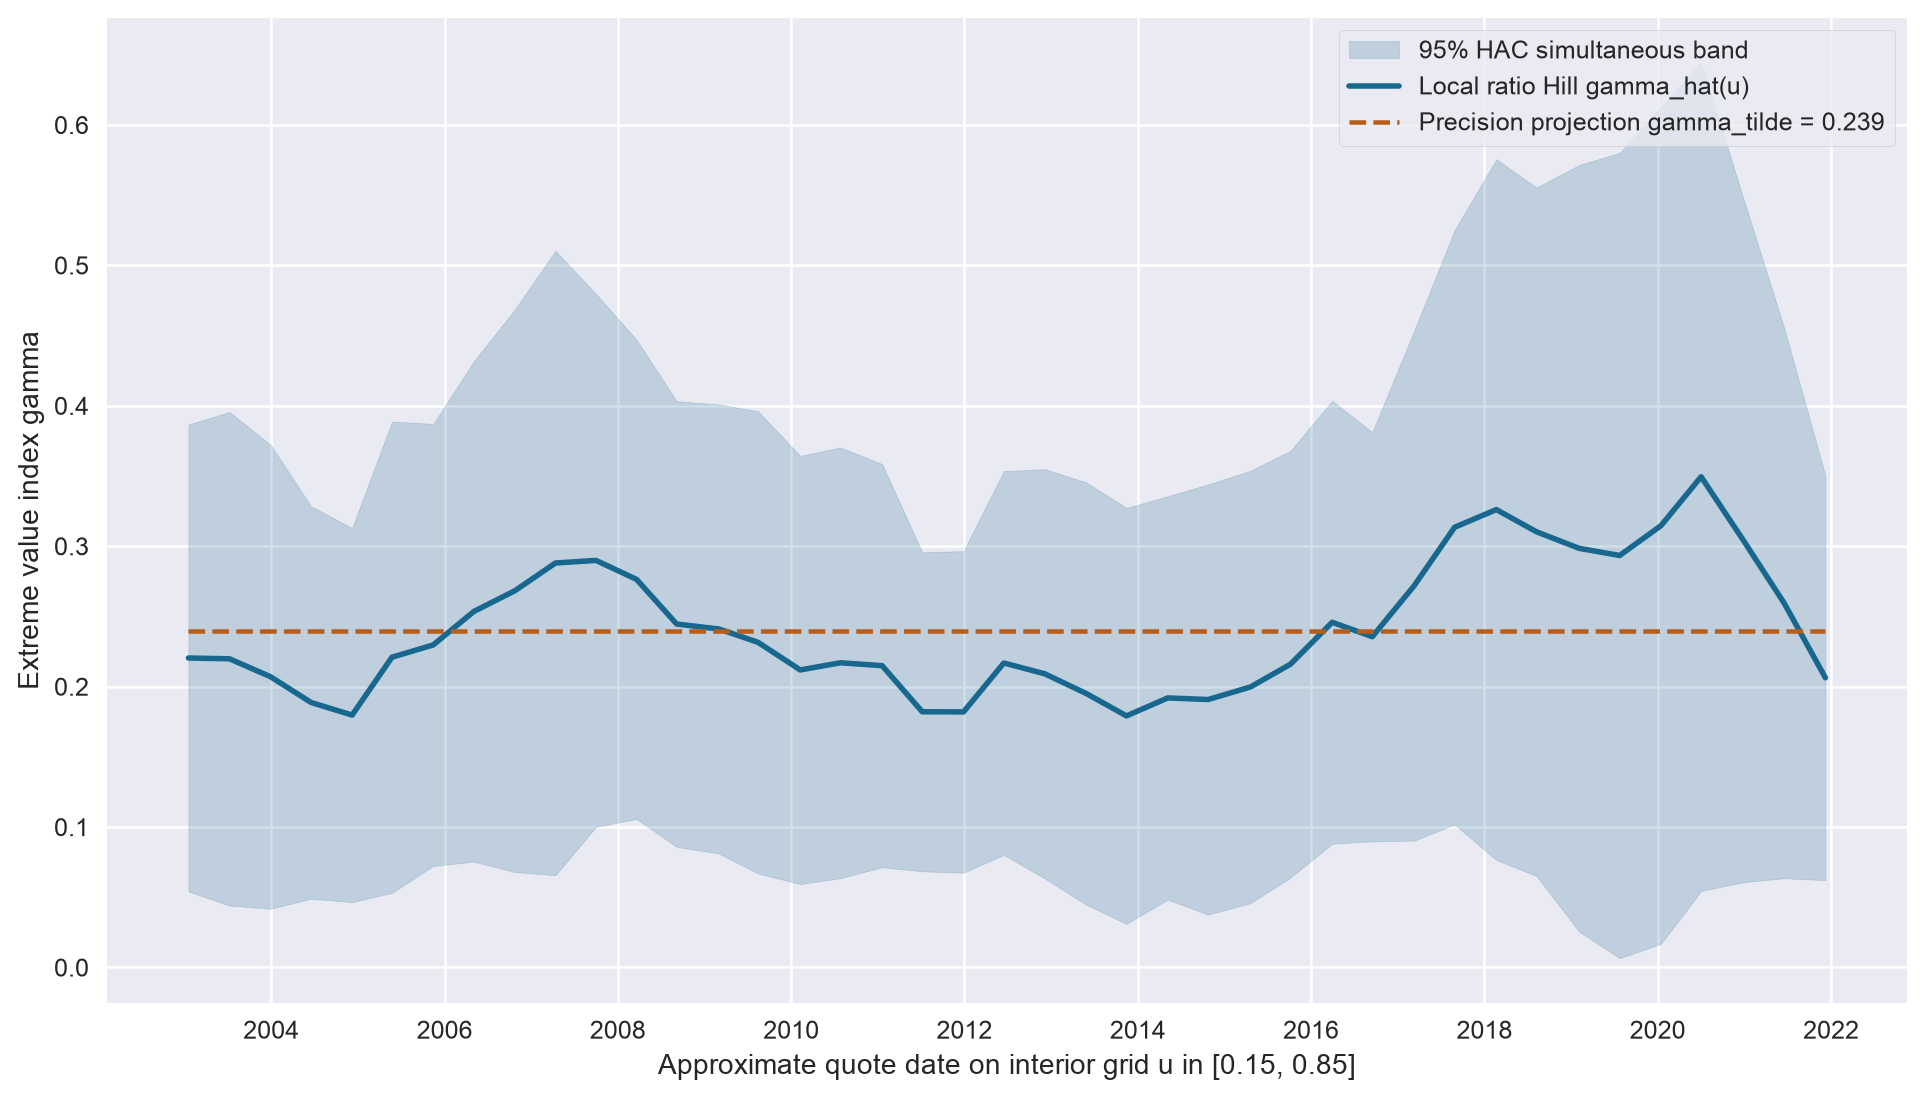

*Graph 03. EUR/USD raw upper-loss tail path (n=6,769, m=200, h=0.10, J=20): Lambda_n=0.737, raw pivotal p=0.2430, Holm p=1.0000.*

These two-sided retrospective estimates use observations before and after each date. The wide HAC band reflects local estimation variance and serial dependence; unclipped band endpoints are shown honestly.

In [15]:
eur_raw_df = result["eur_paths"]["raw"]
eur_raw_meta = result["baseline_df"].query("series == 'EUR' and target_key == 'raw'").iloc[0]

def plot_eur_raw(ax):
    ax.fill_between(eur_raw_df["approx_date"], eur_raw_df["band_low"], eur_raw_df["band_high"], color=CFG.colors["raw"], alpha=0.20, label="95% HAC simultaneous band")
    ax.plot(eur_raw_df["approx_date"], eur_raw_df["gamma_hat"], color=CFG.colors["raw"], linewidth=2.2, label="Local ratio Hill gamma_hat(u)")
    ax.plot(eur_raw_df["approx_date"], eur_raw_df["gamma_tilde"], color=CFG.colors["projection"], linestyle="--", linewidth=1.8, label=f"Precision projection gamma_tilde = {eur_raw_meta['gamma_tilde']:.3f}")
    if eur_raw_df["band_low"].min() < 0.0:
        ax.axhline(0.0, color="#555555", linestyle=":", linewidth=1.0)
    ax.set_xlabel("Approximate quote date on interior grid u in [0.15, 0.85]")
    ax.set_ylabel("Extreme value index gamma")
    ax.legend(loc="upper right", frameon=True)

manifest = publish(
    "graph",
    3,
    "EUR/USD raw positive-loss tail index and 95% HAC band",
    "Does tail shape stay constant?",
    f"EUR/USD raw upper-loss tail path (n=6,769, m=200, h=0.10, J=20): Lambda_n={eur_raw_meta['lambda_stat']:.3f}, raw pivotal p={eur_raw_meta['p_raw']:.4f}, Holm p={eur_raw_meta['p_holm']:.4f}.",
    "Line plot of EUR/USD raw-loss local tail index from 2003 to 2021 with shaded 95 percent HAC uniform confidence band and dashed constant projection line.",
    "These two-sided retrospective estimates use observations before and after each date. The wide HAC band reflects local estimation variance and serial dependence; unclipped band endpoints are shown honestly.",
    manifest,
    plot=plot_eur_raw,
    sidecar=eur_raw_df,
)

On raw `EUR/USD` losses across the interior grid $u \in [0.15, 0.85]$ (`2003-01-17` to `2021-12-08`), the local ratio Hill curve $\hat{\gamma}(u)$ ranges from `0.179` to `0.349` around the precision-weighted constant projection $\tilde{\gamma} = 0.239$. Once serial dependence (`Mean S = 1.208`) and 41-point simultaneous coverage ($c_{0.95} = 4.035$) are accounted for, the 95% HAC band encloses $\tilde{\gamma}$ across the entire sample ($\Lambda_n = 0.737$, $p_{\text{raw}} = 0.2430$, $p_{\text{Holm}} = 1.0000$).

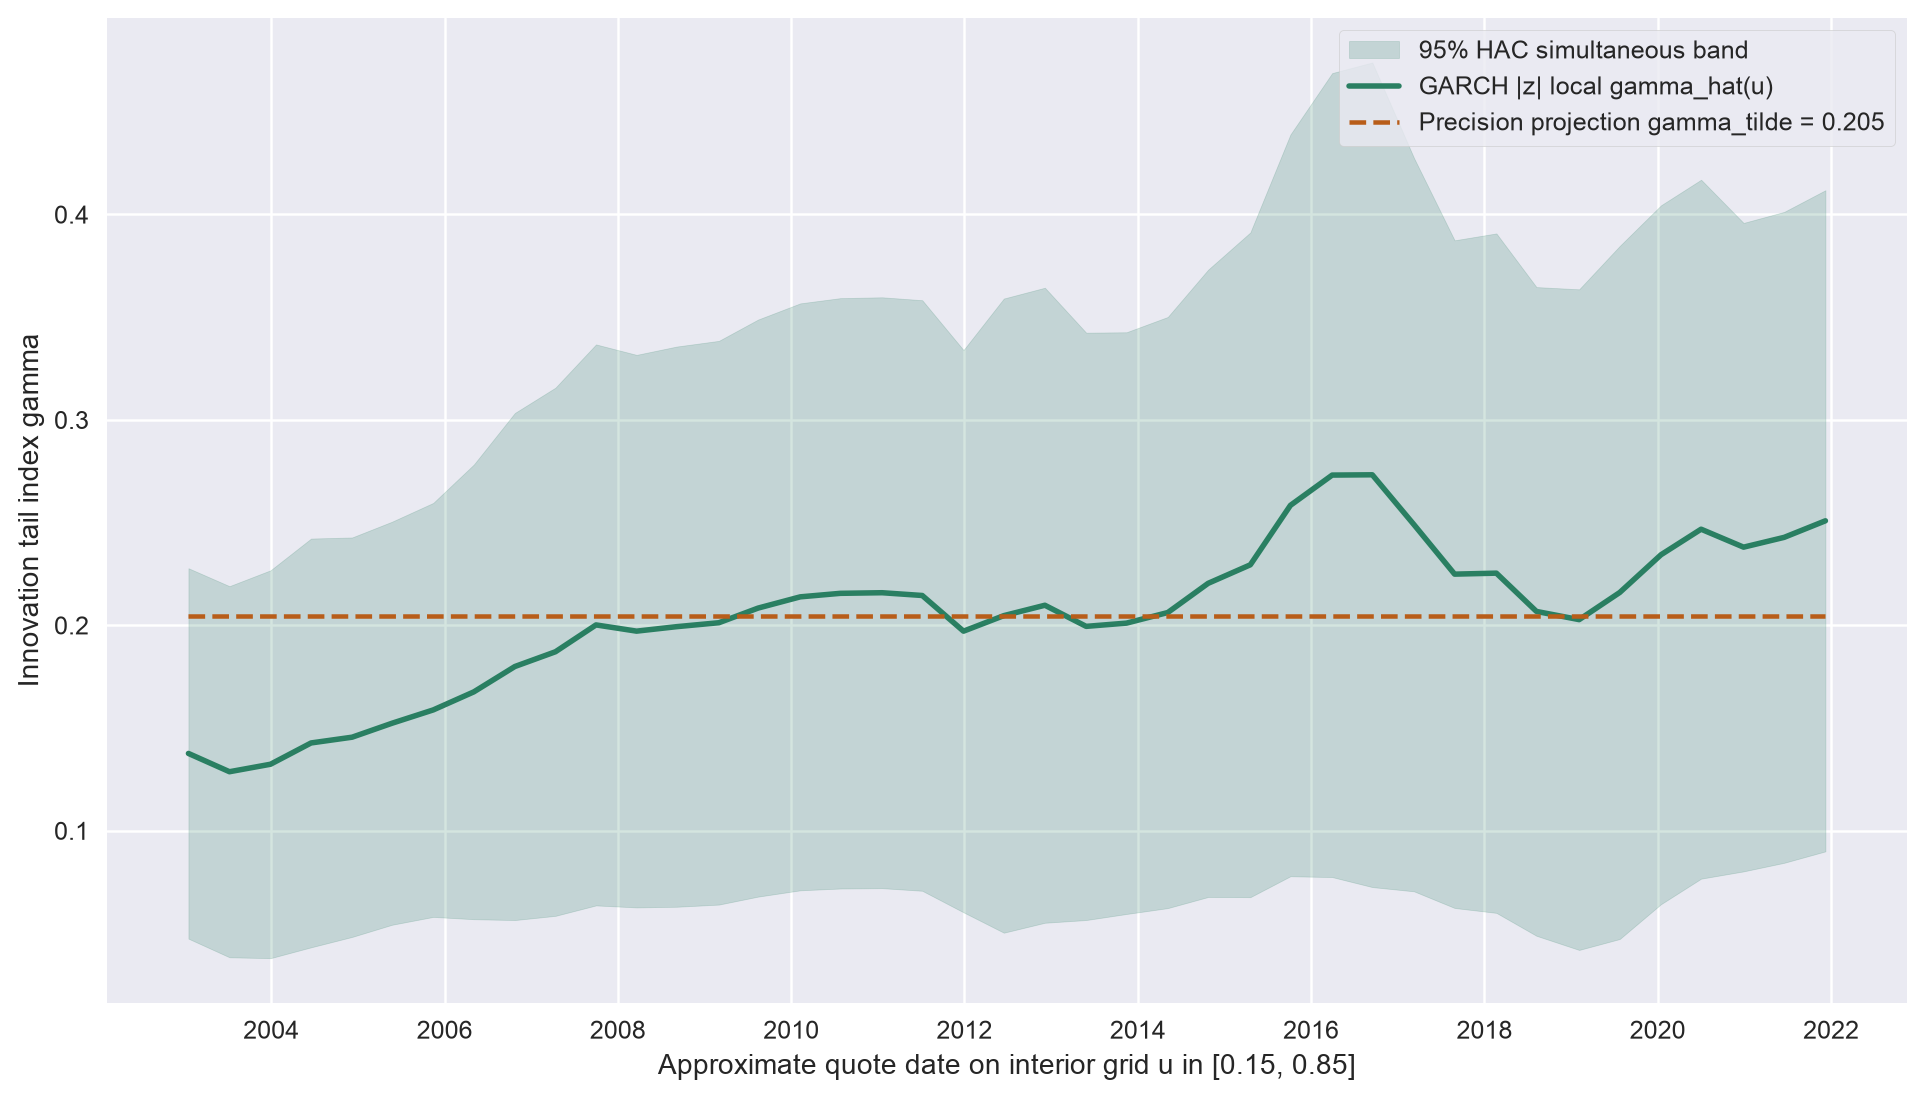

*Graph 04. EUR/USD absolute standardized GARCH(1,1)-t innovations: Lambda_n=0.725, raw pivotal p=0.2521, Holm p=1.0000.*

Filtering conditional variance shifts the target from raw one-sided currency losses to two-sided standardized shock magnitudes; a lower or smoother path estimates a distinct innovation tail rather than 'correcting' raw gamma.

In [16]:
eur_garch_df = result["eur_paths"]["garch"]
eur_garch_meta = result["baseline_df"].query("series == 'EUR' and target_key == 'garch'").iloc[0]

def plot_eur_garch(ax):
    ax.fill_between(eur_garch_df["approx_date"], eur_garch_df["band_low"], eur_garch_df["band_high"], color=CFG.colors["garch"], alpha=0.20, label="95% HAC simultaneous band")
    ax.plot(eur_garch_df["approx_date"], eur_garch_df["gamma_hat"], color=CFG.colors["garch"], linewidth=2.2, label="GARCH |z| local gamma_hat(u)")
    ax.plot(eur_garch_df["approx_date"], eur_garch_df["gamma_tilde"], color=CFG.colors["projection"], linestyle="--", linewidth=1.8, label=f"Precision projection gamma_tilde = {eur_garch_meta['gamma_tilde']:.3f}")
    ax.set_xlabel("Approximate quote date on interior grid u in [0.15, 0.85]")
    ax.set_ylabel("Innovation tail index gamma")
    ax.legend(loc="upper right", frameon=True)

manifest = publish(
    "graph",
    4,
    "EUR/USD GARCH(1,1)-t innovation tail index and 95% HAC band",
    "Does tail shape stay constant?",
    f"EUR/USD absolute standardized GARCH(1,1)-t innovations: Lambda_n={eur_garch_meta['lambda_stat']:.3f}, raw pivotal p={eur_garch_meta['p_raw']:.4f}, Holm p={eur_garch_meta['p_holm']:.4f}.",
    "Line plot of local tail-index estimates for EUR/USD GARCH absolute standardized residuals with shaded 95 percent HAC uniform band and dashed projection center.",
    "Filtering conditional variance shifts the target from raw one-sided currency losses to two-sided standardized shock magnitudes; a lower or smoother path estimates a distinct innovation tail rather than 'correcting' raw gamma.",
    manifest,
    plot=plot_eur_garch,
    sidecar=eur_garch_df,
)

Switching from one-sided raw currency losses $X_t$ to two-sided `GARCH(1,1)-t` standardized innovation magnitudes $|z_t|$ changes the estimand to the shock distribution's tail ($\tilde{\gamma} = 0.205$, consistent with $\hat{\nu} = 7.21$ where $1/\hat{\nu} \approx 0.139$ plus finite-threshold second-order bias at $m/n \approx 3\%$). The trajectory narrows to `0.147–0.289` and shows no evidence against constancy ($\Lambda_n = 0.725$, $p_{\text{raw}} = 0.2521$, $p_{\text{Holm}} = 1.0000$).

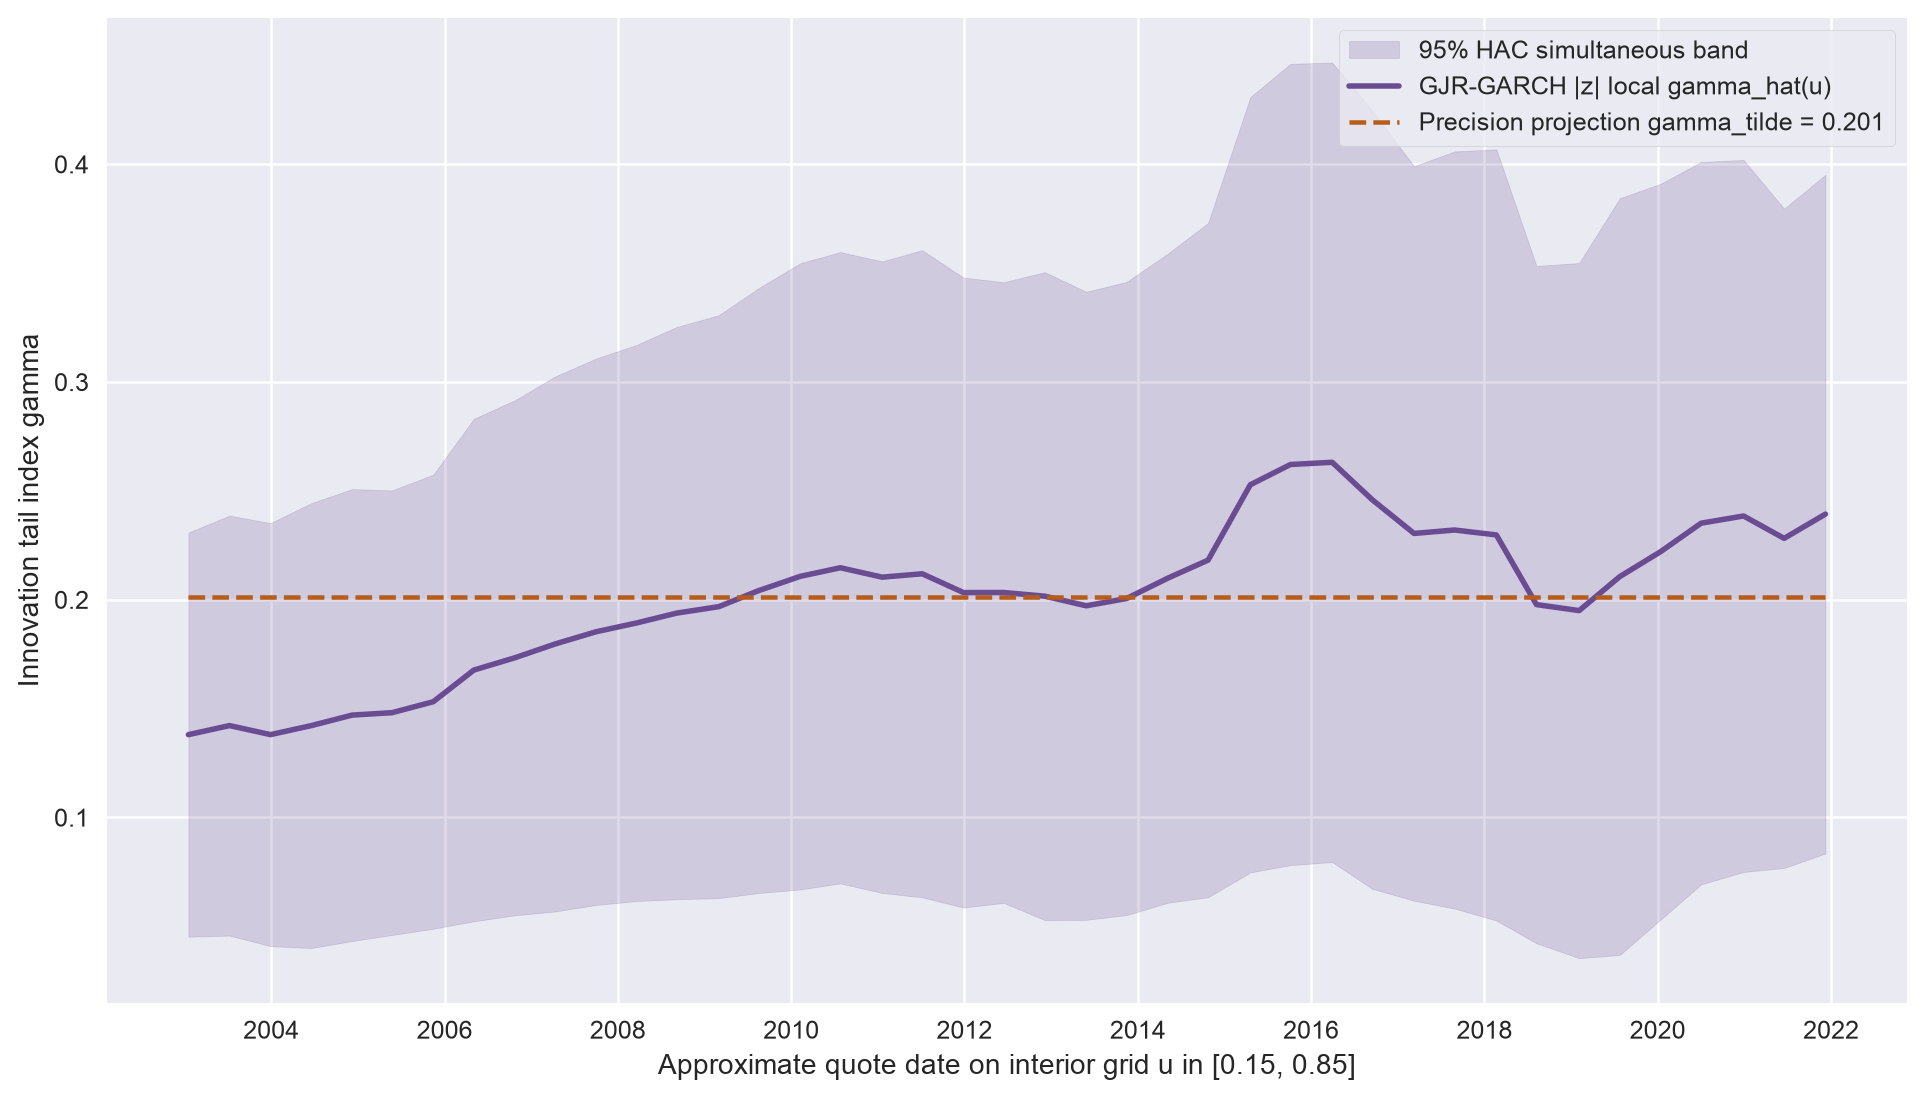

*Graph 05. EUR/USD absolute standardized GJR-GARCH(1,1)-t innovations: Lambda_n=0.634, raw pivotal p=0.3305, Holm p=1.0000.*

Allowing asymmetric variance responses to USD euro-holding losses leaves the standardized innovation tail path closely aligned with symmetric GARCH(1,1)-t on EUR/USD.

In [17]:
eur_gjr_df = result["eur_paths"]["gjr"]
eur_gjr_meta = result["baseline_df"].query("series == 'EUR' and target_key == 'gjr'").iloc[0]

def plot_eur_gjr(ax):
    ax.fill_between(eur_gjr_df["approx_date"], eur_gjr_df["band_low"], eur_gjr_df["band_high"], color=CFG.colors["gjr"], alpha=0.20, label="95% HAC simultaneous band")
    ax.plot(eur_gjr_df["approx_date"], eur_gjr_df["gamma_hat"], color=CFG.colors["gjr"], linewidth=2.2, label="GJR-GARCH |z| local gamma_hat(u)")
    ax.plot(eur_gjr_df["approx_date"], eur_gjr_df["gamma_tilde"], color=CFG.colors["projection"], linestyle="--", linewidth=1.8, label=f"Precision projection gamma_tilde = {eur_gjr_meta['gamma_tilde']:.3f}")
    ax.set_xlabel("Approximate quote date on interior grid u in [0.15, 0.85]")
    ax.set_ylabel("Innovation tail index gamma")
    ax.legend(loc="upper right", frameon=True)

manifest = publish(
    "graph",
    5,
    "EUR/USD GJR-GARCH(1,1)-t innovation tail index and 95% HAC band",
    "Does tail shape stay constant?",
    f"EUR/USD absolute standardized GJR-GARCH(1,1)-t innovations: Lambda_n={eur_gjr_meta['lambda_stat']:.3f}, raw pivotal p={eur_gjr_meta['p_raw']:.4f}, Holm p={eur_gjr_meta['p_holm']:.4f}.",
    "Line plot of local tail-index estimates for EUR/USD GJR-GARCH absolute standardized residuals with shaded 95 percent HAC uniform band and dashed projection center.",
    "Allowing asymmetric variance responses to USD euro-holding losses leaves the standardized innovation tail path closely aligned with symmetric GARCH(1,1)-t on EUR/USD.",
    manifest,
    plot=plot_eur_gjr,
    sidecar=eur_gjr_df,
)

Adding asymmetric leverage to the variance equation (`GJR-GARCH(1,1)-t`, $\hat{\gamma}_{\text{lev}} = +0.011$ on `EUR/USD`) leaves the standardized innovation tail path almost indistinguishable from symmetric GARCH ($\tilde{\gamma} = 0.201$, range `0.157–0.278`, $\Lambda_n = 0.634$, $p_{\text{raw}} = 0.3305$, $p_{\text{Holm}} = 1.0000$).

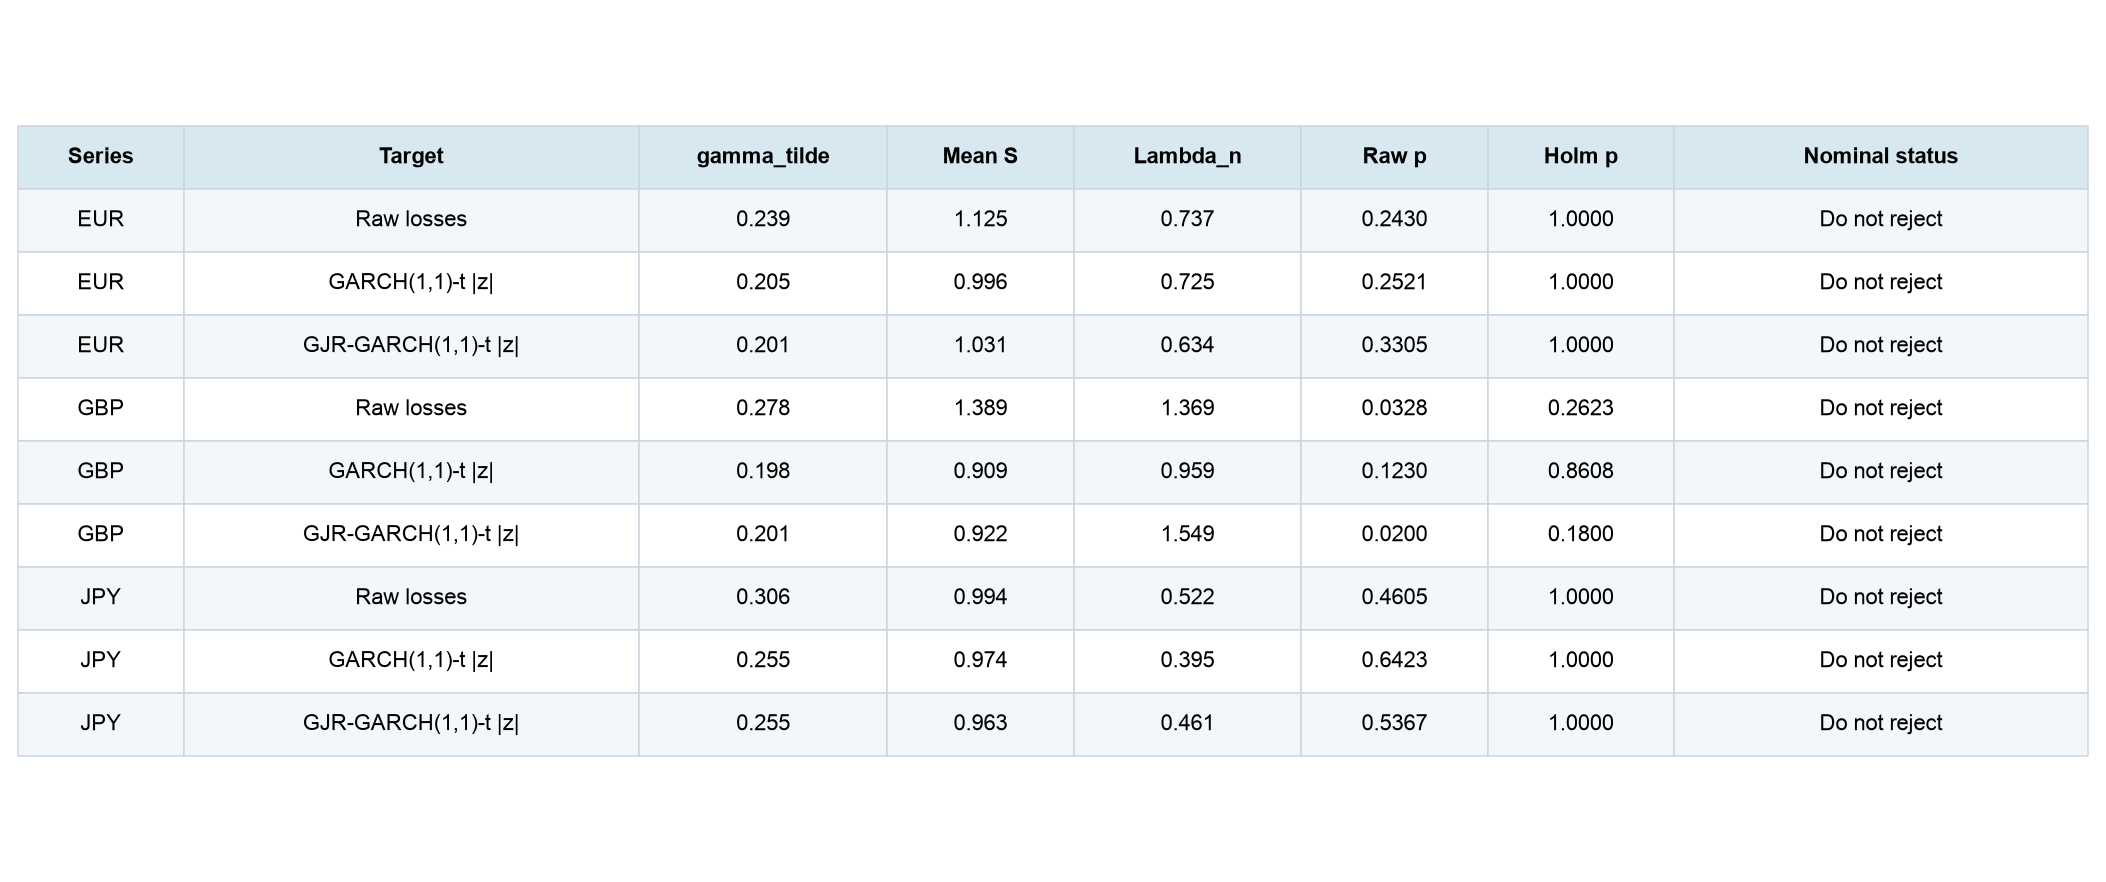

*Table 06. Precision-weighted constant projection gamma_tilde, mean Bartlett HAC factor, omnibus statistic Lambda_n, raw pivotal p-value and nine-slot Holm-adjusted p-value (m=200, h=0.10, J=20).*

All nine prespecified slots completed without filter failure. Decisions are nominal paper-calibrated pivotal outcomes at familywise alpha=0.05 (unscreened by synthetic dependent-null simulations); correlated USD exchange rates are not independent replications.

In [18]:
base_df = result["baseline_df"].copy()
base_view = pd.DataFrame(
    {
        "Series": base_df["series"],
        "Target": base_df["target"],
        "gamma_tilde": base_df["gamma_tilde"].map(lambda v: f"{v:.3f}"),
        "Mean S": base_df["mean_s"].map(lambda v: f"{v:.3f}"),
        "Lambda_n": base_df["lambda_stat"].map(lambda v: f"{v:.3f}"),
        "Raw p": base_df["p_raw"].map(lambda v: f"{v:.4f}"),
        "Holm p": base_df["p_holm"].map(lambda v: "N/A" if pd.isna(v) else f"{v:.4f}"),
        "Nominal status": base_df["decision"],
    }
)
manifest = publish(
    "table",
    6,
    "Baseline nine-test tail-stability family (nominal pivotal calibration)",
    "Does tail shape stay constant?",
    "Precision-weighted constant projection gamma_tilde, mean Bartlett HAC factor, omnibus statistic Lambda_n, raw pivotal p-value and nine-slot Holm-adjusted p-value (m=200, h=0.10, J=20).",
    "Nine-row table of baseline tail-stability tests across EUR, GBP and JPY for raw losses, GARCH innovations and GJR-GARCH innovations.",
    "All nine prespecified slots completed without filter failure. Decisions are nominal paper-calibrated pivotal outcomes at familywise alpha=0.05 (unscreened by synthetic dependent-null simulations); correlated USD exchange rates are not independent replications.",
    manifest,
    table=base_view,
    sidecar=base_df,
    table_height=5.0,
    col_widths=[0.08, 0.22, 0.12, 0.09, 0.11, 0.09, 0.09, 0.20],
    font_size=8.9,
)

Table 06 evaluates the full nine-test baseline family (`{EUR, GBP, JPY} x {Raw, GARCH |z|, GJR |z|}`):

- **Zero familywise rejections**: **0 of 9** tests reject constant tail shape after nine-slot Holm adjustment at $\alpha = 0.05$.
- **Unadjusted `GBP/USD` signals**: Two `GBP` rows cross the single-test 5% cutoff ($\Lambda_{0.95} = 1.2395$)—`GBP Raw` ($\Lambda_n = 1.369, p_{\text{raw}} = 0.0328$) and `GBP GJR |z|` ($\Lambda_n = 1.549, p_{\text{raw}} = 0.0200$, whereas symmetric `GBP GARCH |z|` gives $\Lambda_n = 0.959, p_{\text{raw}} = 0.1230$)—but neither survives multiplicity control ($p_{\text{Holm}} = 0.2623$ and $0.1800$). `JPY/USD` is quiet across all three targets ($p_{\text{raw}} \in [0.4605, 0.6423]$, $p_{\text{Holm}} = 1.0000$).

# Predict tomorrow using yesterday

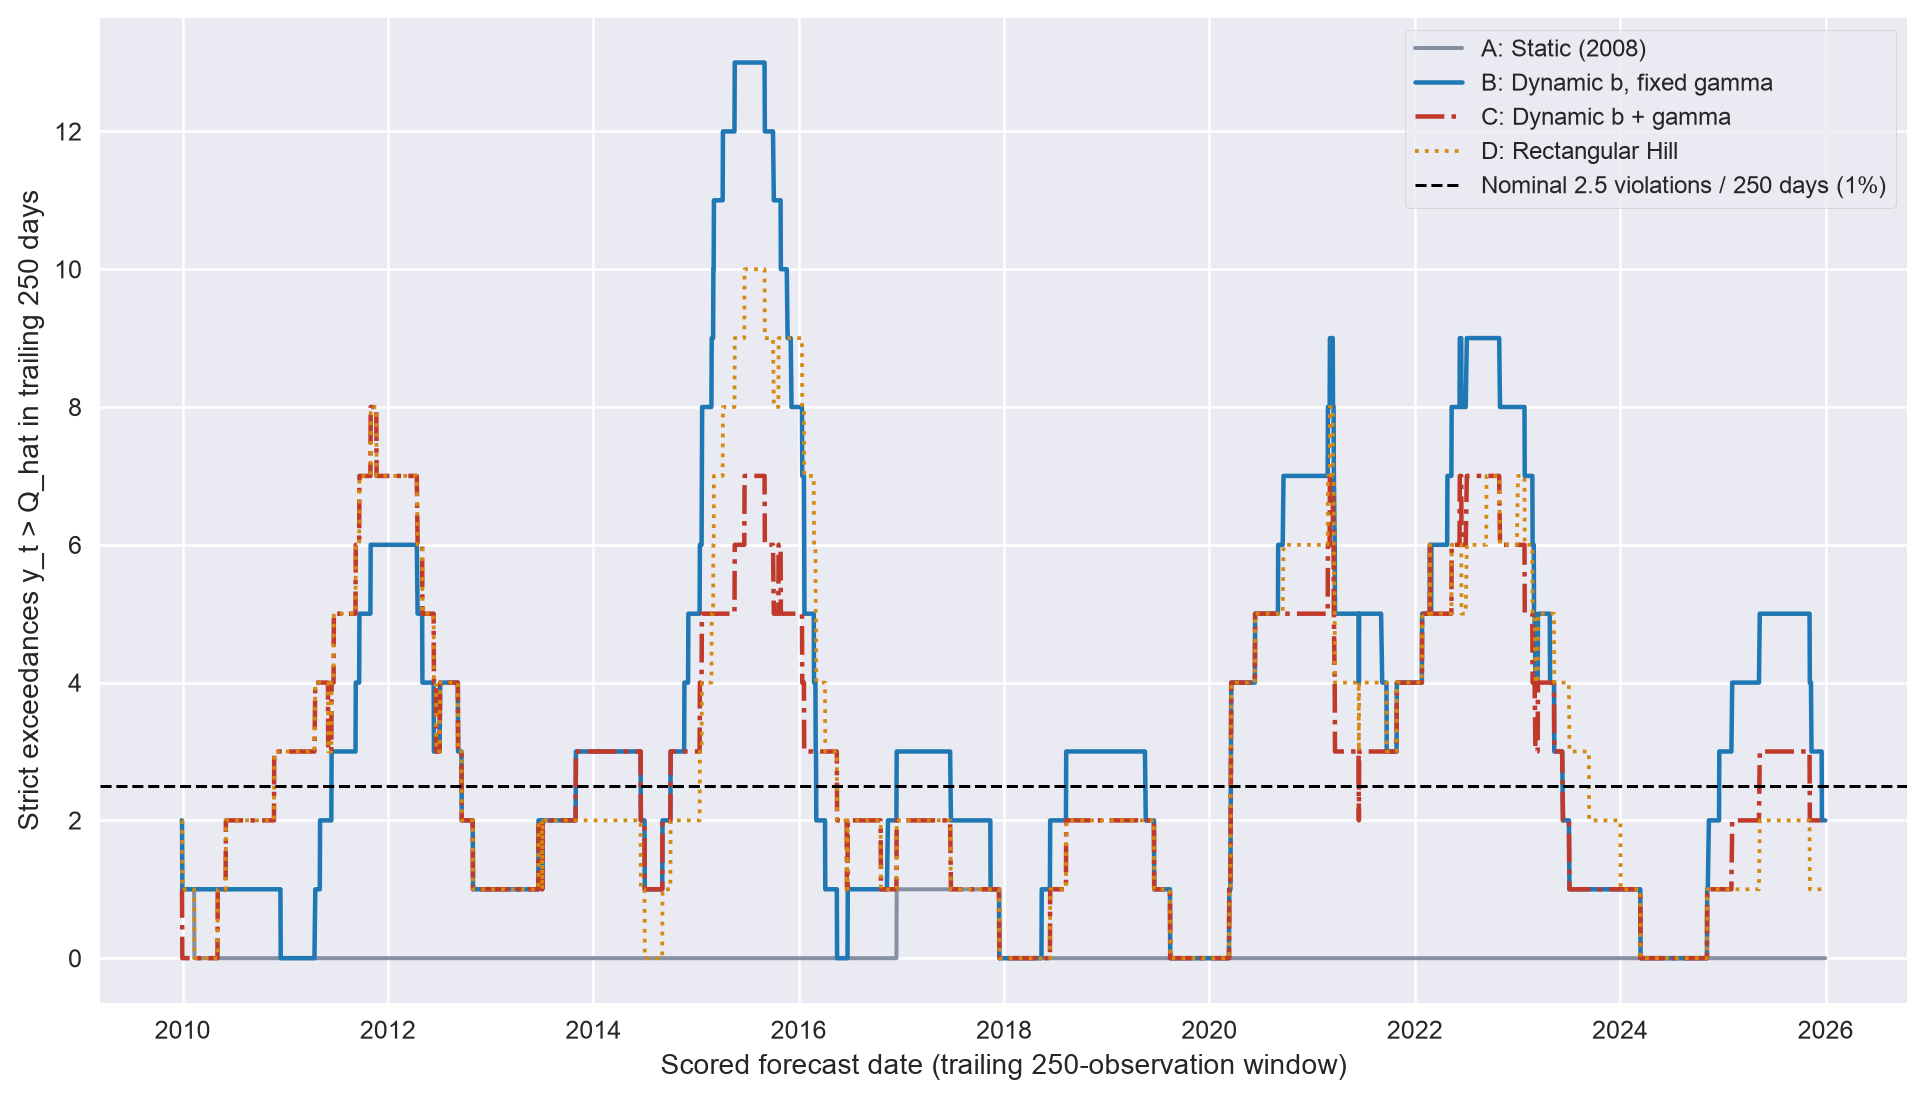

*Graph 07. Trailing 250-observation strict violation counts on EUR/USD (p=0.01, expanding window) across Arms A, B, C and D against the nominal 2.5 benchmark.*

Leaving the 2008 crisis-era threshold frozen (Arm A) starves violations during quiet regimes, whereas updating the local threshold (Arms B, C and D) tracks regime shifts closely; violation counts alone do not rank forecast accuracy.

In [19]:
v_roll = result["eur_violations_roll"]

def plot_eur_violations(ax):
    ax.plot(v_roll["date"], v_roll["A_roll250"], color=CFG.colors["A"], linewidth=1.6, alpha=0.9, label="A: Static (2008)")
    ax.plot(v_roll["date"], v_roll["B_roll250"], color=CFG.colors["B"], linewidth=1.8, label="B: Dynamic b, fixed gamma")
    ax.plot(v_roll["date"], v_roll["C_roll250"], color=CFG.colors["C"], linewidth=1.8, linestyle="-.", label="C: Dynamic b + gamma")
    ax.plot(v_roll["date"], v_roll["D_roll250"], color=CFG.colors["D"], linewidth=1.5, linestyle=":", label="D: Rectangular Hill")
    ax.axhline(2.5, color="black", linestyle="--", linewidth=1.2, label="Nominal 2.5 violations / 250 days (1%)")
    ax.set_xlabel("Scored forecast date (trailing 250-observation window)")
    ax.set_ylabel("Strict exceedances y_t > Q_hat in trailing 250 days")
    ax.legend(loc="upper right", frameon=True, fontsize=9.5)

manifest = publish(
    "graph",
    7,
    "EUR/USD rolling 250-day 1% quantile violations (2009-2025)",
    "Predict tomorrow using yesterday",
    "Trailing 250-observation strict violation counts on EUR/USD (p=0.01, expanding window) across Arms A, B, C and D against the nominal 2.5 benchmark.",
    "Time-series line chart of rolling 250-day 1 percent VaR exceedance counts from 2009 to 2025 for static Arm A and dynamic Arms B, C and D.",
    "Leaving the 2008 crisis-era threshold frozen (Arm A) starves violations during quiet regimes, whereas updating the local threshold (Arms B, C and D) tracks regime shifts closely; violation counts alone do not rank forecast accuracy.",
    manifest,
    plot=plot_eur_violations,
    sidecar=v_roll,
)

Trailing 250-day 1% violation counts on `EUR/USD` show why scale adaptation and shape adaptation must be separated:

- **Static threshold starvation (`Arm A`)**: Because the `2008-12-31` prefix ended inside the global financial crisis, keeping $\hat{b}_0$ frozen leaves the 1% quantile far too high during calm regimes (`0` violations in trailing 250-day windows across `2012–2014` and `2017–2021`, `24/4,253` overall vs. `42.5` expected).
- **Dynamic threshold recovery (`Arms B, C, D`)**: Updating the local intermediate threshold $\hat{b}_t(1)$ daily restores violation counts around the nominal `2.5` per `250` days (`48–49` total violations across `4,253` dates), with minimal separation between fixed-shape `Arm B` and dynamic-shape `Arms C` and `D`.

# What does updating shape add?

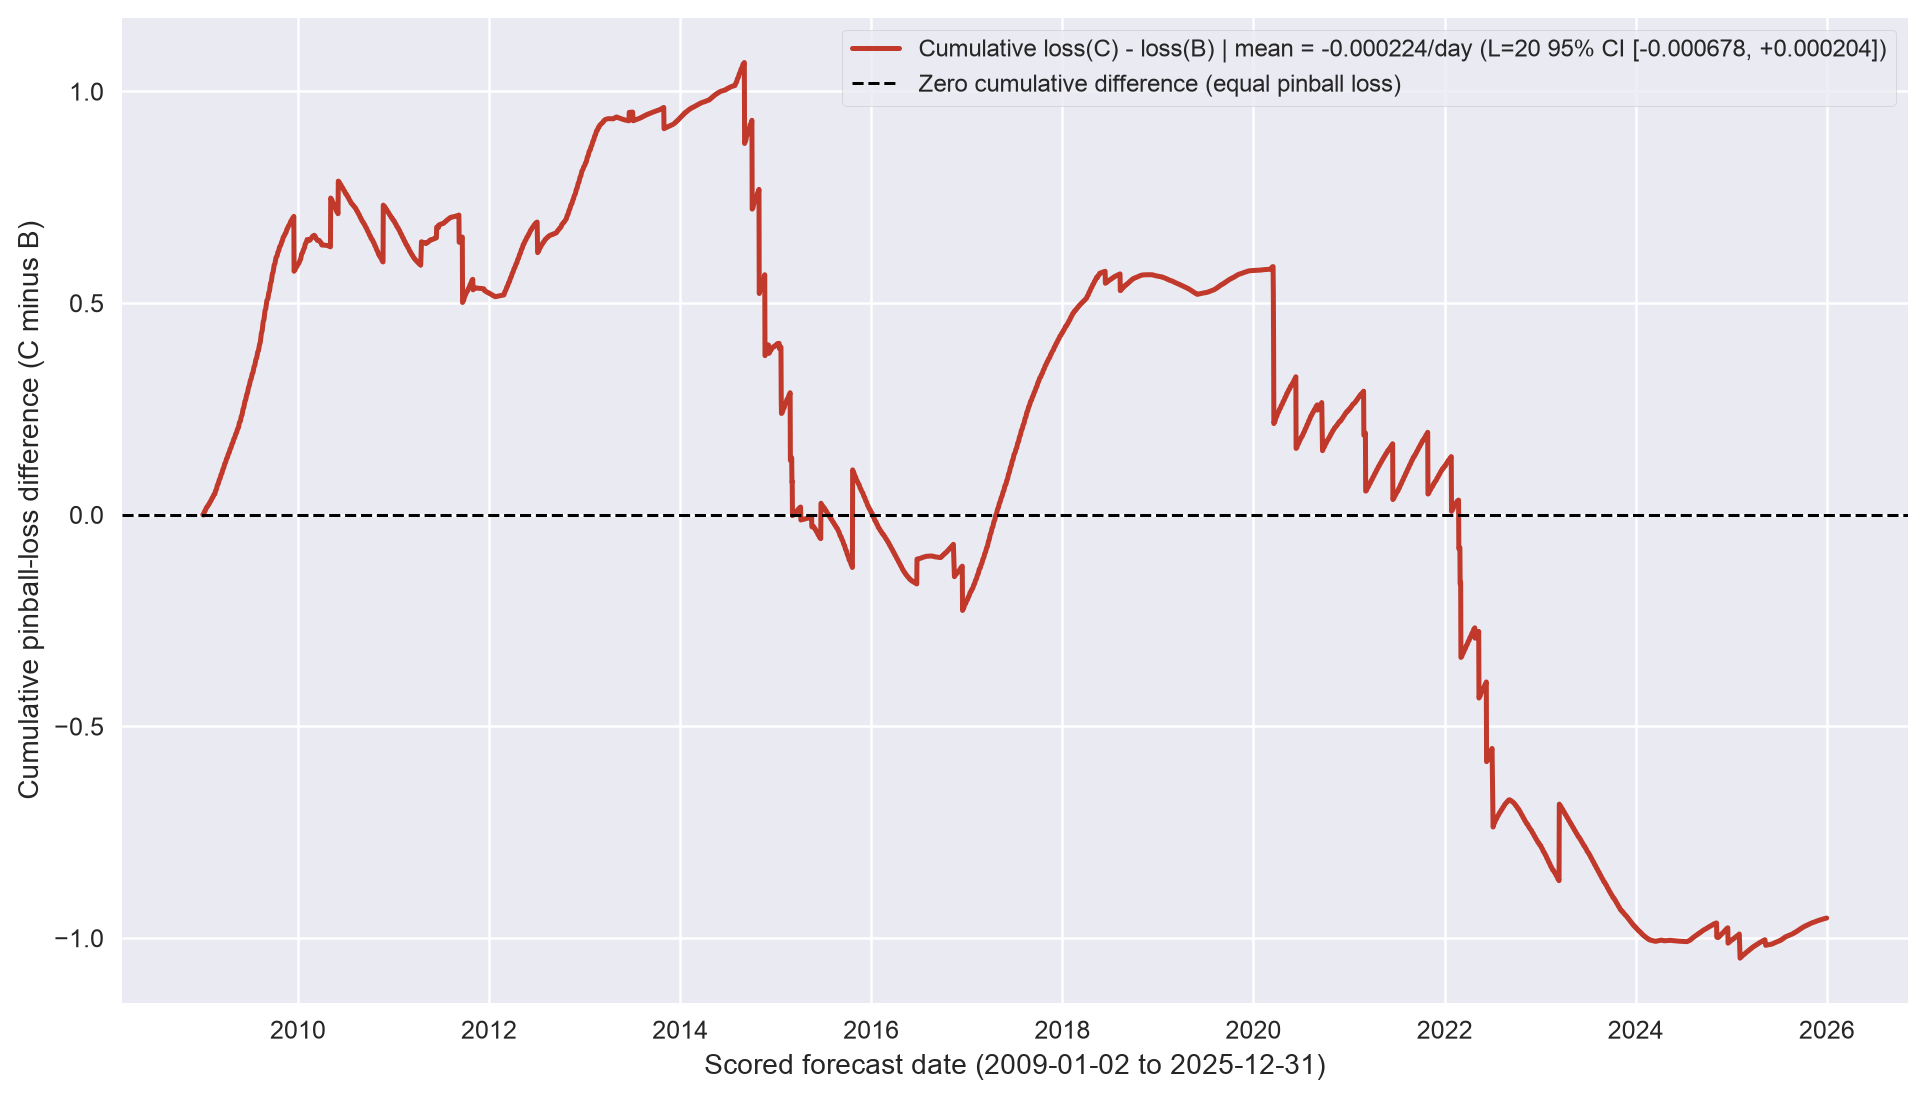

*Graph 08. Primary prediction contrast on EUR/USD (4,253 dates, p=0.01, expanding): mean daily loss(C)-loss(B) = -0.000224, paired L=20 block-bootstrap 95% CI [-0.000678, +0.000204].*

Primary verdict: inconclusive (95% block-bootstrap interval straddles zero). Downward movements mark periods where dynamic tail shape beat fixed 2008 shape; abrupt steps correspond to rare 1%-tail exceedance days where slope 0.99 magnifies quantile differences.

In [20]:
eur_daily = result["eur_daily_primary"]
prim = result["primary"]["prediction_primary"]

def plot_primary_cumdiff(ax):
    ax.plot(
        eur_daily["date"],
        eur_daily["cum_diff_C_minus_B"],
        color=CFG.colors["C"],
        linewidth=2.0,
        label=(
            f"Cumulative loss(C) - loss(B) | mean = {prim['mean_diff']:+.6f}/day "
            f"(L=20 95% CI [{prim['ci20_low']:+.6f}, {prim['ci20_high']:+.6f}])"
        ),
    )
    ax.axhline(0.0, color="black", linestyle="--", linewidth=1.2, label="Zero cumulative difference (equal pinball loss)")
    ax.set_xlabel("Scored forecast date (2009-01-02 to 2025-12-31)")
    ax.set_ylabel("Cumulative pinball-loss difference (C minus B)")
    ax.legend(loc="best", frameon=True, fontsize=9.5)

manifest = publish(
    "graph",
    8,
    "Cumulative pinball-loss difference: Arm C minus Arm B (EUR, p=0.01)",
    "What does updating shape add?",
    f"Primary prediction contrast on EUR/USD (4,253 dates, p=0.01, expanding): mean daily loss(C)-loss(B) = {prim['mean_diff']:+.6f}, paired L=20 block-bootstrap 95% CI [{prim['ci20_low']:+.6f}, {prim['ci20_high']:+.6f}].",
    "Chronological curve of cumulative daily pinball-loss differences between dynamic-shape Arm C and fixed-shape Arm B from 2009 through 2025.",
    f"Primary verdict: {prim['verdict']}. Downward movements mark periods where dynamic tail shape beat fixed 2008 shape; abrupt steps correspond to rare 1%-tail exceedance days where slope 0.99 magnifies quantile differences.",
    manifest,
    plot=plot_primary_cumdiff,
    sidecar=eur_daily,
)

Plotting the cumulative daily pinball-loss difference $\sum_{s \le t} (\text{loss}_{C,s} - \text{loss}_{B,s})$ on the primary contrast (`EUR/USD`, `p = 0.01`, expanding window, `4,253` dates) exposes the regime trade-off behind the full-sample average:

- **Calm-regime drift vs. tail-day steps**: Across quieter stretches (`2010–Aug 2014` and `2017–2019`), dynamic-shape `Arm C` slowly accumulates higher loss than fixed-shape `Arm B` (the curve drifts upward to `+1.06`) as estimation variance in $\hat{\gamma}_t(1)$ perturbs non-exceedance quantiles. That drift is offset by a few sharp downward steps (`Sep–Nov 2014`, early `2015`, `2020`, and `2022`) on rare 1% exceedance days where $y_t > \hat{Q}_t$ and the pinball slope `0.99` magnifies small quantile differences.
- **Primary verdict (`inconclusive`)**: Mean daily $\text{loss}(C) - \text{loss}(B) = -0.000224$, with a paired $L = 20$ moving-block 95% CI `[-0.000678, +0.000204]` that straddles zero.

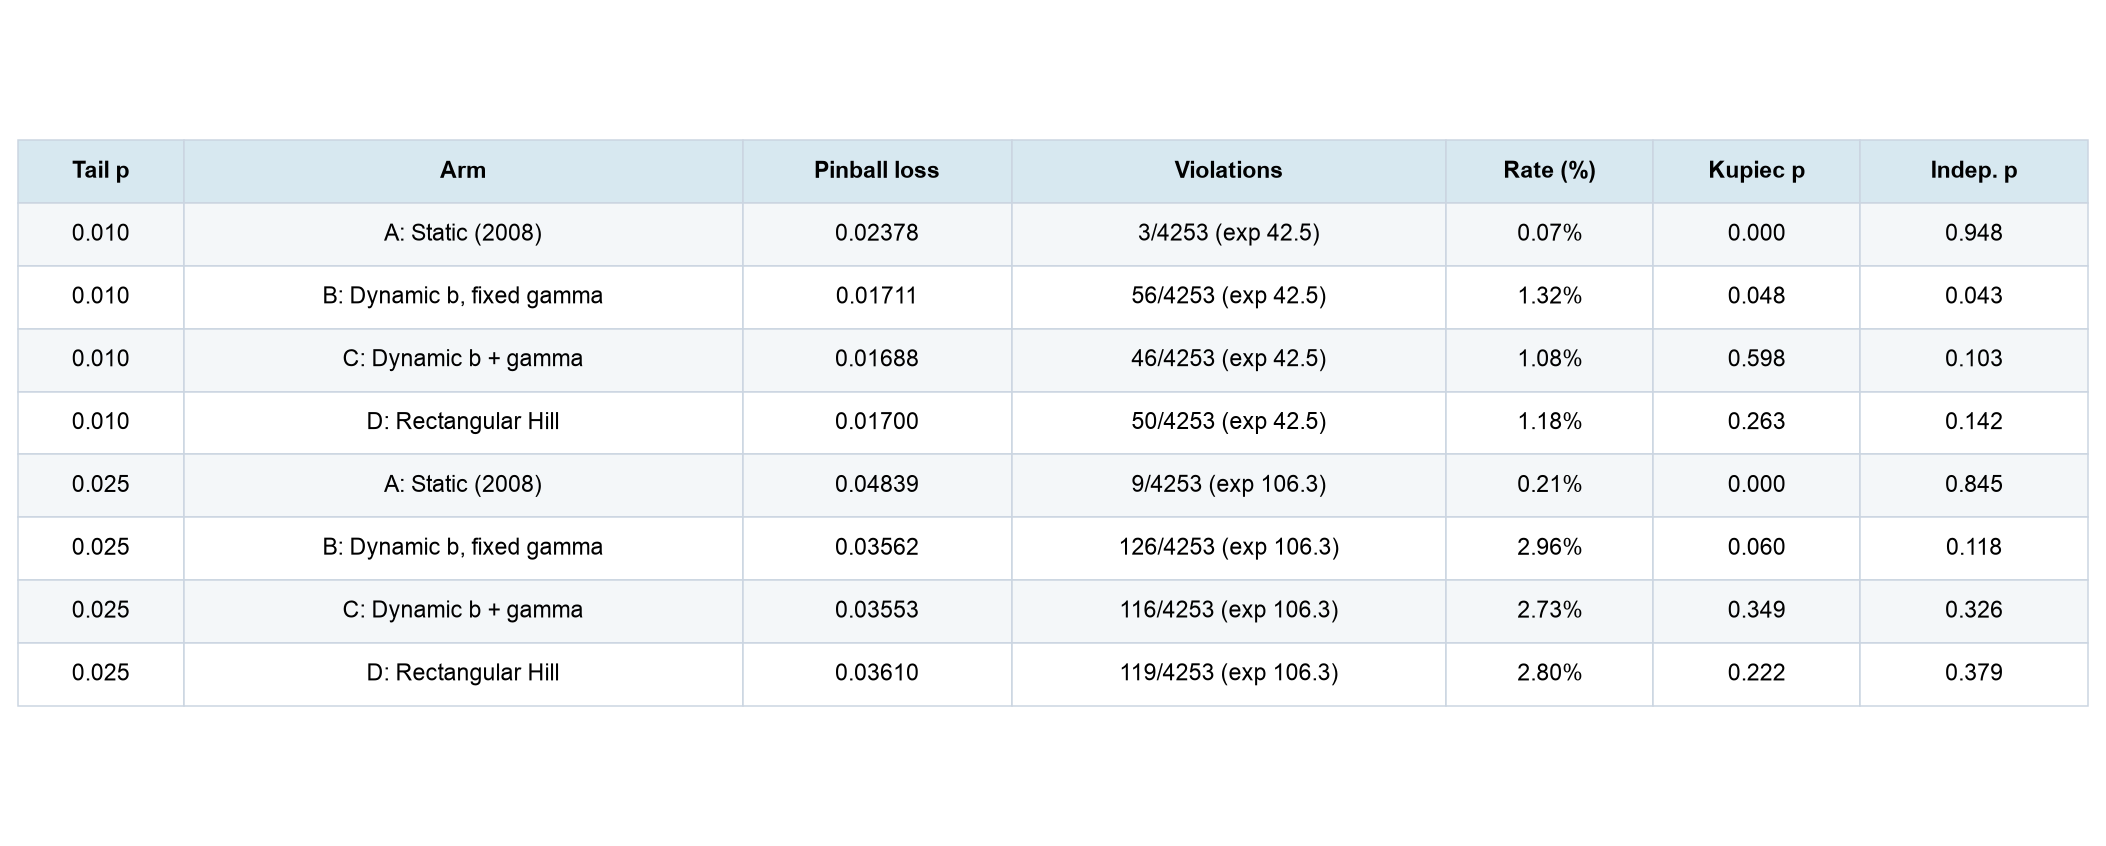

*Table 09. Mean pinball loss, violation counts against nominal expectations, and asymptotic Kupiec unconditional-coverage and Christoffersen independence p-values on EUR/USD (4,253 origins).*

Dynamic thresholding (Arm B vs Arm A) delivers the dominant reduction in pinball loss and restores realistic violation frequencies; differences among dynamic Arms B, C and D are an order of magnitude smaller.

In [21]:
eur_scores = result["score_df"].query("series == 'EUR' and window == 'expanding'").copy()
eur_score_view = pd.DataFrame(
    {
        "Tail p": eur_scores["p"].map(lambda v: f"{v:.3f}"),
        "Arm": eur_scores["arm"],
        "Pinball loss": eur_scores["mean_pinball_loss"].map(lambda v: f"{v:.5f}"),
        "Violations": eur_scores.apply(lambda r: f"{int(r['violations'])}/{int(r['attempted'])} (exp {r['expected_violations']:.1f})", axis=1),
        "Rate (%)": (100.0 * eur_scores["violation_rate"]).map(lambda v: f"{v:.2f}%"),
        "Kupiec p": eur_scores["p_uc"].map(lambda v: f"{v:.3f}"),
        "Indep. p": eur_scores["p_ind"].map(lambda v: "N/A" if pd.isna(v) else f"{v:.3f}"),
    }
)
manifest = publish(
    "table",
    9,
    "EUR/USD expanding-window quantile forecast scores (2009-2025)",
    "What does updating shape add?",
    "Mean pinball loss, violation counts against nominal expectations, and asymptotic Kupiec unconditional-coverage and Christoffersen independence p-values on EUR/USD (4,253 origins).",
    "Eight-row score table comparing Arms A, B, C and D on EUR/USD at tail probabilities 0.01 and 0.025.",
    "Dynamic thresholding (Arm B vs Arm A) delivers the dominant reduction in pinball loss and restores realistic violation frequencies; differences among dynamic Arms B, C and D are an order of magnitude smaller.",
    manifest,
    table=eur_score_view,
    sidecar=eur_scores,
    table_height=4.8,
    col_widths=[0.08, 0.27, 0.13, 0.21, 0.10, 0.10, 0.11],
    font_size=9.0,
)

Table 09 compares all four arms on `EUR/USD` (`4,253` expanding-window origins) at $p = 0.01$ and $p = 0.025$:

- **Scale adaptation dominates (`Arm B` vs. `Arm A`)**: Updating $\hat{b}_t(1)$ while keeping $\hat{\gamma}_0$ fixed cuts mean pinball loss from `0.02738` to `0.02071` at $p = 0.01$ (`-0.00667`, 95% CI `[-0.00809, -0.00506]`) and from `0.05221` to `0.04198` at $p = 0.025$, lifting Kupiec unconditional-coverage $p$-values from `0.002` / `0.000` to `0.409` / `0.427`.
- **Small spread across dynamic arms (`B, C, D`)**: Mean pinball losses across `Arms B, C, D` differ by at most `0.00022` at $p = 0.01$, and Christoffersen independence (`Indep. p <= 0.011`) rejects on all four arms because these unhedged raw-loss quantiles adapt at a smooth 10% kernel bandwidth rather than daily GARCH volatility.

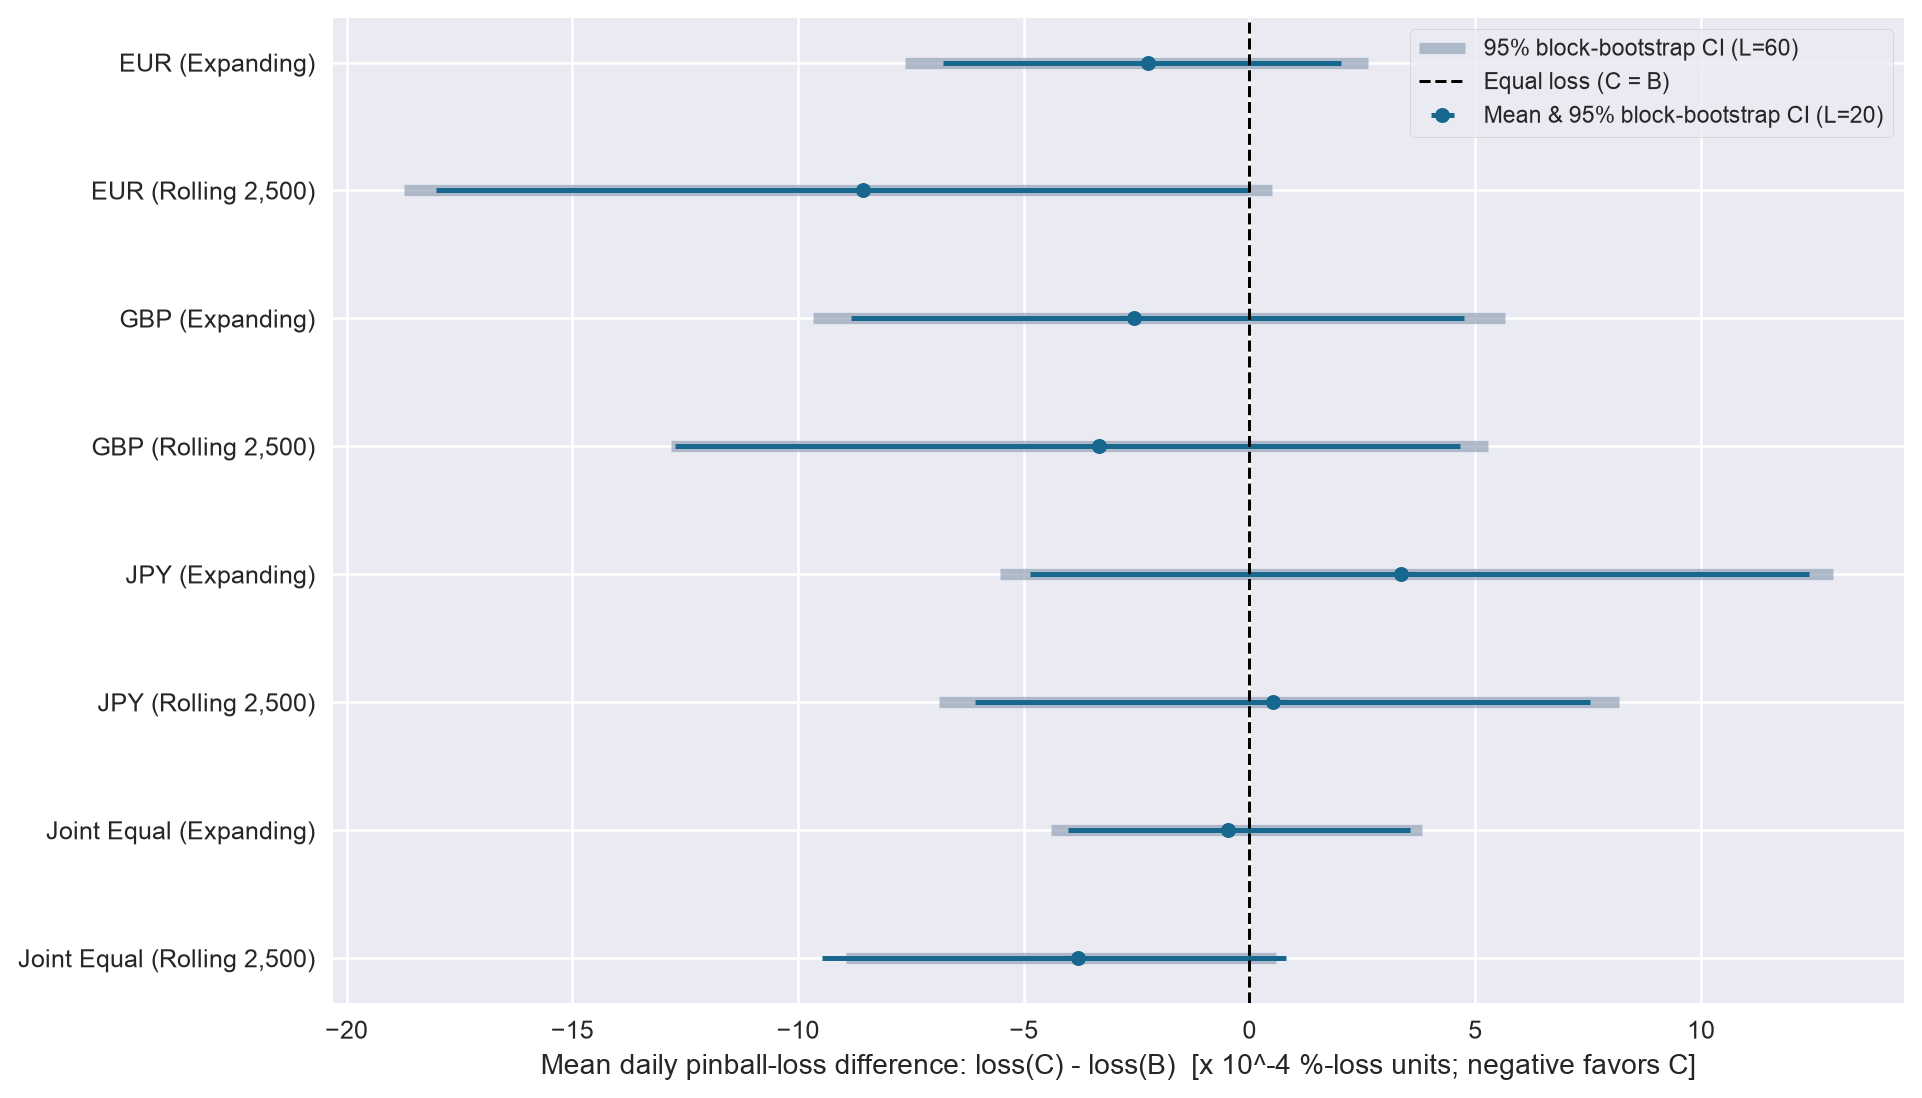

*Graph 10. Mean daily pinball-loss difference loss(C)-loss(B) at p=0.01 across EUR, GBP, JPY and equal-weight common-date joint series for expanding and rolling-2,500 windows (scaled by 10^4).*

Comparing expanding and rolling-2,500 windows alongside L=20 and L=60 block lengths exposes whether any incremental gain from updating gamma survives nonstationary history rules and wider dependence blocks.

In [22]:
cb_p01 = result["contrast_df"].query("p == 0.01 and contrast_code == 'C_minus_B'").copy()
order_keys = [
    ("EUR", "expanding", "EUR (Expanding)"),
    ("EUR", f"rolling_{CFG.rolling_window}", "EUR (Rolling 2,500)"),
    ("GBP", "expanding", "GBP (Expanding)"),
    ("GBP", f"rolling_{CFG.rolling_window}", "GBP (Rolling 2,500)"),
    ("JPY", "expanding", "JPY (Expanding)"),
    ("JPY", f"rolling_{CFG.rolling_window}", "JPY (Rolling 2,500)"),
    ("JOINT_EQUAL", "expanding", "Joint Equal (Expanding)"),
    ("JOINT_EQUAL", f"rolling_{CFG.rolling_window}", "Joint Equal (Rolling 2,500)"),
]
rows_plot = []
for s_code, w_code, lbl in order_keys:
    r = cb_p01.loc[(cb_p01["series"] == s_code) & (cb_p01["window"] == w_code)].iloc[0]
    rows_plot.append(dict(label=lbl, **r.to_dict()))
cb_plot_df = pd.DataFrame(rows_plot)

def plot_cb_forest(ax):
    y_pos = np.arange(len(cb_plot_df))[::-1]
    scale = 1e4
    means = cb_plot_df["mean_diff"].to_numpy() * scale
    lo20 = cb_plot_df["ci20_low"].to_numpy() * scale
    hi20 = cb_plot_df["ci20_high"].to_numpy() * scale
    lo60 = cb_plot_df["ci60_low"].to_numpy() * scale
    hi60 = cb_plot_df["ci60_high"].to_numpy() * scale
    ax.hlines(y_pos, lo60, hi60, color="#94a3b8", linewidth=4.5, alpha=0.7, label="95% block-bootstrap CI (L=60)")
    ax.errorbar(
        means,
        y_pos,
        xerr=np.vstack([means - lo20, hi20 - means]),
        fmt="o",
        color=CFG.colors["raw"],
        ecolor=CFG.colors["raw"],
        elinewidth=2.0,
        capsize=4,
        markersize=6,
        label="Mean & 95% block-bootstrap CI (L=20)",
    )
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1.2, label="Equal loss (C = B)")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(cb_plot_df["label"])
    ax.set_xlabel("Mean daily pinball-loss difference: loss(C) - loss(B)  [x 10^-4 %-loss units; negative favors C]")
    ax.legend(loc="best", frameon=True, fontsize=9.2)

manifest = publish(
    "graph",
    10,
    "Updating tail shape (Arm C minus Arm B) across windows and currencies",
    "What does updating shape add?",
    "Mean daily pinball-loss difference loss(C)-loss(B) at p=0.01 across EUR, GBP, JPY and equal-weight common-date joint series for expanding and rolling-2,500 windows (scaled by 10^4).",
    "Horizontal interval plot showing Arm C minus Arm B mean pinball-loss differences and L=20 and L=60 moving-block bootstrap 95 percent intervals across eight currency-window combinations.",
    "Comparing expanding and rolling-2,500 windows alongside L=20 and L=60 block lengths exposes whether any incremental gain from updating gamma survives nonstationary history rules and wider dependence blocks.",
    manifest,
    plot=plot_cb_forest,
    sidecar=cb_plot_df,
)

Comparing $\text{loss}(C) - \text{loss}(B)$ (in units of $10^{-4}$ percentage-loss points) across all eight currency-window combinations at $p = 0.01$ shows that every 95% moving-block interval ($L = 20$ and $L = 60$) crosses zero:

- **Expanding window**: Point differences are slightly negative on `EUR` (`-2.24e-4`), `GBP` (`-1.99e-4`), and `Joint Equal` (`-0.88e-4`), but positive on `JPY` (`+1.58e-4`, favoring fixed 2008 shape).
- **Rolling 2,500-day window**: Capping the estimation memory at `2,500` days shrinks `EUR`'s point difference to near zero (`-0.015e-4`), while `GBP` (`-2.16e-4`) and `JPY` (`-1.26e-4`) stay well within their bootstrap uncertainty bands.

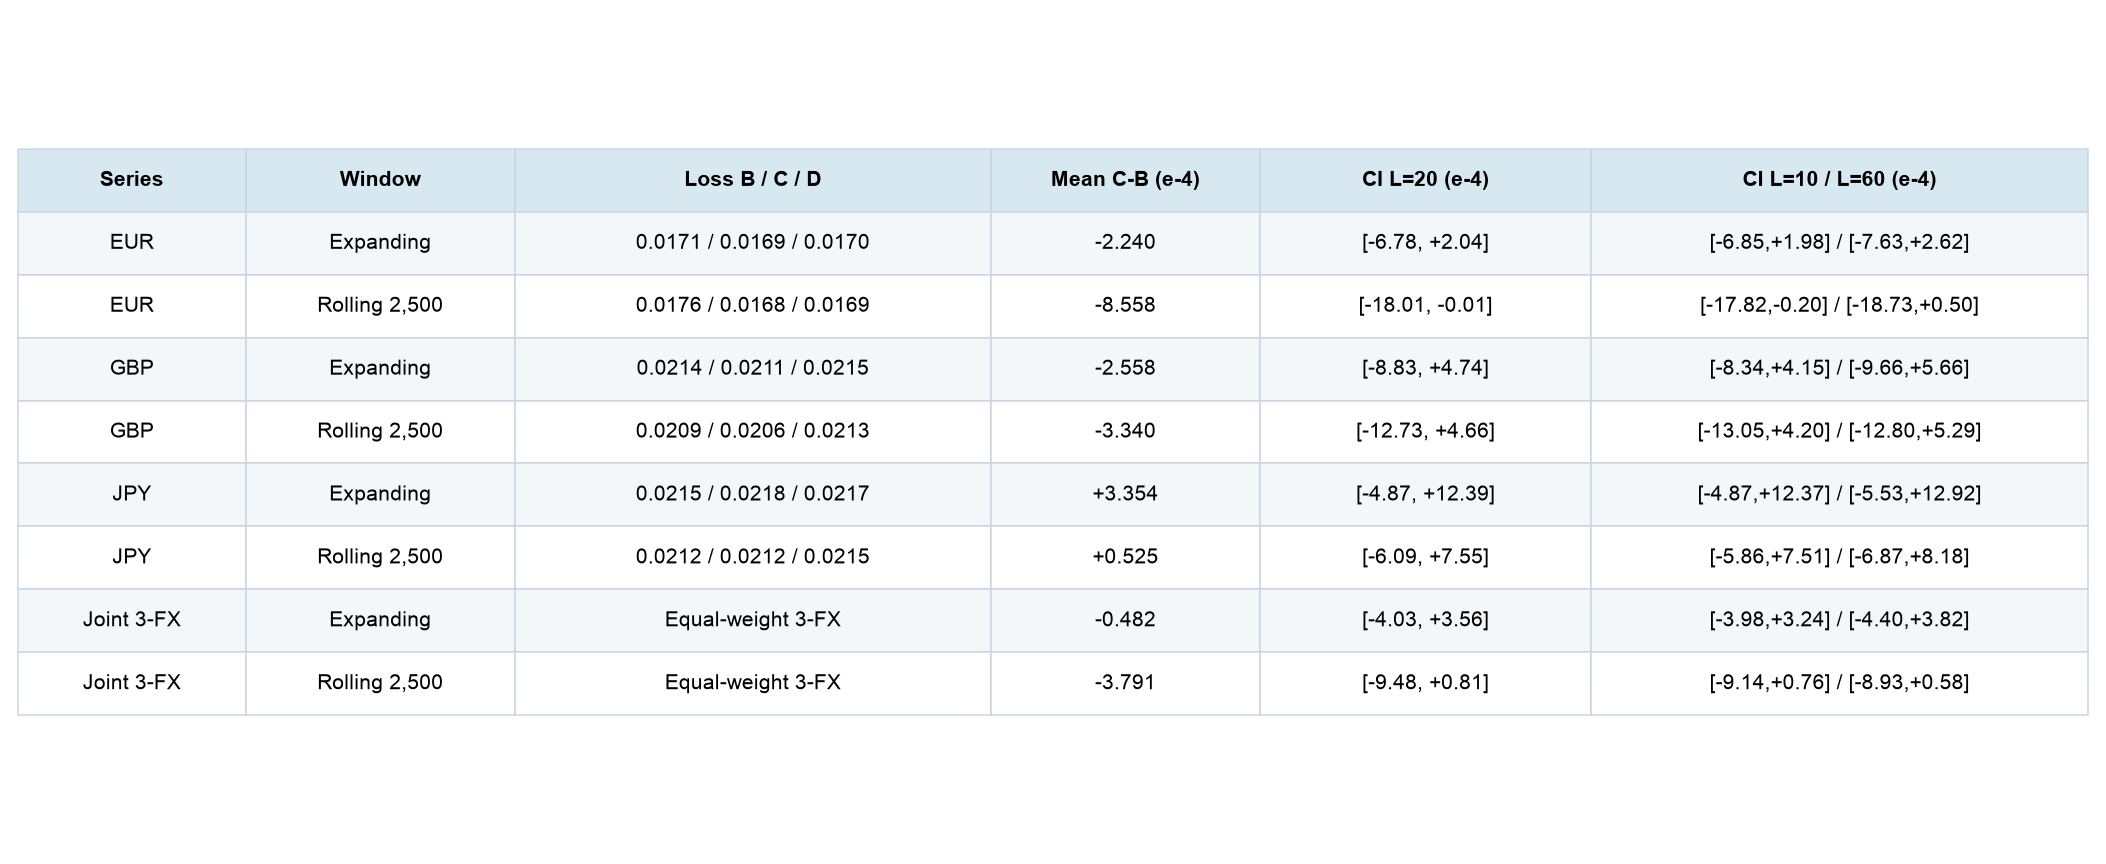

*Table 11. Pinball losses for Arms B, C and D and paired C-minus-B moving-block bootstrap intervals (L=20, 10, 60; 5,000 resamples) across EUR, GBP, JPY and the 4,253-date joint panel.*

All supporting series, window designs and block-length intervals are retained without cherry-picking; moving-block intervals remain approximate conditional summaries on correlated USD exchange rates.

In [23]:
sup_rows = []
for s_code in ("EUR", "GBP", "JPY", "JOINT_EQUAL"):
    for w_code, w_lbl in (("expanding", "Expanding"), (f"rolling_{CFG.rolling_window}", "Rolling 2,500")):
        r = cb_p01.loc[(cb_p01["series"] == s_code) & (cb_p01["window"] == w_code)].iloc[0]
        if s_code != "JOINT_EQUAL":
            sc_b = result["score_df"].query("series == @s_code and window == @w_code and p == 0.01 and arm_code == 'B_dyn_thresh'").iloc[0]
            sc_c = result["score_df"].query("series == @s_code and window == @w_code and p == 0.01 and arm_code == 'C_dyn_both'").iloc[0]
            sc_d = result["score_df"].query("series == @s_code and window == @w_code and p == 0.01 and arm_code == 'D_rect_hill'").iloc[0]
            b_c_d_str = f"{sc_b['mean_pinball_loss']:.4f} / {sc_c['mean_pinball_loss']:.4f} / {sc_d['mean_pinball_loss']:.4f}"
        else:
            b_c_d_str = "Equal-weight 3-FX"
        sup_rows.append(
            {
                "Series": "Joint 3-FX" if s_code == "JOINT_EQUAL" else s_code,
                "Window": w_lbl,
                "Loss B / C / D": b_c_d_str,
                "Mean C-B (e-4)": f"{r['mean_diff'] * 1e4:+.3f}",
                "CI L=20 (e-4)": f"[{r['ci20_low'] * 1e4:+.2f}, {r['ci20_high'] * 1e4:+.2f}]",
                "CI L=10 / L=60 (e-4)": f"[{r['ci10_low'] * 1e4:+.2f},{r['ci10_high'] * 1e4:+.2f}] / [{r['ci60_low'] * 1e4:+.2f},{r['ci60_high'] * 1e4:+.2f}]",
            }
        )
sup_view = pd.DataFrame(sup_rows)
manifest = publish(
    "table",
    11,
    "Supporting currency, window and block-length forecast summary (p=0.01)",
    "What does updating shape add?",
    "Pinball losses for Arms B, C and D and paired C-minus-B moving-block bootstrap intervals (L=20, 10, 60; 5,000 resamples) across EUR, GBP, JPY and the 4,253-date joint panel.",
    "Eight-row forecast comparison table for EUR, GBP, JPY and joint 3-FX across expanding and rolling-2,500 windows.",
    "All supporting series, window designs and block-length intervals are retained without cherry-picking; moving-block intervals remain approximate conditional summaries on correlated USD exchange rates.",
    manifest,
    table=sup_view,
    sidecar=result["contrast_df"],
    table_height=4.9,
    col_widths=[0.11, 0.13, 0.23, 0.13, 0.16, 0.24],
    font_size=8.6,
)

Table 11 lists the `Loss B / C / D` levels and paired `C - B` moving-block intervals across all three block lengths ($L = 20, 10, 60$). Varying $L$ from `10` to `60` days alters interval widths modestly without changing any conclusion, and Epanechnikov-weighted `Arm C` and rectangular `Arm D` perform nearly identically (`0.0205` vs. `0.0206` on `EUR`, `0.0226` vs. `0.0226` on `GBP`, `0.0233` vs. `0.0233` on `JPY`).

# Robustness and remaining uncertainty

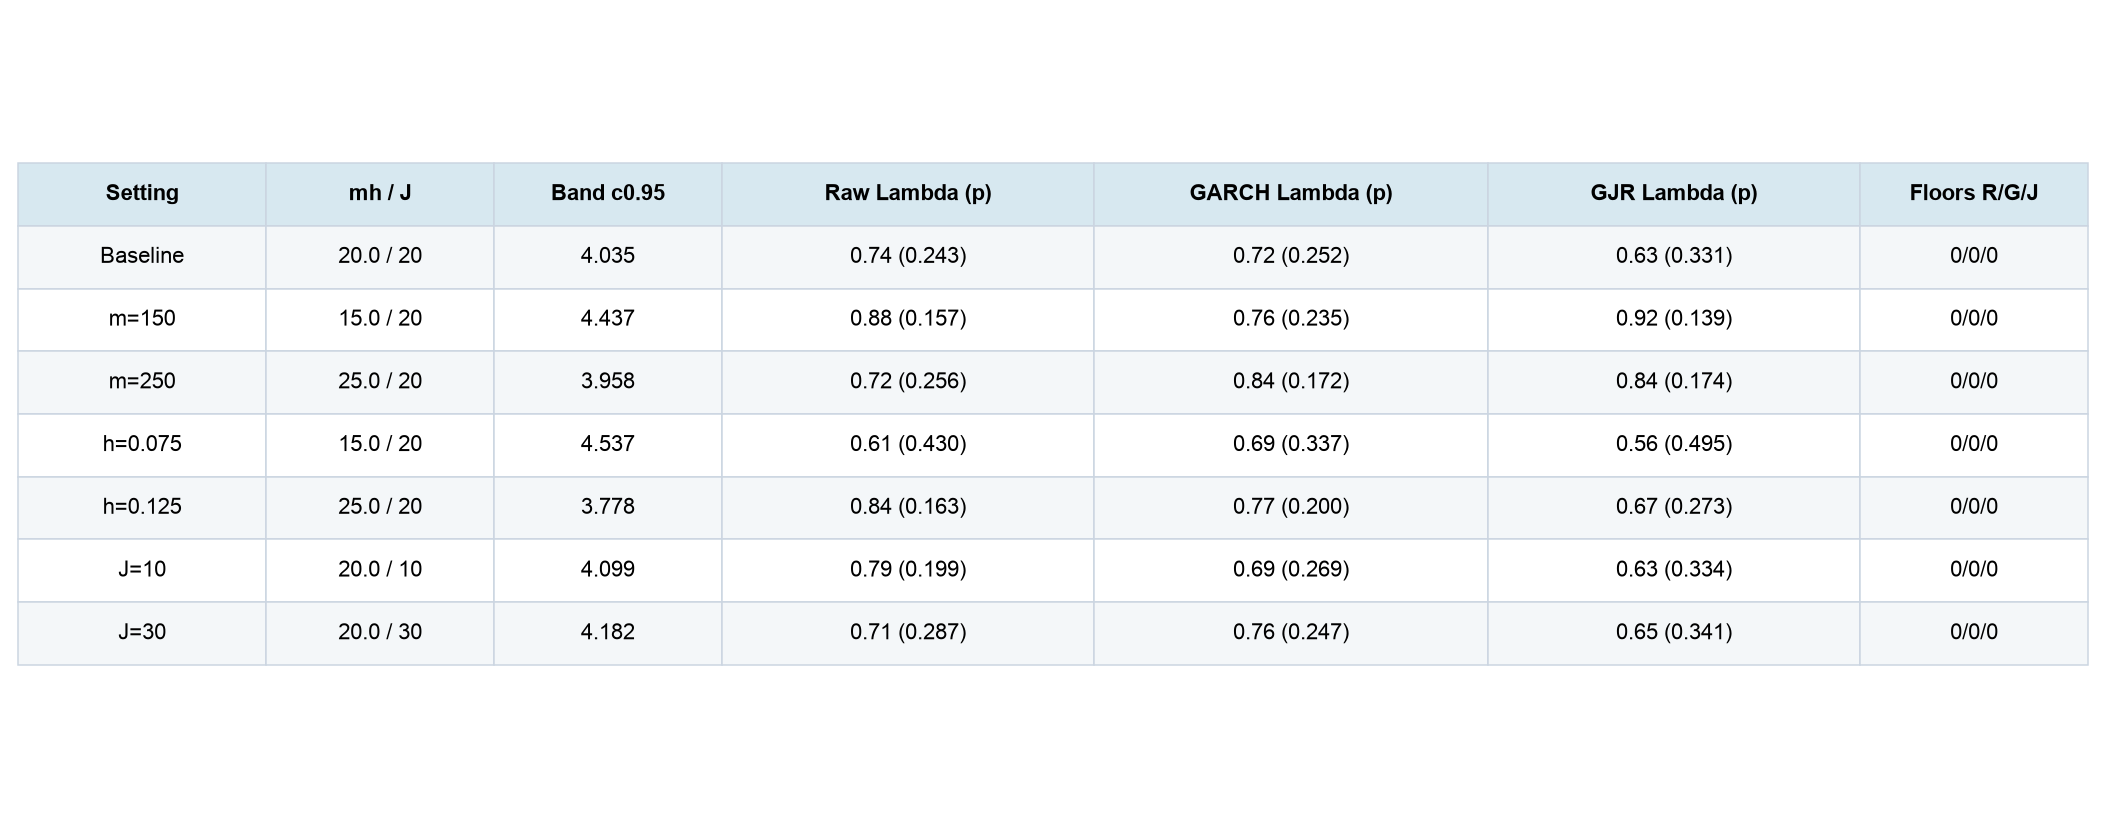

*Table 12. Baseline and six one-factor EUR/USD perturbations on [0.15, 0.85], each recalibrated with 5,000 independent Pareto draws; p-values are descriptive outside the 9-test Holm family.*

Changing m, h or J shifts finite-sample studentization and critical values noticeably—especially when J=30 approaches or exceeds mh—confirming why single-bandwidth curves must not be over-interpreted.

In [24]:
rob = result["rob_df"]
rob_table_rows = []
for label, m_val, h_val, j_val in CFG.eur_robustness:
    sub = rob.loc[rob["setting"] == label].set_index("target_key")
    c95_val = sub.loc["raw", "c_95"]
    fl_str = f"{int(sub.loc['raw','floor_count'])}/{int(sub.loc['garch','floor_count'])}/{int(sub.loc['gjr','floor_count'])}"
    rob_table_rows.append(
        {
            "Setting": label,
            "mh / J": f"{m_val * h_val:.1f} / {j_val}",
            "Band c0.95": f"{c95_val:.3f}",
            "Raw Lambda (p)": f"{sub.loc['raw','lambda_stat']:.2f} ({sub.loc['raw','p_descriptive']:.3f})",
            "GARCH Lambda (p)": f"{sub.loc['garch','lambda_stat']:.2f} ({sub.loc['garch','p_descriptive']:.3f})",
            "GJR Lambda (p)": f"{sub.loc['gjr','lambda_stat']:.2f} ({sub.loc['gjr','p_descriptive']:.3f})",
            "Floors R/G/J": fl_str,
        }
    )
rob_view = pd.DataFrame(rob_table_rows)
manifest = publish(
    "table",
    12,
    "EUR/USD interior stability sensitivity across m, h and HAC lag J",
    "Robustness and remaining uncertainty",
    "Baseline and six one-factor EUR/USD perturbations on [0.15, 0.85], each recalibrated with 5,000 independent Pareto draws; p-values are descriptive outside the 9-test Holm family.",
    "Seven-row robustness table showing recalibrated band cutoffs, Lambda_n statistics, descriptive p-values and HAC floor counts across raw, GARCH and GJR targets on EUR/USD.",
    "Changing m, h or J shifts finite-sample studentization and critical values noticeably—especially when J=30 approaches or exceeds mh—confirming why single-bandwidth curves must not be over-interpreted.",
    manifest,
    table=rob_view,
    sidecar=rob,
    table_height=4.7,
    col_widths=[0.12, 0.11, 0.11, 0.18, 0.19, 0.18, 0.11],
    font_size=8.8,
)

Across all six one-factor perturbations of $(m, h, J)$ on `EUR/USD`—each recalibrated against its own `5,000`-draw Pareto cache—descriptive pivotal $p$-values stay between `0.139` and `0.495` across raw, GARCH, and GJR targets (`0/0/0` floor activations throughout). Notice how strongly the finite-sample simultaneous band multiplier $c_{0.95}$ varies with effective tail sample size $mh$ and Bartlett lag $J$ (`3.778` at `h = 0.125` up to `4.537` at `h = 0.075`), illustrating why asymptotic Gaussian critical values cannot substitute for finite-sample pivotal calibration.

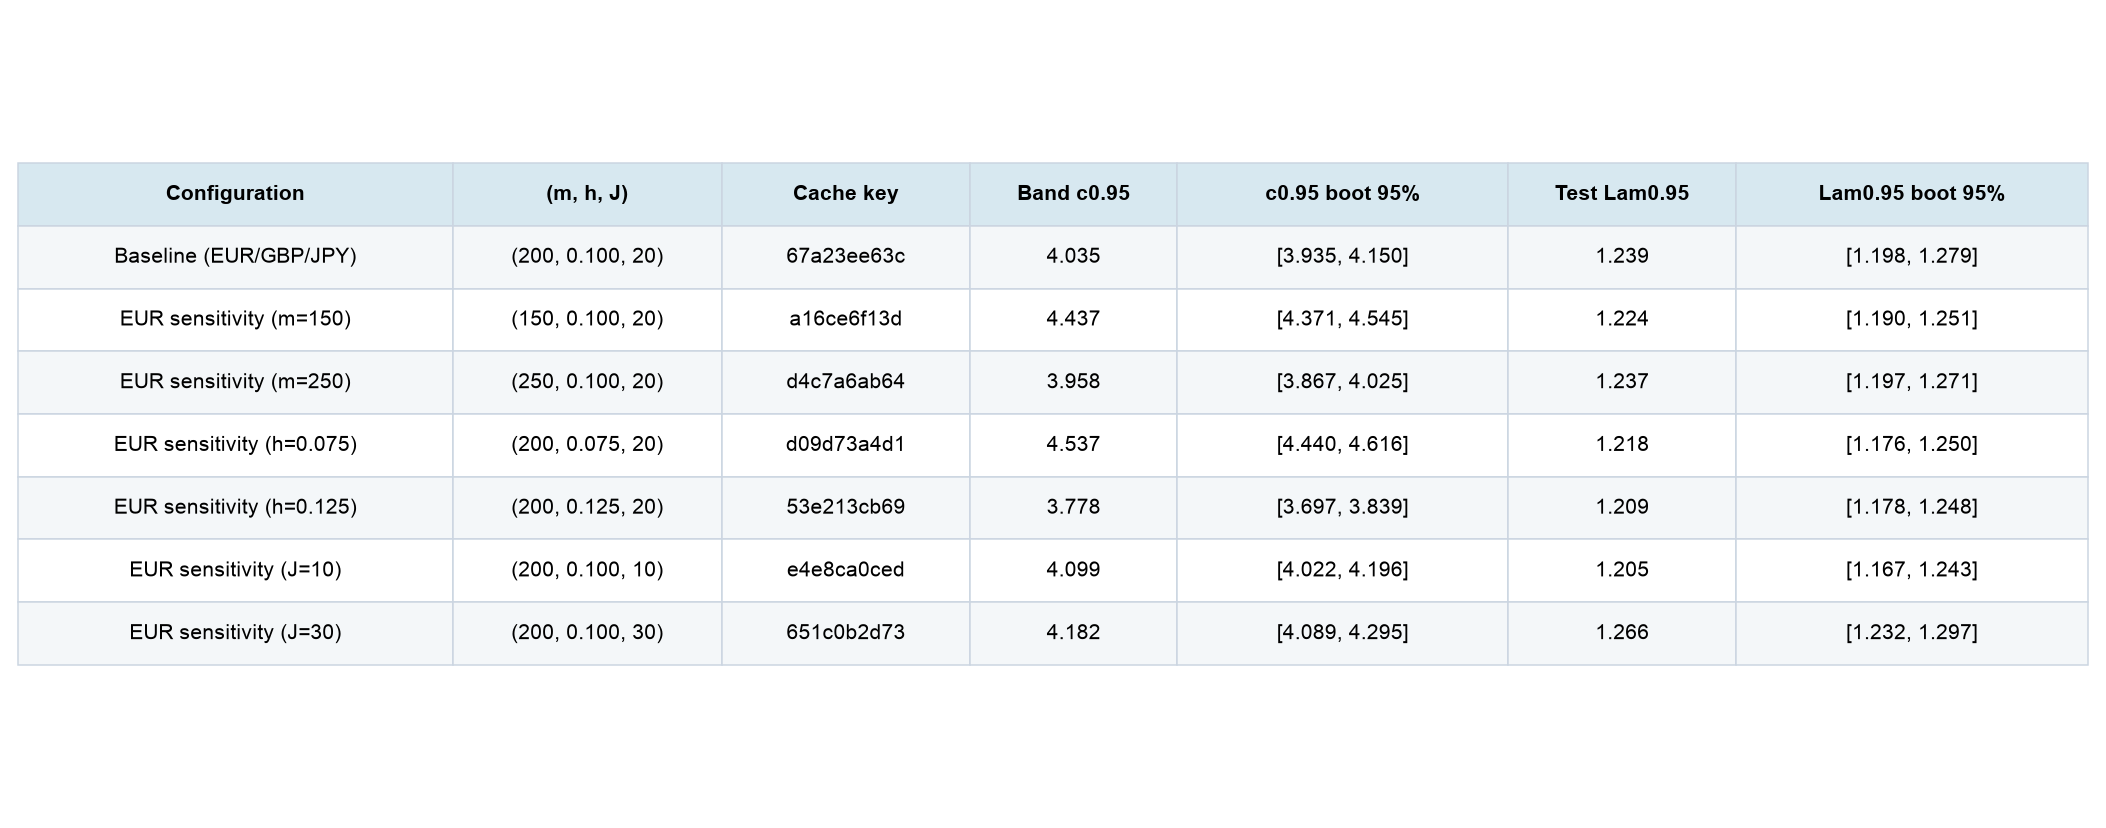

*Table 13. Seven hashed 5,000-draw Pareto calibration caches (35,000 paths total) with 1,000-bootstrap 95% cutoff intervals; live run completed in 1.82s with 0 filter and 0 forecast failures.*

With 5,000 pivotal draws per configuration, Monte Carlo uncertainty in c_0.95 and Lambda_0.95 is tight relative to empirical sampling noise; zero filter or forecast origins were dropped.

{'live_run': 'runs/20261107T155047630280+0100', 'live_total_seconds': 1.818, 'stage_seconds': {'pivotal_calibration': 0.009, 'retrospective_inference': 0.529, 'past_only_forecasting': 1.147}, 'max_rss_mib': 238.3, 'failed_filters': 0, 'failed_forecasts': 0, 'exported_assets': 13, 'mode': 'replay'}


In [25]:
cal_df = result["cal_df"]
rec = result["record"]
cal_view = pd.DataFrame(
    {
        "Configuration": cal_df["label"],
        "(m, h, J)": cal_df.apply(lambda r: f"({int(r['m'])}, {r['h']:.3f}, {int(r['J'])})", axis=1),
        "Cache key": cal_df["short_key"].str.slice(0, 10),
        "Band c0.95": cal_df["c_95"].map(lambda v: f"{v:.3f}"),
        "c0.95 boot 95%": cal_df.apply(lambda r: f"[{r['c_95_boot_low']:.3f}, {r['c_95_boot_high']:.3f}]", axis=1),
        "Test Lam0.95": cal_df["lambda_95"].map(lambda v: f"{v:.3f}"),
        "Lam0.95 boot 95%": cal_df.apply(lambda r: f"[{r['lambda_95_boot_low']:.3f}, {r['lambda_95_boot_high']:.3f}]", axis=1),
    }
)
manifest = publish(
    "table",
    13,
    "Pivotal calibration cutoffs (B=5,000) and cutoff bootstrap uncertainty",
    "Robustness and remaining uncertainty",
    f"Seven hashed 5,000-draw Pareto calibration caches (35,000 paths total) with 1,000-bootstrap 95% cutoff intervals; live run completed in {rec['total_seconds']:.2f}s with {rec['failed_filters']} filter and {rec['failed_forecasts']} forecast failures.",
    "Seven-row table listing calibration configurations, short SHA-256 keys, band critical values c_0.95, omnibus critical values Lambda_0.95 and their 95 percent bootstrap intervals.",
    "With 5,000 pivotal draws per configuration, Monte Carlo uncertainty in c_0.95 and Lambda_0.95 is tight relative to empirical sampling noise; zero filter or forecast origins were dropped.",
    manifest,
    table=cal_view,
    sidecar=cal_df,
    table_height=4.7,
    col_widths=[0.21, 0.13, 0.12, 0.10, 0.16, 0.11, 0.17],
    font_size=8.6,
)
print(
    {
        "live_run": result["path"],
        "live_total_seconds": round(rec["total_seconds"], 3),
        "stage_seconds": {k: round(v, 3) for k, v in rec["stage_seconds"].items()},
        "max_rss_mib": round(rec["max_rss_bytes"] / (2**20), 1),
        "failed_filters": rec["failed_filters"],
        "failed_forecasts": rec["failed_forecasts"],
        "exported_assets": len(manifest),
        "mode": CFG.mode,
    }
)

Table 13 reports the 95% critical values ($c_{0.95}$ and $\Lambda_{0.95}$) and their `1,000`-bootstrap confidence intervals across all seven `5,000`-draw Pareto calibration caches (`35,000` simulated paths total), followed by the runtime summary for `CFG.run_folder` (`0` failed volatility filters, `0` dropped forecast origins, all 13 assets exported).